## 1. Imports

In [1]:
import sys
from pathlib import Path

# Add parent directory (where utility.py lives) to the path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from utility import _feature_engineering, setpoint_df, FeatureCreator
from config import CONTROL_VARS
from data_cleaning import (
    unique_in_order, ordered_difference, ordered_intersection,
)

from tigramite import data_processing as pp
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr  # Changed import path

sns.set(rc={"figure.figsize": (12, 4)})
sns.set_style("whitegrid")
sns.set_context("notebook")

## 2. Configuration

In [2]:
Y_COLUMN = "MBS_SCT_CD"

DATA_PATH = "../data/costimiser_turnup.parquet"

CREATED_VARIABLE_CANDIDATES = [
    "delta_basis_weight",
    "Starch_uptake__g/m2_",
    "Water_flow_Predryer",
    "Water_flow_Afterdryer",
    "Water_flow",
    "flow_diluted_starch",
    "Fibre__g/m2_",
    "Water_flow_Afterdryer_input", 
    "Water_flow_Afterdryer_output",
    "dewatering",
    "fibre_short/long"
]

## 3. Data Loading & Filtering

In [ ]:
# Load raw data
turnup_data = pd.read_parquet(DATA_PATH)

ctl_vars = unique_in_order(
    v for v in CONTROL_VARS[Y_COLUMN] if "vacuum" not in v.lower()
)
created_vars = ordered_intersection(CREATED_VARIABLE_CANDIDATES, ctl_vars)

turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index("Wedge_Time").sort_index()

if len(created_vars)>0:
    fc = FeatureCreator(features_to_create=created_vars, features_to_keep= list(set(turnup_data.columns.to_list()+created_vars)))
    turnup_data = fc.fit_transform(turnup_data)
    fr = fc.features_required()
else:
    fr=[]

var_names = [Y_COLUMN] +  unique_in_order(ordered_difference(ctl_vars, created_vars) + fr)
data_array = turnup_data[var_names].dropna().values
dataframe = pp.DataFrame(data_array, var_names=var_names)



In [59]:
CONTROL_VARS[Y_COLUMN]

['retention',
 'grammage',
 'delta_basis_weight',
 'Speed',
 'Moisture_after_SpeedSizer',
 'Current_reel_moisture_average(reel)',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Viscosity_for_working_tank_bottom_roll',
 'Starch_uptake__g/m2_',
 'Consistency_starch_main_line',
 'Draw_PD5-SS',
 'Draw_AD7-PR',
 'Draw_AD6-AD7',
 'Draw_PD4-PD5',
 'Draw_WS-PS',
 'Draw_PD1-PD2',
 'Draw_PD3-PD4',
 'Draw_SS-AD6',
 'Draw_PS-PD1',
 'Draw_PD2-PD3',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_shoe_press__bar_',
 'pH_measurement_white_water_B41',
 'Headbox_consistency',
 'Lip_settings',
 'Jet/wire_ratio',
 'Retention_Aid_mass_flow__g/T_',
 'Bentonite_1_mass_flow__g/T_',
 'Bentonite_2_mass_flow__g/T_',
 'CO2_mass_flow__g/T_',
 'fibre_short/long',
 'White_water_temperature',
 'Conductivity_white_water_B46',
 'pH_measurement_white_water_B41',
 'Current_reel_width']

<Axes: xlabel='Speed', ylabel='CO2_mass_flow__g/T_'>

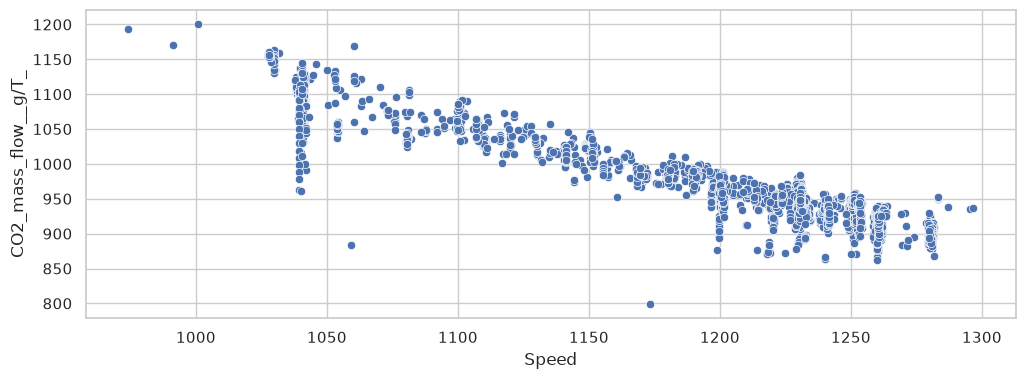

In [61]:
sns.scatterplot(turnup_data[turnup_data.grammage==120], x="Speed", y='CO2_mass_flow__g/T_')

In [41]:
dZ = pd.read_parquet("../data/dZ.parquet")
var_names = [Y_COLUMN] + [v for v in dZ.columns if v!=Y_COLUMN]
data_array = dZ[var_names].dropna().values
dataframe = pp.DataFrame(data_array, var_names=var_names)

In [4]:
print("Rows:", data_array.shape[0])
print("Variables:", data_array.shape[1])
print("Memory data_array [MB]:", data_array.nbytes / 1024**2)

Rows: 8760
Variables: 43
Memory data_array [MB]: 2.87384033203125


In [21]:
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr
import tigramite.plotting as tp
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Conditional-independence test
# ------------------------------------------------------------
parcorr = ParCorr(significance="analytic")
parcorr.set_dataframe(dataframe)


# ------------------------------------------------------------
# 2. PCMCI object
# ------------------------------------------------------------
pcmci = PCMCI(
    dataframe=dataframe,
    cond_ind_test=parcorr,
    verbosity=1,
)


# ------------------------------------------------------------
# 3. Run PCMCI+
#
# tau_min = 0 allows contemporaneous relationships
# tau_max = 1 also allows previous-reel relationships
# ------------------------------------------------------------
results = pcmci.run_pcmciplus(
    tau_min=0,
    tau_max=0,
    pc_alpha=0.05,
    max_conds_dim=3,
)

# ------------------------------------------------------------
# 4. Inspect result matrices
# ------------------------------------------------------------
graph = results["graph"]
val_matrix = results["val_matrix"]
p_matrix = results["p_matrix"]

print("graph shape:", graph.shape)
print("val_matrix shape:", val_matrix.shape)
print("p_matrix shape:", p_matrix.shape)




##
## Step 1: PC1 algorithm for selecting lagged conditions
##

Parameters:
independence test = par_corr
tau_min = 1
tau_max = 0
pc_alpha = [0.05]
max_conds_dim = 3
max_combinations = 1



## Resulting lagged parent (super)sets:

    Variable MBS_SCT_CD has 0 link(s):

    Variable retention has 0 link(s):

    Variable grammage has 0 link(s):

    Variable Speed has 0 link(s):

    Variable Moisture_after_SpeedSizer has 0 link(s):

    Variable Current_reel_moisture_average(reel) has 0 link(s):

    Variable SpeedSizer_Linepressure_DS has 0 link(s):

    Variable SpeedSizer_Linepressure_FS has 0 link(s):

    Variable Viscosity_for_working_tank_bottom_roll has 0 link(s):

    Variable Consistency_starch_main_line has 0 link(s):

    Variable Draw_PD5-SS has 0 link(s):

    Variable Draw_AD7-PR has 0 link(s):

    Variable Draw_AD6-AD7 has 0 link(s):

    Variable Draw_PD4-PD5 has 0 link(s):

    Variable Draw_WS-PS has 0 link(s):

    Variable Draw_PD1-PD2 has 0 link(s):

    Variabl

# Some research

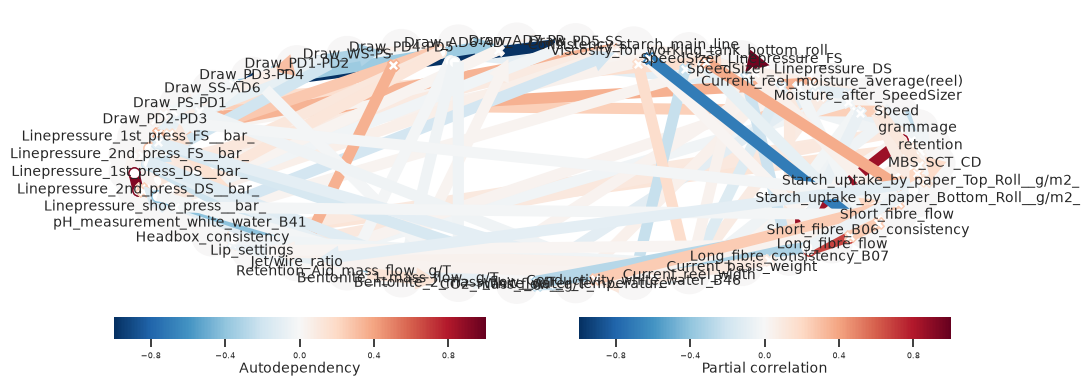

In [6]:
tp.plot_graph(
    graph=results["graph"],
    val_matrix=results["val_matrix"],
    var_names=var_names,
    link_colorbar_label="Partial correlation",
    node_colorbar_label="Autodependency",
)

plt.show()

In [7]:
import pandas as pd

TARGET = "MBS_SCT_CD"
target_idx = var_names.index(TARGET)

rows = []

graph = results["graph"]
val_matrix = results["val_matrix"]
p_matrix = results["p_matrix"]

for i, source in enumerate(var_names):
    for tau in range(graph.shape[2]):

        link = graph[i, target_idx, tau]

        if link != "":
            rows.append({
                "source": source,
                "lag": tau,
                "link": link,
                "strength": val_matrix[i, target_idx, tau],
                "p_value": p_matrix[i, target_idx, tau],
            })

parents = (
    pd.DataFrame(rows)
    .sort_values("strength", key=lambda x: x.abs(), ascending=False)
)

parents

,source,lag,link,strength,p_value
1,Current_basis_weight,0,x-x,0.206750,3.642261e-85
3,Starch_uptake_by_paper_Top_Roll__g/m2_,0,<--,0.180246,7.512934e-65
2,Starch_uptake_by_paper_Bottom_Roll__g/m2_,0,x-x,0.142441,6.320999e-41
0,Current_reel_moisture_average(reel),0,x-x,0.027552,9.921551e-03


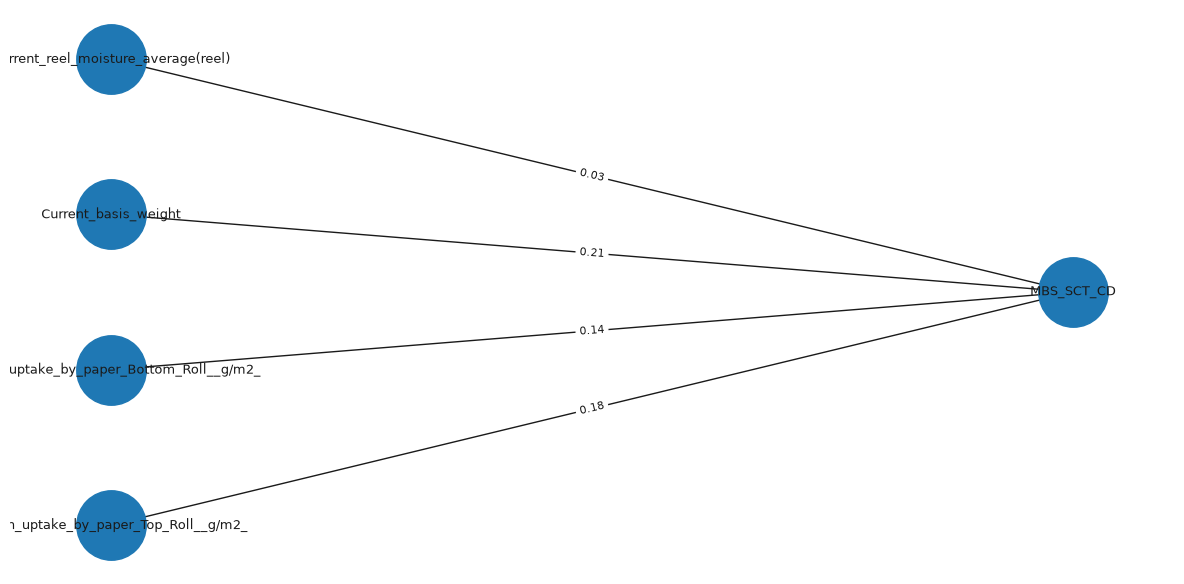

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

TARGET = "MBS_SCT_CD"
target_idx = var_names.index(TARGET)

G = nx.DiGraph()

G.add_node(TARGET)

for i, source in enumerate(var_names):
    for tau in range(graph.shape[2]):

        link = graph[i, target_idx, tau]

        if link == "":
            continue

        strength = val_matrix[i, target_idx, tau]

        if tau == 0:
            source_label = source
        else:
            source_label = f"{source}\n(t-{tau})"

        G.add_node(source_label)

        # For the moment, show every discovered relation
        # toward SCT as an incoming edge.
        G.add_edge(
            source_label,
            TARGET,
            weight=abs(strength),
            value=strength,
            link=link,
        )


# -----------------------------
# Layout: causes on left, SCT right
# -----------------------------
parents_nodes = [n for n in G.nodes if n != TARGET]

pos = {
    TARGET: (1, 0),
}

if parents_nodes:
    ys = range(len(parents_nodes))

    center = (len(parents_nodes) - 1) / 2

    for y, node in zip(ys, parents_nodes):
        pos[node] = (0, center - y)


plt.figure(figsize=(12, max(6, len(parents_nodes) * 0.45)))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2500,
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=20,
)

edge_labels = {
    (u, v): f"{d['value']:.2f}"
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8,
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
import networkx as nx

G_all = nx.DiGraph()

for i, source in enumerate(var_names):
    for j, target in enumerate(var_names):

        # contemporaneous links only for now
        link = graph[i, j, 0]
        if link == "-->":
            G_all.add_edge(
                source,
                target,
                value=val_matrix[i, j, 0],
            )

In [10]:
TARGET = "MBS_SCT_CD"
target_idx = var_names.index(TARGET)

for i, source in enumerate(var_names):
    if source == TARGET:
        continue

    for tau in range(graph.shape[2]):

        link = graph[i, target_idx, tau]

        if link != "":
            print(
                f"{source:45s} "
                f"tau={tau} "
                f"link={link!r:8s} "
                f"value={val_matrix[i, target_idx, tau]: .3f} "
                f"p={p_matrix[i, target_idx, tau]:.4g}"
            )

Current_reel_moisture_average(reel)           tau=0 link=np.str_('x-x') value= 0.028 p=0.009922
Current_basis_weight                          tau=0 link=np.str_('x-x') value= 0.207 p=3.642e-85
Starch_uptake_by_paper_Bottom_Roll__g/m2_     tau=0 link=np.str_('x-x') value= 0.142 p=6.321e-41
Starch_uptake_by_paper_Top_Roll__g/m2_        tau=0 link=np.str_('<--') value= 0.180 p=7.513e-65


In [11]:
import matplotlib.pyplot as plt
import networkx as nx

TARGET = "MBS_SCT_CD"
target_idx = var_names.index(TARGET)

G = nx.DiGraph()

G.add_node(TARGET)

edge_labels = {}
edge_styles = {}

for i, source in enumerate(var_names):
    if source == TARGET:
        continue

    for tau in range(graph.shape[2]):
        link = str(graph[i, target_idx, tau])

        if link == "":
            continue

        value = val_matrix[i, target_idx, tau]

        source_label = source if tau == 0 else f"{source} (t-{tau})"

        # Directed into SCT
        if link in ["-->", "o->"]:
            G.add_edge(source_label, TARGET)
            edge_styles[(source_label, TARGET)] = "directed"

        # Unresolved contemporaneous association
        elif link in ["x-x", "o-o"]:
            G.add_edge(source_label, TARGET)
            edge_styles[(source_label, TARGET)] = "unresolved"

        # PCMCI says SCT -> source
        elif link in ["<--", "<-o"]:
            G.add_edge(TARGET, source_label)
            edge_styles[(TARGET, source_label)] = "reverse"

        else:
            continue

        edge = list(G.edges)[-1]
        edge_labels[edge] = f"{value:.3f}"

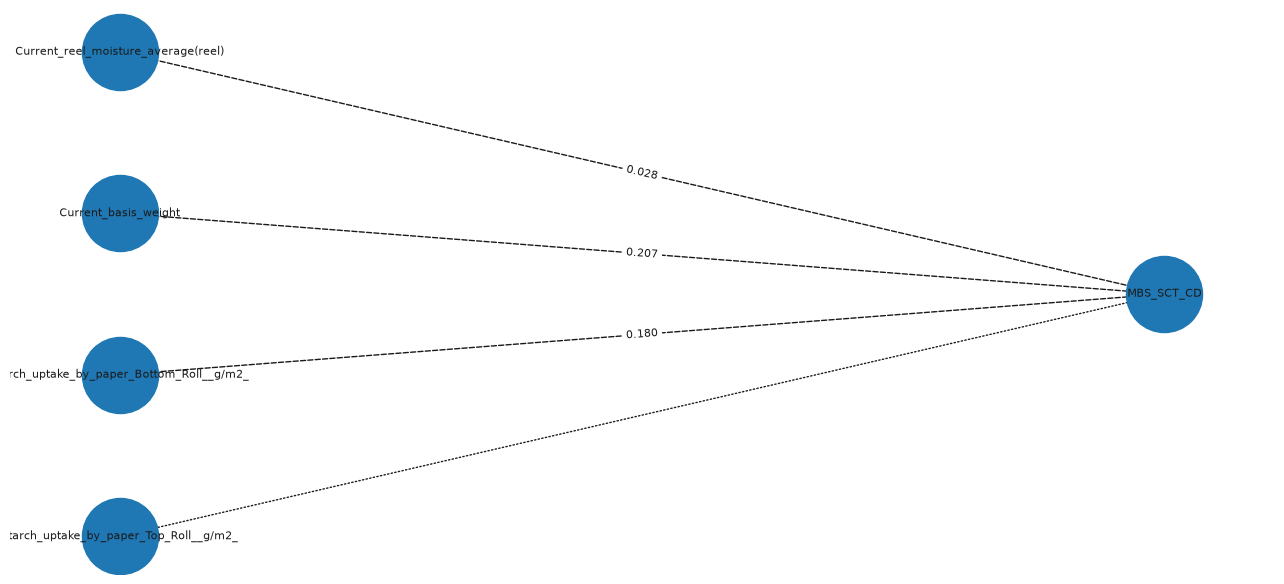

In [12]:
other_nodes = [n for n in G.nodes if n != TARGET]

pos = {TARGET: (1, 0)}

n = len(other_nodes)

for j, node in enumerate(other_nodes):
    y = (n - 1) / 2 - j
    pos[node] = (0, y)

plt.figure(figsize=(13, max(6, 0.7 * n)))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=3000,
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
)

# Draw each type separately
for edge_type, style in [
    ("directed", "solid"),
    ("unresolved", "dashed"),
    ("reverse", "dotted"),
]:
    edges = [
        e for e, t in edge_styles.items()
        if t == edge_type
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=edges,
        style=style,
        arrows=True,
        arrowsize=20,
    )

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8,
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [50]:
import networkx as nx

KG = nx.MultiDiGraph()

TARGET = "MBS_SCT_CD"

KG.add_node(
    TARGET,
    node_type="quality_property",
)

KG.add_node(
    "Current_basis_weight",
    node_type="process_variable",
)

KG.add_node(
    "Speed",
    node_type="control_variable",
)

KG.add_node(
    "Starch_uptake_by_paper_Top_Roll__g/m2_",
    node_type="process_state",
)

In [51]:
KG.add_edge(
    "Current_basis_weight",
    TARGET,
    relation="causal_evidence",
    method="PCMCI+",
    lag=1,
    strength=-0.040,
    p_value=0.0001744,
    orientation="directed",
)

KG.add_edge(
    "Speed",
    TARGET,
    relation="dependency",
    method="PCMCI+",
    lag=0,
    strength=-0.025,
    p_value=0.02059,
    orientation="unresolved",
)

KG.add_edge(
    "Starch_uptake_by_paper_Top_Roll__g/m2_",
    TARGET,
    relation="dependency",
    method="PCMCI+",
    lag=0,
    strength=0.054,
    p_value=3.653e-7,
    orientation="unresolved",
)

0

In [52]:
KG.add_edge(
    "Starch_uptake_by_paper_Top_Roll__g/m2_",
    TARGET,
    relation="possible_cause",
    source="process_expert",
    reason="starch is applied before final strength is measured",
)

1

In [53]:
nx.write_graphml(KG, "strength_knowledge_graph.graphml")

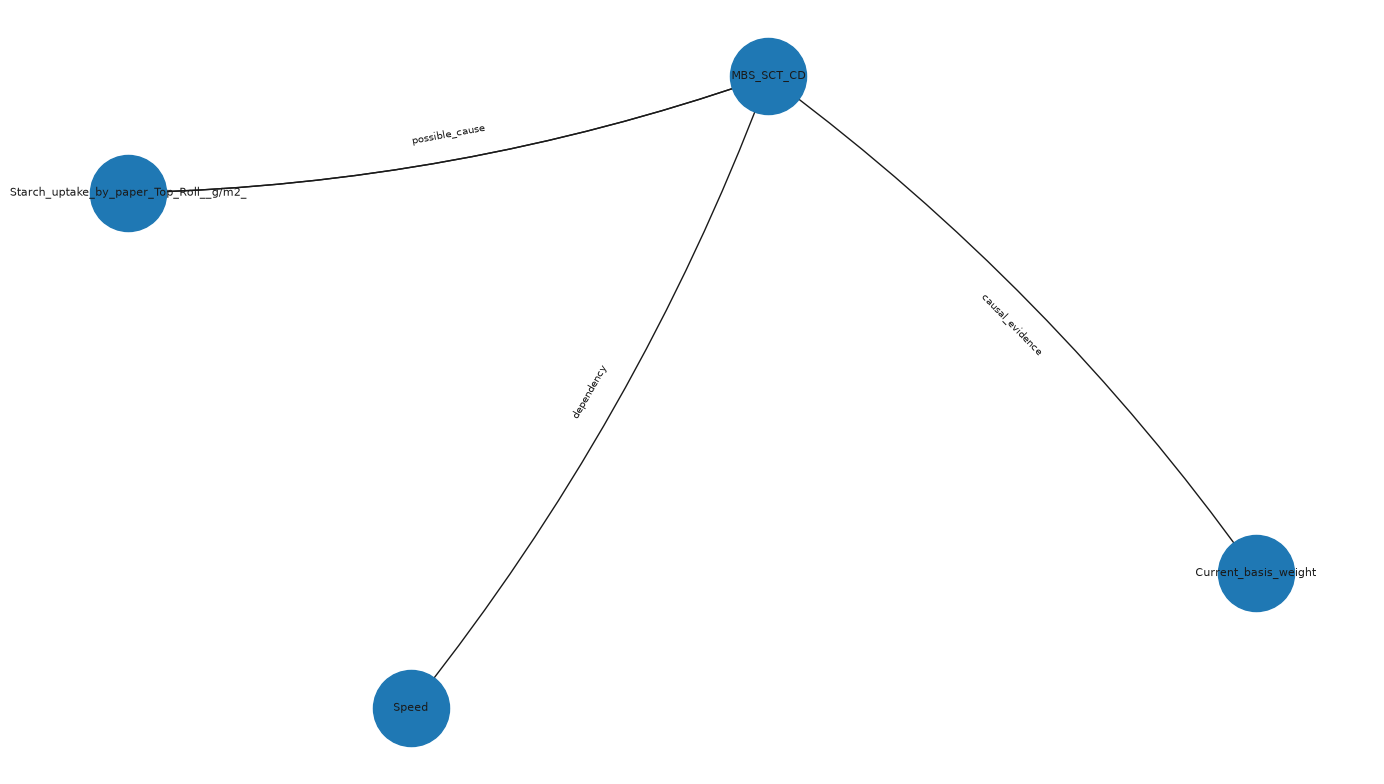

In [54]:
import matplotlib.pyplot as plt
import networkx as nx

TARGET = "MBS_SCT_CD"

# Keep target + nodes directly connected to it
nodes = {TARGET}

for u, v, data in KG.edges(data=True):
    if u == TARGET or v == TARGET:
        nodes.add(u)
        nodes.add(v)

G_plot = KG.subgraph(nodes).copy()

plt.figure(figsize=(14, 8))

pos = nx.spring_layout(
    G_plot,
    seed=42,
    k=1.8,
)

nx.draw_networkx_nodes(
    G_plot,
    pos,
    node_size=3000,
)

nx.draw_networkx_labels(
    G_plot,
    pos,
    font_size=8,
)

nx.draw_networkx_edges(
    G_plot,
    pos,
    arrows=True,
    arrowsize=20,
    connectionstyle="arc3,rad=0.08",
)

# Label edges with relation
edge_labels = {
    (u, v): data.get("relation", "")
    for u, v, data in G_plot.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_plot,
    pos,
    edge_labels=edge_labels,
    font_size=7,
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [30]:
edge_labels = {}

for u, v, key, data in G_plot.edges(keys=True, data=True):
    relation = data.get("relation", "")
    source = data.get("method", data.get("source", ""))

    label = relation

    if source:
        label += f"\n[{source}]"

    edge_labels[(u, v, key)] = label

In [31]:
G_display = nx.DiGraph()

for node, attrs in G_plot.nodes(data=True):
    G_display.add_node(node, **attrs)

for u, v, data in G_plot.edges(data=True):

    relation = data.get("relation", "")
    source = data.get("method", data.get("source", ""))

    label = relation
    if source:
        label += f"\n[{source}]"

    if G_display.has_edge(u, v):
        G_display[u][v]["label"] += "\n" + label
    else:
        G_display.add_edge(u, v, label=label)

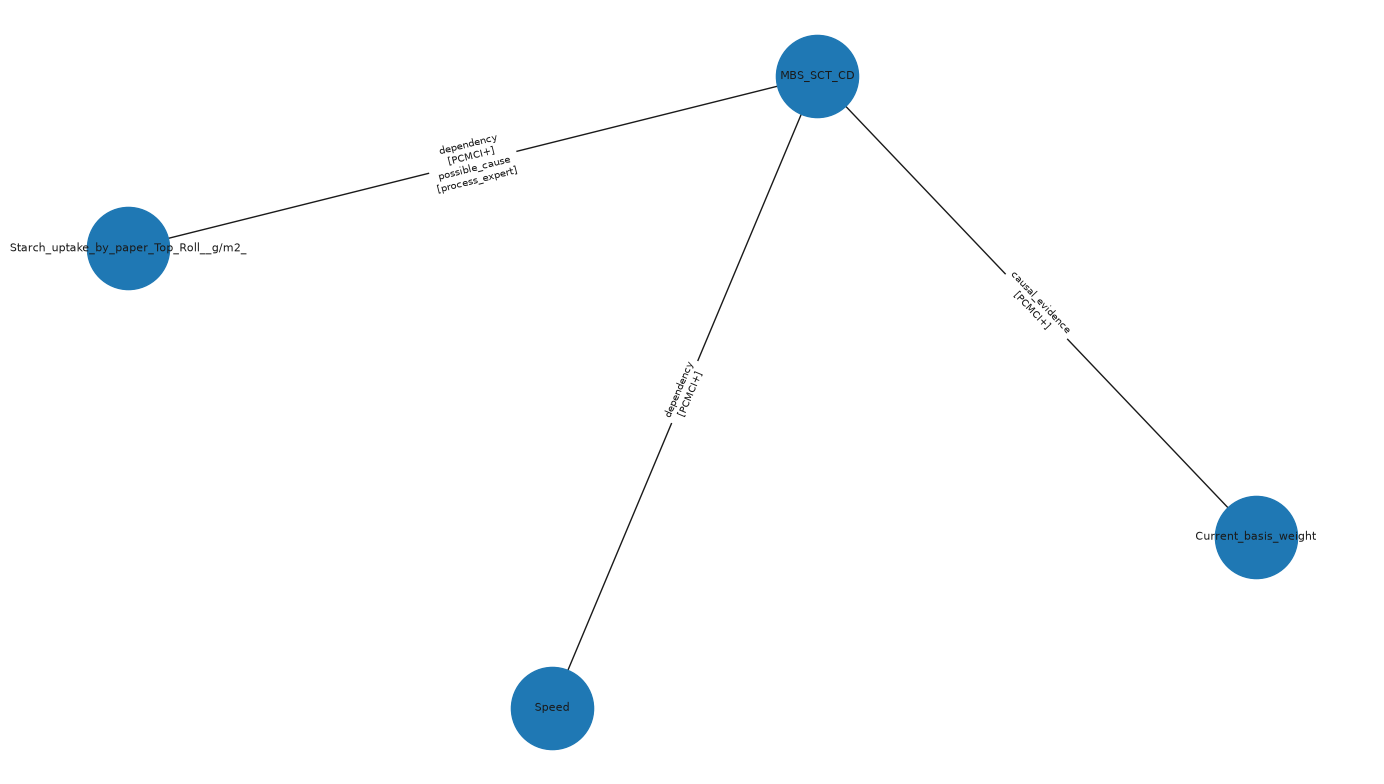

In [32]:
plt.figure(figsize=(14, 8))

pos = nx.spring_layout(
    G_display,
    seed=42,
    k=2.0,
)

nx.draw_networkx_nodes(
    G_display,
    pos,
    node_size=3500,
)

nx.draw_networkx_labels(
    G_display,
    pos,
    font_size=8,
)

nx.draw_networkx_edges(
    G_display,
    pos,
    arrows=True,
    arrowsize=20,
)

edge_labels = nx.get_edge_attributes(
    G_display,
    "label",
)

nx.draw_networkx_edge_labels(
    G_display,
    pos,
    edge_labels=edge_labels,
    font_size=7,
)

plt.axis("off")
plt.tight_layout()
plt.show()

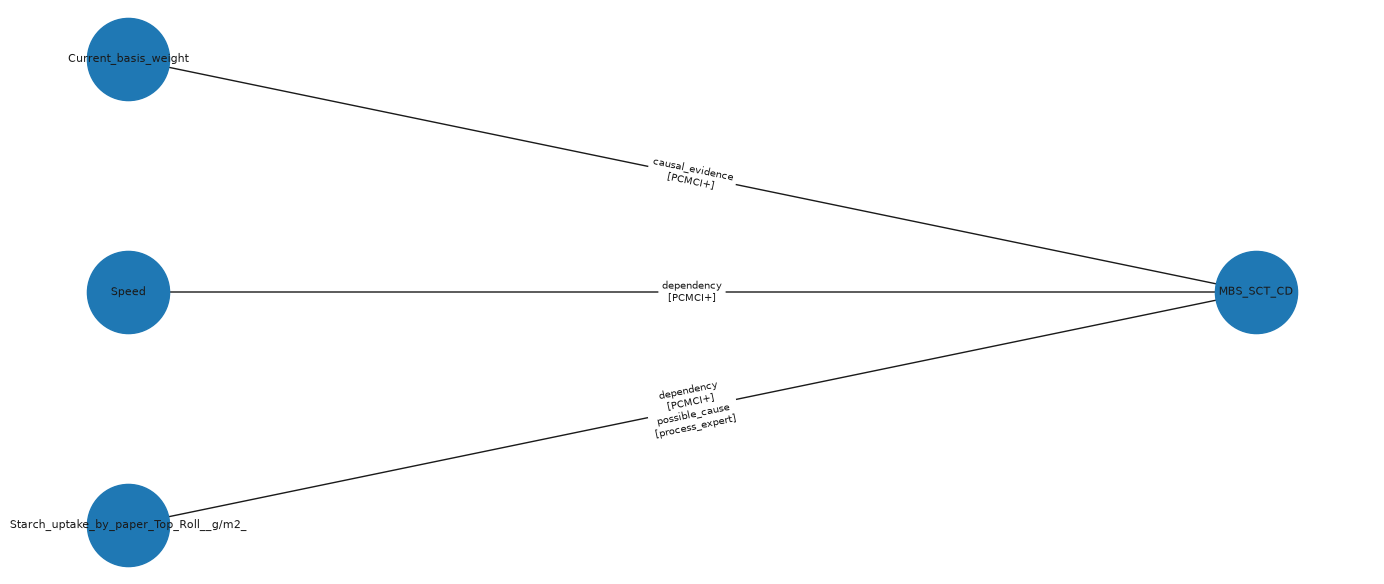

In [55]:
TARGET = "MBS_SCT_CD"

sources = [
    n for n in G_display.nodes
    if n != TARGET
]

pos = {
    TARGET: (1, 0)
}

for i, node in enumerate(sources):
    y = (len(sources) - 1) / 2 - i
    pos[node] = (0, y)

plt.figure(figsize=(14, max(6, len(sources) * 0.8)))

nx.draw_networkx_nodes(
    G_display,
    pos,
    node_size=3500,
)

nx.draw_networkx_labels(
    G_display,
    pos,
    font_size=8,
)

nx.draw_networkx_edges(
    G_display,
    pos,
    arrows=True,
    arrowsize=20,
)

nx.draw_networkx_edge_labels(
    G_display,
    pos,
    edge_labels=nx.get_edge_attributes(G_display, "label"),
    font_size=7,
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [58]:
print("Edges in KG:", KG.number_of_edges())

for u, v, data in KG.edges(data=True):
    print(u, "->", v, data)

Edges in KG: 4
Current_basis_weight -> MBS_SCT_CD {'relation': 'causal_evidence', 'method': 'PCMCI+', 'lag': 1, 'strength': -0.04, 'p_value': 0.0001744, 'orientation': 'directed'}
Speed -> MBS_SCT_CD {'relation': 'dependency', 'method': 'PCMCI+', 'lag': 0, 'strength': -0.025, 'p_value': 0.02059, 'orientation': 'unresolved'}
Starch_uptake_by_paper_Top_Roll__g/m2_ -> MBS_SCT_CD {'relation': 'dependency', 'method': 'PCMCI+', 'lag': 0, 'strength': 0.054, 'p_value': 3.653e-07, 'orientation': 'unresolved'}
Starch_uptake_by_paper_Top_Roll__g/m2_ -> MBS_SCT_CD {'relation': 'possible_cause', 'source': 'process_expert', 'reason': 'starch is applied before final strength is measured'}


In [59]:
import networkx as nx

TARGET = "MBS_SCT_CD"
target_idx = var_names.index(TARGET)

KG = nx.MultiDiGraph()

KG.add_node(
    TARGET,
    node_type="quality_property",
)

for i, source in enumerate(var_names):

    if source == TARGET:
        continue

    for tau in range(graph.shape[2]):

        link = str(graph[i, target_idx, tau])

        if link == "":
            continue

        value = float(val_matrix[i, target_idx, tau])
        p_value = float(p_matrix[i, target_idx, tau])

        source_label = (
            source
            if tau == 0
            else f"{source} (t-{tau})"
        )

        KG.add_node(
            source_label,
            node_type="process_variable",
        )

        # -----------------------------------------
        # PCMCI+ says source -> SCT
        # -----------------------------------------
        if link in ["-->", "o->"]:

            KG.add_edge(
                source_label,
                TARGET,
                relation="causal_evidence",
                method="PCMCI+",
                lag=tau,
                pcmci_link=link,
                strength=value,
                p_value=p_value,
                orientation="directed",
            )

        # -----------------------------------------
        # Relationship detected, orientation unknown
        # -----------------------------------------
        elif link in ["x-x", "o-o"]:

            KG.add_edge(
                source_label,
                TARGET,
                relation="dependency",
                method="PCMCI+",
                lag=tau,
                pcmci_link=link,
                strength=value,
                p_value=p_value,
                orientation="unresolved",
            )

        # -----------------------------------------
        # PCMCI+ says SCT -> source
        # -----------------------------------------
        elif link in ["<--", "<-o"]:

            KG.add_edge(
                TARGET,
                source_label,
                relation="reverse_causal_evidence",
                method="PCMCI+",
                lag=tau,
                pcmci_link=link,
                strength=value,
                p_value=p_value,
                orientation="reverse",
            )

In [60]:
print("Number of KG edges:", KG.number_of_edges())

for u, v, data in KG.edges(data=True):
    print(
        f"{u:50s} -> {v:30s} "
        f"{data['pcmci_link']:4s} "
        f"lag={data['lag']} "
        f"value={data['strength']:.3f}"
    )

Number of KG edges: 13
retention                                          -> MBS_SCT_CD                     x-x  lag=0 value=0.238
Speed                                              -> MBS_SCT_CD                     x-x  lag=0 value=-0.240
Draw_PD5-SS                                        -> MBS_SCT_CD                     x-x  lag=0 value=-0.050
Draw_PD4-PD5                                       -> MBS_SCT_CD                     x-x  lag=0 value=0.025
Draw_PS-PD1                                        -> MBS_SCT_CD                     x-x  lag=0 value=-0.092
Headbox_consistency                                -> MBS_SCT_CD                     x-x  lag=0 value=0.035
Lip_settings                                       -> MBS_SCT_CD                     x-x  lag=0 value=0.215
White_water_temperature                            -> MBS_SCT_CD                     x-x  lag=0 value=0.084
Current_basis_weight                               -> MBS_SCT_CD                     x-x  lag=0 value=0.373
Lo

In [61]:
G_display = nx.DiGraph()

for node, attrs in KG.nodes(data=True):
    G_display.add_node(node, **attrs)

for u, v, data in KG.edges(data=True):

    label = (
        f"{data['pcmci_link']}  "
        f"{data['strength']:.3f}"
    )

    if G_display.has_edge(u, v):
        G_display[u][v]["label"] += "\n" + label
    else:
        G_display.add_edge(
            u,
            v,
            label=label,
            orientation=data["orientation"],
        )

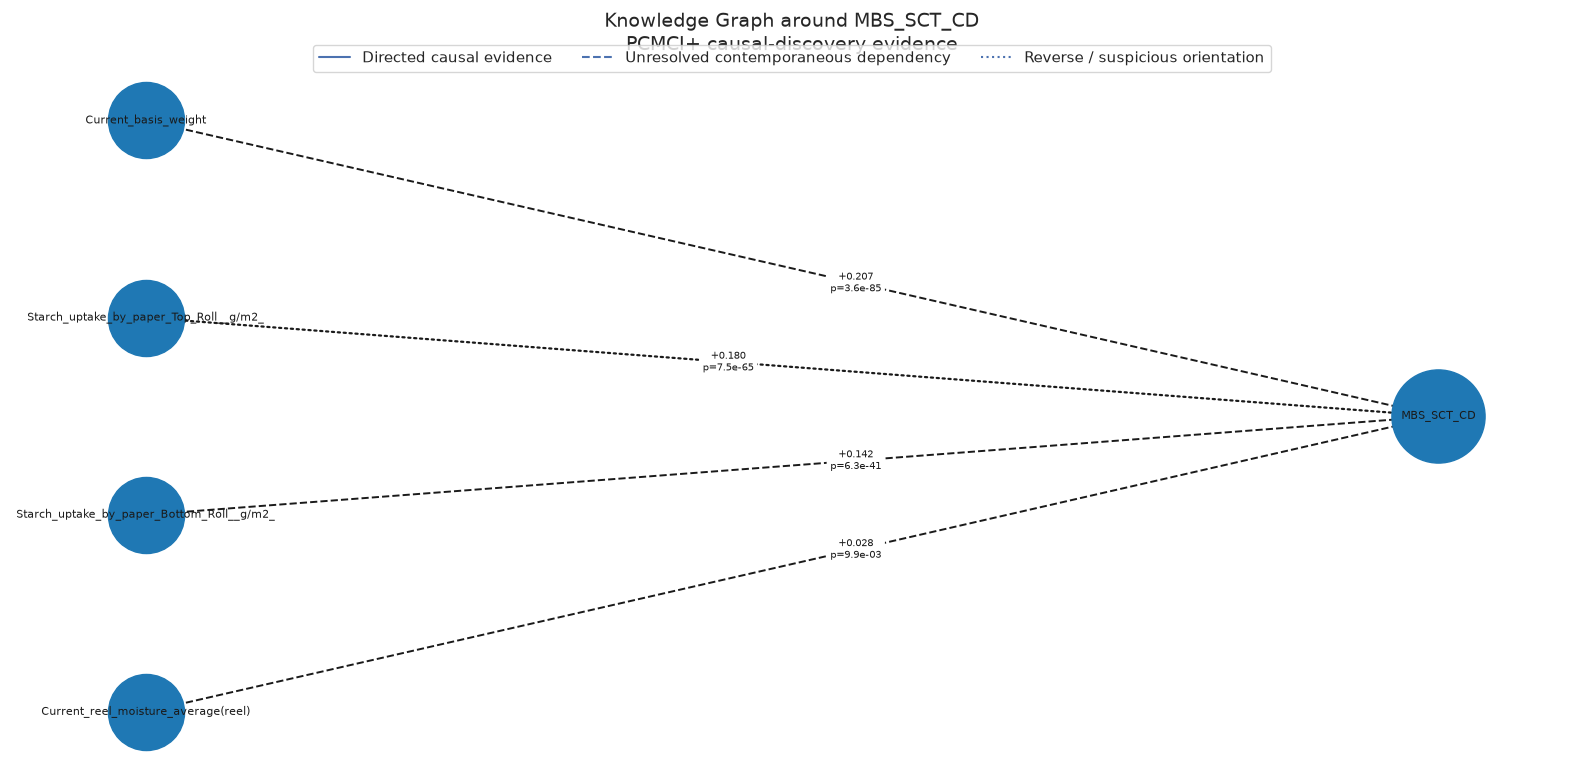

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

TARGET = "MBS_SCT_CD"

graph = results["graph"]
val_matrix = results["val_matrix"]
p_matrix = results["p_matrix"]

target_idx = var_names.index(TARGET)

# ------------------------------------------------------------
# Build Knowledge Graph
# ------------------------------------------------------------
KG = nx.MultiDiGraph()

KG.add_node(
    TARGET,
    node_type="quality_property",
    label=TARGET,
)

for i, source in enumerate(var_names):

    if source == TARGET:
        continue

    for tau in range(graph.shape[2]):

        link = str(graph[i, target_idx, tau])

        if link == "":
            continue

        value = float(val_matrix[i, target_idx, tau])
        p_value = float(p_matrix[i, target_idx, tau])

        source_label = source if tau == 0 else f"{source} (t-{tau})"

        KG.add_node(
            source_label,
            node_type="process_variable",
            label=source_label,
        )

        # ----------------------------------------------------
        # Interpret PCMCI+ edge
        # ----------------------------------------------------
        if link in ["-->", "o->"]:

            KG.add_edge(
                source_label,
                TARGET,
                relation="causal_evidence",
                orientation="directed",
                pcmci_link=link,
                method="PCMCI+",
                lag=tau,
                strength=value,
                p_value=p_value,
            )

        elif link in ["x-x", "o-o"]:

            KG.add_edge(
                source_label,
                TARGET,
                relation="dependency",
                orientation="unresolved",
                pcmci_link=link,
                method="PCMCI+",
                lag=tau,
                strength=value,
                p_value=p_value,
            )

        elif link in ["<--", "<-o"]:

            KG.add_edge(
                TARGET,
                source_label,
                relation="reverse_evidence",
                orientation="reverse",
                pcmci_link=link,
                method="PCMCI+",
                lag=tau,
                strength=value,
                p_value=p_value,
            )


# ------------------------------------------------------------
# Build simplified display graph
# ------------------------------------------------------------
G = nx.DiGraph()

for node, attrs in KG.nodes(data=True):
    G.add_node(node, **attrs)

for u, v, data in KG.edges(data=True):

    G.add_edge(
        u,
        v,
        strength=data["strength"],
        p_value=data["p_value"],
        orientation=data["orientation"],
        relation=data["relation"],
        pcmci_link=data["pcmci_link"],
    )


# ------------------------------------------------------------
# Left-to-right layout
# ------------------------------------------------------------
sources = [n for n in G.nodes if n != TARGET]

# Sort strongest relationships at top
sources = sorted(
    sources,
    key=lambda n: abs(
        G[n][TARGET]["strength"]
        if G.has_edge(n, TARGET)
        else G[TARGET][n]["strength"]
    ),
    reverse=True,
)

pos = {
    TARGET: (1.0, 0.0)
}

n = len(sources)

for i, node in enumerate(sources):
    y = (n - 1) / 2 - i
    pos[node] = (0.0, y)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(16, max(8, n * 0.75))
)

# Nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=sources,
    node_size=3000,
    ax=ax,
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=[TARGET],
    node_size=4500,
    ax=ax,
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    ax=ax,
)


# ------------------------------------------------------------
# Draw edge types separately
# ------------------------------------------------------------
directed_edges = []
unresolved_edges = []
reverse_edges = []

for u, v, data in G.edges(data=True):

    if data["orientation"] == "directed":
        directed_edges.append((u, v))

    elif data["orientation"] == "unresolved":
        unresolved_edges.append((u, v))

    elif data["orientation"] == "reverse":
        reverse_edges.append((u, v))


# Directed causal evidence
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=directed_edges,
    style="solid",
    arrows=True,
    arrowsize=22,
    width=1.8,
    ax=ax,
)

# Unresolved dependencies
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=unresolved_edges,
    style="dashed",
    arrows=False,
    width=1.4,
    ax=ax,
)

# Reverse / suspicious orientation
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=reverse_edges,
    style="dotted",
    arrows=True,
    arrowsize=22,
    width=1.6,
    ax=ax,
)


# ------------------------------------------------------------
# Edge labels
# ------------------------------------------------------------
edge_labels = {}

for u, v, data in G.edges(data=True):

    edge_labels[(u, v)] = (
        f"{data['strength']:+.3f}\n"
        f"p={data['p_value']:.1e}"
    )

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7,
    rotate=False,
    label_pos=0.55,
    ax=ax,
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0], [0],
        linestyle="-",
        label="Directed causal evidence"
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        label="Unresolved contemporaneous dependency"
    ),
    Line2D(
        [0], [0],
        linestyle=":",
        label="Reverse / suspicious orientation"
    ),
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=3,
)

ax.set_title(
    "Knowledge Graph around MBS_SCT_CD\n"
    "PCMCI+ causal-discovery evidence",
    fontsize=14,
)

ax.axis("off")

plt.tight_layout()
plt.show()

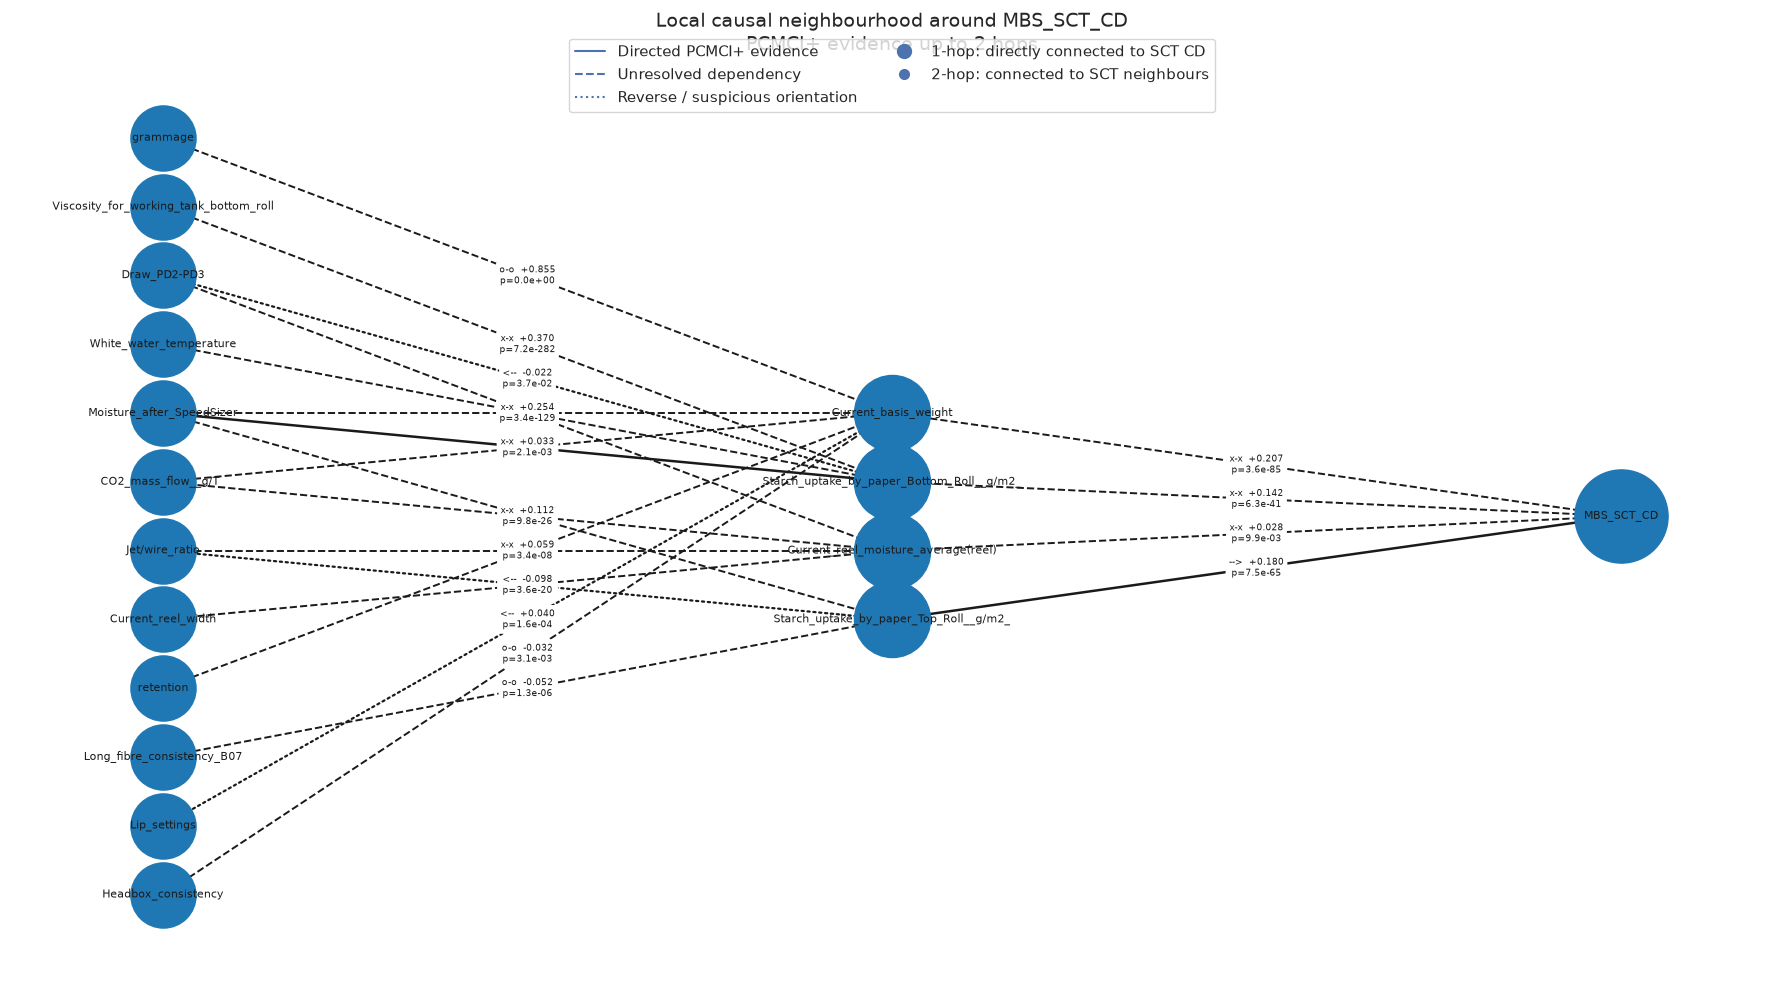


Number of displayed nodes: 17
Number of displayed edges: 21

DIRECT NEIGHBOURS OF SCT CD
--------------------------------------------------------------------------------
MBS_SCT_CD                                    -> Current_reel_moisture_average(reel) x-x  lag=0 value=+0.028 p=0.00992
MBS_SCT_CD                                    -> Current_basis_weight x-x  lag=0 value=+0.207 p=3.64e-85
MBS_SCT_CD                                    -> Starch_uptake_by_paper_Bottom_Roll__g/m2_ x-x  lag=0 value=+0.142 p=6.32e-41
MBS_SCT_CD                                    -> Starch_uptake_by_paper_Top_Roll__g/m2_ -->  lag=0 value=+0.180 p=7.51e-65

SECOND-ORDER RELATIONSHIPS
--------------------------------------------------------------------------------
Current_reel_moisture_average(reel)           -> Draw_PD2-PD3                                  x-x  lag=0 value=+0.355 p=4.84e-259
Current_reel_moisture_average(reel)           -> Jet/wire_ratio                                x-x  lag=0 value=+0.0

In [14]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

TARGET = "MBS_SCT_CD"

# How deep to explore:
# 1 = only variables directly connected to TARGET
# 2 = TARGET neighbours + variables connected to those neighbours
MAX_DEPTH = 2

# Optional filters
P_VALUE_MAX = 0.05
MIN_ABS_STRENGTH = 0.0

graph = results["graph"]
val_matrix = results["val_matrix"]
p_matrix = results["p_matrix"]

target_idx = var_names.index(TARGET)


# ============================================================
# Helpers
# ============================================================

def temporal_label(var_name, tau):
    """Represent a lagged variable as a separate node."""
    return var_name if tau == 0 else f"{var_name} (t-{tau})"


def edge_passes_filter(value, p_value):
    return (
        np.isfinite(value)
        and np.isfinite(p_value)
        and p_value <= P_VALUE_MAX
        and abs(value) >= MIN_ABS_STRENGTH
    )


def interpret_pcmci_link(source_label, target_label, link):
    """
    Convert Tigramite/PCMCI+ link notation into display direction.

    Returns:
        u, v, orientation, relation

    Notes
    -----
    '-->' / 'o->':
        evidence points source -> target

    '<--' / '<-o':
        evidence points target -> source

    'x-x' / 'o-o':
        adjacency/dependency exists but orientation is unresolved
    """
    if link in ["-->", "o->"]:
        return (
            source_label,
            target_label,
            "directed",
            "causal_evidence",
        )

    if link in ["<--", "<-o"]:
        return (
            target_label,
            source_label,
            "reverse",
            "reverse_evidence",
        )

    if link in ["x-x", "o-o"]:
        return (
            source_label,
            target_label,
            "unresolved",
            "dependency",
        )

    return None


def collect_edges_touching(variable_indices):
    """
    Collect all PCMCI+ links for which at least one endpoint belongs
    to variable_indices.

    For graph[i, j, tau], the candidate relation is between
    var_names[i](t-tau) and var_names[j](t).
    """
    collected = []

    n_vars = len(var_names)
    n_lags = graph.shape[2]

    for i in range(n_vars):
        for j in range(n_vars):

            if i == j:
                continue

            # Keep only relationships touching the current frontier.
            if i not in variable_indices and j not in variable_indices:
                continue

            for tau in range(n_lags):

                link = str(graph[i, j, tau])

                if link == "":
                    continue

                value = float(val_matrix[i, j, tau])
                p_value = float(p_matrix[i, j, tau])

                if not edge_passes_filter(value, p_value):
                    continue

                source_label = temporal_label(var_names[i], tau)
                target_label = var_names[j]

                interpreted = interpret_pcmci_link(
                    source_label,
                    target_label,
                    link,
                )

                if interpreted is None:
                    continue

                u, v, orientation, relation = interpreted

                collected.append(
                    {
                        "i": i,
                        "j": j,
                        "tau": tau,
                        "u": u,
                        "v": v,
                        "source_variable": var_names[i],
                        "target_variable": var_names[j],
                        "strength": value,
                        "p_value": p_value,
                        "pcmci_link": link,
                        "orientation": orientation,
                        "relation": relation,
                    }
                )

    return collected


# ============================================================
# Step 1: discover graph neighbourhood iteratively
# ============================================================

discovered_indices = {target_idx}
frontier = {target_idx}

all_edges = []

for depth in range(1, MAX_DEPTH + 1):

    depth_edges = collect_edges_touching(frontier)

    next_frontier = set()

    for edge in depth_edges:

        i = edge["i"]
        j = edge["j"]

        # Avoid adding edges between two totally new nodes.
        # At least one endpoint must belong to the current frontier.
        if i not in frontier and j not in frontier:
            continue

        edge["depth"] = depth
        all_edges.append(edge)

        if i not in discovered_indices:
            next_frontier.add(i)

        if j not in discovered_indices:
            next_frontier.add(j)

    discovered_indices.update(next_frontier)
    frontier = next_frontier

    if not frontier:
        break


# ============================================================
# Step 2: deduplicate PCMCI representations
# ============================================================

# PCMCI+ can encode contemporaneous relationships in both matrix
# directions. Use a canonical key to avoid plotting the same
# lag-0 adjacency twice.
unique_edges = {}

for edge in all_edges:

    u = edge["u"]
    v = edge["v"]
    tau = edge["tau"]
    orientation = edge["orientation"]

    if tau == 0 and orientation == "unresolved":
        pair = tuple(sorted([u, v]))
        key = ("unresolved", pair, tau)
    else:
        key = (
            orientation,
            u,
            v,
            tau,
        )

    # Keep the statistically stronger duplicate if necessary.
    if key not in unique_edges:
        unique_edges[key] = edge
    else:
        previous = unique_edges[key]
        if edge["p_value"] < previous["p_value"]:
            unique_edges[key] = edge

all_edges = list(unique_edges.values())


# ============================================================
# Step 3: Build Knowledge Graph
# ============================================================

KG = nx.MultiDiGraph()

KG.add_node(
    TARGET,
    node_type="quality_property",
    label=TARGET,
    depth=0,
)

for edge in all_edges:

    u = edge["u"]
    v = edge["v"]

    for node in [u, v]:
        if node not in KG:
            base_name = node.split(" (t-")[0]

            if base_name == TARGET:
                node_type = "quality_property"
            else:
                node_type = "process_variable"

            KG.add_node(
                node,
                node_type=node_type,
                label=node,
                depth=edge["depth"],
            )

    KG.add_edge(
        u,
        v,
        relation=edge["relation"],
        orientation=edge["orientation"],
        pcmci_link=edge["pcmci_link"],
        method="PCMCI+",
        lag=edge["tau"],
        strength=edge["strength"],
        p_value=edge["p_value"],
        discovery_depth=edge["depth"],
    )


# ============================================================
# Step 4: Build simplified display graph
# ============================================================

G = nx.DiGraph()

for node, attrs in KG.nodes(data=True):
    G.add_node(node, **attrs)

for u, v, data in KG.edges(data=True):

    # If multiple edges collapse to the same display edge,
    # retain the one with the lowest p-value.
    if G.has_edge(u, v):
        if data["p_value"] >= G[u][v]["p_value"]:
            continue

    G.add_edge(
        u,
        v,
        strength=data["strength"],
        p_value=data["p_value"],
        orientation=data["orientation"],
        relation=data["relation"],
        pcmci_link=data["pcmci_link"],
        lag=data["lag"],
        discovery_depth=data["discovery_depth"],
    )


# ============================================================
# Step 5: Calculate graph distance from TARGET
# ============================================================

UG = G.to_undirected()

if TARGET in UG:
    distances = nx.single_source_shortest_path_length(
        UG,
        TARGET,
        cutoff=MAX_DEPTH,
    )
else:
    distances = {TARGET: 0}

# Keep only nodes actually within requested local neighbourhood.
keep_nodes = set(distances.keys())
G = G.subgraph(keep_nodes).copy()


# ============================================================
# Step 6: Layered layout
# ============================================================

layers = {}

for node, distance in distances.items():
    if node not in G:
        continue
    layers.setdefault(distance, []).append(node)

# Sort each layer using strongest connection to the previous layers.
for distance, nodes in layers.items():

    if distance == 0:
        continue

    def node_score(node):
        values = []

        for _, _, data in G.edges(node, data=True):
            values.append(abs(data["strength"]))

        for _, _, data in G.in_edges(node, data=True):
            values.append(abs(data["strength"]))

        return max(values) if values else 0.0

    layers[distance] = sorted(
        nodes,
        key=node_score,
        reverse=True,
    )


pos = {}

# Target at right, upstream neighbourhood progressively to the left.
for distance, nodes in layers.items():

    x = -distance

    n_nodes = len(nodes)

    if n_nodes == 1:
        ys = [0.0]
    else:
        ys = np.linspace(
            (n_nodes - 1) / 2,
            -(n_nodes - 1) / 2,
            n_nodes,
        )

    for node, y in zip(nodes, ys):
        pos[node] = (x, y)


# Put target on the right.
if TARGET in pos:
    max_distance = max(layers.keys())
    for node in pos:
        d = distances[node]
        pos[node] = (max_distance - d, pos[node][1])


# ============================================================
# Step 7: Plot
# ============================================================

n_nodes = len(G.nodes)

fig, ax = plt.subplots(
    figsize=(18, max(10, n_nodes * 0.55))
)


# ------------------------------------------------------------
# Nodes by depth
# ------------------------------------------------------------

target_nodes = [TARGET] if TARGET in G else []

first_hop_nodes = [
    n for n in G.nodes
    if n != TARGET and distances.get(n) == 1
]

second_hop_nodes = [
    n for n in G.nodes
    if distances.get(n) == 2
]


nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=second_hop_nodes,
    node_size=2200,
    node_shape="o",
    ax=ax,
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=first_hop_nodes,
    node_size=3000,
    node_shape="o",
    ax=ax,
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=target_nodes,
    node_size=4500,
    node_shape="o",
    ax=ax,
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    ax=ax,
)


# ------------------------------------------------------------
# Edge types
# ------------------------------------------------------------

directed_edges = []
unresolved_edges = []
reverse_edges = []

for u, v, data in G.edges(data=True):

    if data["orientation"] == "directed":
        directed_edges.append((u, v))

    elif data["orientation"] == "unresolved":
        unresolved_edges.append((u, v))

    elif data["orientation"] == "reverse":
        reverse_edges.append((u, v))


nx.draw_networkx_edges(
    G,
    pos,
    edgelist=directed_edges,
    style="solid",
    arrows=True,
    arrowsize=22,
    width=1.8,
    ax=ax,
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=unresolved_edges,
    style="dashed",
    arrows=False,
    width=1.4,
    ax=ax,
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=reverse_edges,
    style="dotted",
    arrows=True,
    arrowsize=22,
    width=1.6,
    ax=ax,
)


# ------------------------------------------------------------
# Edge labels
# ------------------------------------------------------------

edge_labels = {}

for u, v, data in G.edges(data=True):

    lag_txt = (
        ""
        if data["lag"] == 0
        else f"\nlag={data['lag']}"
    )

    edge_labels[(u, v)] = (
        f"{data['pcmci_link']}  "
        f"{data['strength']:+.3f}\n"
        f"p={data['p_value']:.1e}"
        f"{lag_txt}"
    )


nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=6.5,
    rotate=False,
    label_pos=0.5,
    ax=ax,
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_elements = [
    Line2D(
        [0], [0],
        linestyle="-",
        label="Directed PCMCI+ evidence"
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        label="Unresolved dependency"
    ),
    Line2D(
        [0], [0],
        linestyle=":",
        label="Reverse / suspicious orientation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=10,
        label="1-hop: directly connected to SCT CD"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=7,
        label="2-hop: connected to SCT neighbours"
    ),
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=2,
)

ax.set_title(
    f"Local causal neighbourhood around {TARGET}\n"
    f"PCMCI+ evidence up to {MAX_DEPTH} hops",
    fontsize=14,
)

ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# Step 8: Print relationships in readable form
# ============================================================

print(f"\nNumber of displayed nodes: {G.number_of_nodes()}")
print(f"Number of displayed edges: {G.number_of_edges()}")

print("\nDIRECT NEIGHBOURS OF SCT CD")
print("-" * 80)

for node in first_hop_nodes:

    if G.has_edge(node, TARGET):
        data = G[node][TARGET]
        print(
            f"{node:45s} -> {TARGET:20s} "
            f"{data['pcmci_link']:4s} "
            f"lag={data['lag']} "
            f"value={data['strength']:+.3f} "
            f"p={data['p_value']:.3g}"
        )

    elif G.has_edge(TARGET, node):
        data = G[TARGET][node]
        print(
            f"{TARGET:45s} -> {node:20s} "
            f"{data['pcmci_link']:4s} "
            f"lag={data['lag']} "
            f"value={data['strength']:+.3f} "
            f"p={data['p_value']:.3g}"
        )


print("\nSECOND-ORDER RELATIONSHIPS")
print("-" * 80)

for u, v, data in G.edges(data=True):

    if TARGET in [u, v]:
        continue

    print(
        f"{u:45s} -> {v:45s} "
        f"{data['pcmci_link']:4s} "
        f"lag={data['lag']} "
        f"value={data['strength']:+.3f} "
        f"p={data['p_value']:.3g}"
    )

In [15]:
import pandas as pd

TARGET = "MBS_SCT_CD"

target_idx = var_names.index(TARGET)

rows = []

for i, name in enumerate(var_names):

    if i == target_idx:
        continue

    for tau in range(graph.shape[2]):

        # i -> target representation
        link_to_target = str(graph[i, target_idx, tau])

        if link_to_target != "":
            rows.append(
                {
                    "variable": name,
                    "lag": tau,
                    "link": link_to_target,
                    "value": float(val_matrix[i, target_idx, tau]),
                    "p_value": float(p_matrix[i, target_idx, tau]),
                    "matrix_direction": f"{name} -> {TARGET}",
                }
            )

        # target -> i representation
        link_from_target = str(graph[target_idx, i, tau])

        if link_from_target != "":
            rows.append(
                {
                    "variable": name,
                    "lag": tau,
                    "link": link_from_target,
                    "value": float(val_matrix[target_idx, i, tau]),
                    "p_value": float(p_matrix[target_idx, i, tau]),
                    "matrix_direction": f"{TARGET} -> {name}",
                }
            )


sct_connections = pd.DataFrame(rows)

# Remove duplicate contemporaneous representations
sct_connections = (
    sct_connections
    .sort_values("p_value")
    .drop_duplicates(
        subset=["variable", "lag"]
    )
    .reset_index(drop=True)
)

print(sct_connections.to_string(index=False))

                                 variable  lag link    value      p_value                                        matrix_direction
                     Current_basis_weight    0  x-x 0.206750 3.642261e-85                      MBS_SCT_CD -> Current_basis_weight
   Starch_uptake_by_paper_Top_Roll__g/m2_    0  <-- 0.180246 7.512934e-65    Starch_uptake_by_paper_Top_Roll__g/m2_ -> MBS_SCT_CD
Starch_uptake_by_paper_Bottom_Roll__g/m2_    0  x-x 0.142441 6.320999e-41 MBS_SCT_CD -> Starch_uptake_by_paper_Bottom_Roll__g/m2_
      Current_reel_moisture_average(reel)    0  x-x 0.027552 9.921551e-03       Current_reel_moisture_average(reel) -> MBS_SCT_CD


In [113]:
import numpy as np
import pandas as pd

TARGET = "MBS_SCT_CD"
FOCUS = "Starch_uptake_by_paper_Top_Roll__g/m2_"

graph = results["graph"]
val_matrix = results["val_matrix"]
p_matrix = results["p_matrix"]

target_idx = var_names.index(TARGET)
focus_idx = var_names.index(FOCUS)


# ============================================================
# 1. Find every PCMCI+ variable connected to Current_basis_weight
# ============================================================

def get_connected_variables(
    variable,
    graph,
    val_matrix,
    p_matrix,
    var_names,
    alpha=0.05,
):
    var_idx = var_names.index(variable)

    rows = []

    n_vars = len(var_names)
    n_lags = graph.shape[2]

    for i in range(n_vars):
        for j in range(n_vars):
            for tau in range(n_lags):

                link = str(graph[i, j, tau])

                if link == "":
                    continue

                p_value = float(p_matrix[i, j, tau])
                value = float(val_matrix[i, j, tau])

                if p_value > alpha:
                    continue

                # Relationship:
                # var_names[i](t-tau)  ---  var_names[j](t)

                if j == var_idx and i != var_idx:
                    rows.append(
                        {
                            "connected_variable": var_names[i],
                            "connected_lag": tau,
                            "focus_variable": variable,
                            "focus_lag": 0,
                            "link": link,
                            "value": value,
                            "p_value": p_value,
                            "matrix_direction": "connected -> focus",
                        }
                    )

                elif i == var_idx and j != var_idx:
                    rows.append(
                        {
                            "connected_variable": var_names[j],
                            "connected_lag": 0,
                            "focus_variable": variable,
                            "focus_lag": tau,
                            "link": link,
                            "value": value,
                            "p_value": p_value,
                            "matrix_direction": "focus -> connected",
                        }
                    )

    df = pd.DataFrame(rows)

    if len(df) == 0:
        return df

    # Remove obvious duplicate contemporaneous representations.
    df = (
        df.sort_values("p_value")
        .drop_duplicates(
            subset=[
                "connected_variable",
                "connected_lag",
                "focus_lag",
            ]
        )
        .reset_index(drop=True)
    )

    return df


connections = get_connected_variables(
    FOCUS,
    graph,
    val_matrix,
    p_matrix,
    var_names,
)

print(connections)

                           connected_variable  connected_lag  \
0   Starch_uptake_by_paper_Bottom_Roll__g/m2_              0   
1                              Jet/wire_ratio              0   
2                   Moisture_after_SpeedSizer              0   
3                                Lip_settings              0   
4         Current_reel_moisture_average(reel)              0   
5              pH_measurement_white_water_B41              0   
6                                  MBS_SCT_CD              0   
7                  SpeedSizer_Linepressure_FS              0   
8                     White_water_temperature              0   
9                         Headbox_consistency              0   
10                                Draw_PD5-SS              0   
11                                 Draw_WS-PS              0   

                            focus_variable  focus_lag link     value  \
0   Starch_uptake_by_paper_Top_Roll__g/m2_          0  -->  0.386094   
1   Starch_uptake_by_pa

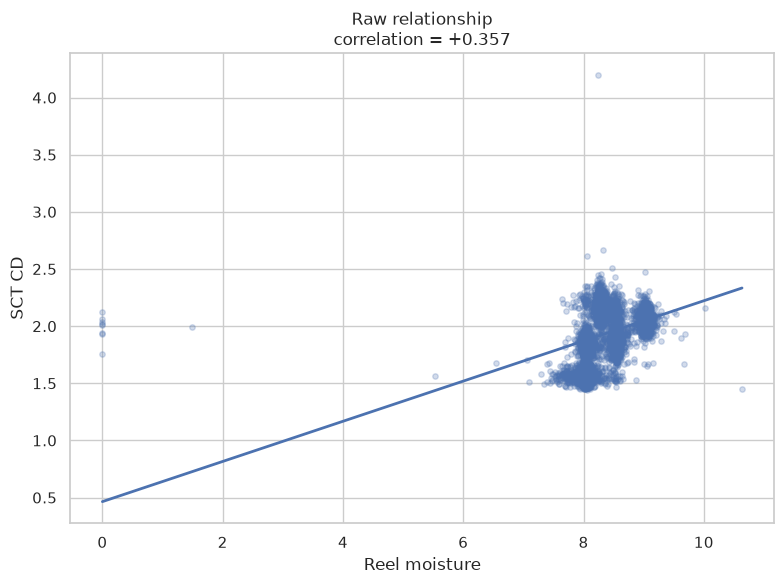

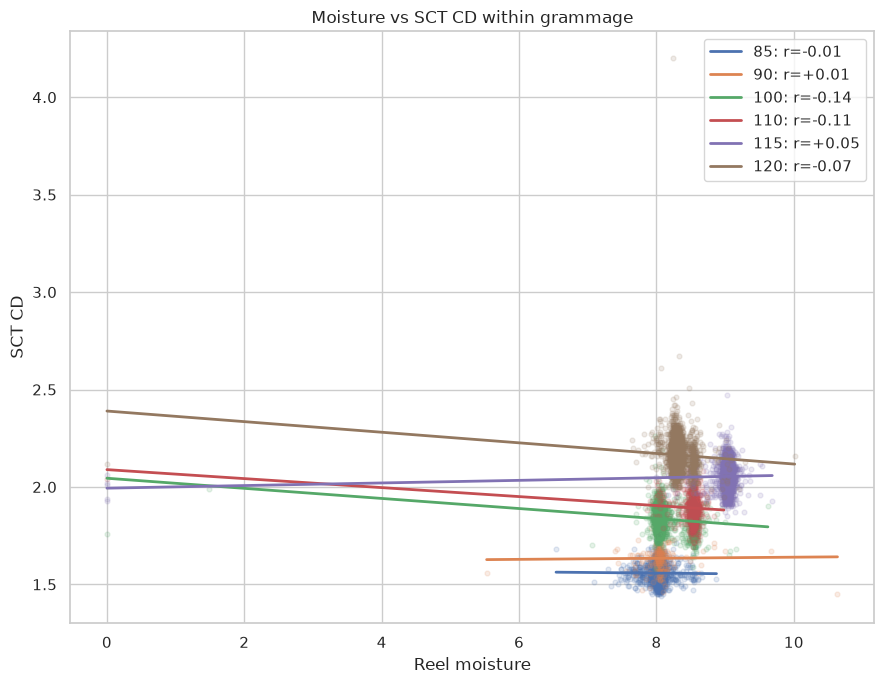

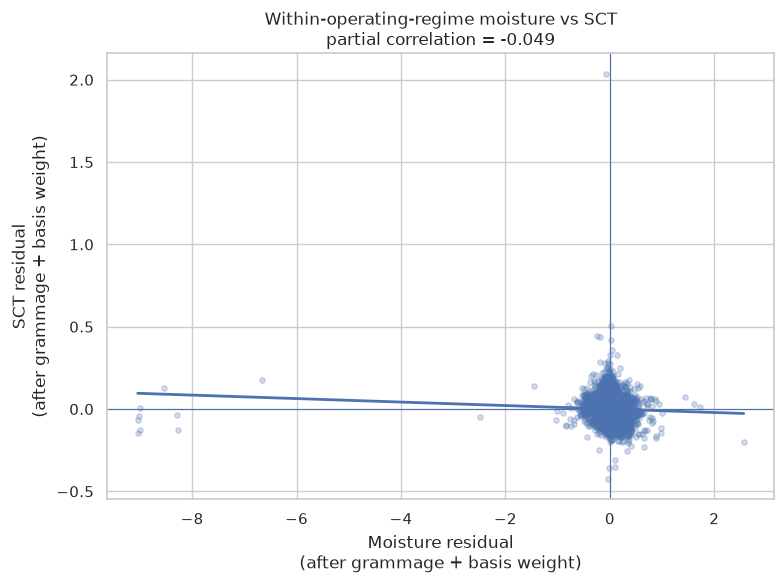

In [125]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression


MOISTURE = "Current_reel_moisture_average(reel)"
SCT = "MBS_SCT_CD"
BW = "Current_basis_weight"
GRAMMAGE = "grammage"


# ============================================================
# Prepare data
# ============================================================

d = turnup_data[
    [MOISTURE, SCT, BW, GRAMMAGE]
].dropna().copy()


# ============================================================
# 1. RAW: Moisture vs SCT
# ============================================================

x = d[MOISTURE].values
y = d[SCT].values

coef = np.polyfit(x, y, 1)
xx = np.linspace(x.min(), x.max(), 100)
yy = coef[0] * xx + coef[1]

corr = np.corrcoef(x, y)[0, 1]

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.25,
    s=15,
)

plt.plot(
    xx,
    yy,
    linewidth=2,
)

plt.xlabel("Reel moisture")
plt.ylabel("SCT CD")

plt.title(
    f"Raw relationship\n"
    f"correlation = {corr:+.3f}"
)

plt.tight_layout()
plt.show()


# ============================================================
# 2. Moisture vs SCT, one line per grammage
# ============================================================

plt.figure(figsize=(9, 7))

for grammage, g in d.groupby(GRAMMAGE):

    if len(g) < 20:
        continue

    x = g[MOISTURE].values
    y = g[SCT].values

    plt.scatter(
        x,
        y,
        alpha=0.15,
        s=12,
    )

    coef = np.polyfit(x, y, 1)

    xx = np.linspace(
        x.min(),
        x.max(),
        50,
    )

    yy = coef[0] * xx + coef[1]

    corr = np.corrcoef(x, y)[0, 1]

    plt.plot(
        xx,
        yy,
        linewidth=2,
        label=f"{grammage}: r={corr:+.2f}",
    )

plt.xlabel("Reel moisture")
plt.ylabel("SCT CD")

plt.title(
    "Moisture vs SCT CD within grammage"
)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 3. Remove grammage + basis weight from BOTH variables
#
# Then compare the unexplained parts.
# ============================================================

controls = pd.get_dummies(
    d[[BW, GRAMMAGE]],
    columns=[GRAMMAGE],
    drop_first=True,
    dtype=float,
)

# Residual moisture
m_model = LinearRegression()
m_model.fit(
    controls,
    d[MOISTURE],
)

moisture_residual = (
    d[MOISTURE]
    - m_model.predict(controls)
)


# Residual SCT
y_model = LinearRegression()
y_model.fit(
    controls,
    d[SCT],
)

sct_residual = (
    d[SCT]
    - y_model.predict(controls)
)


# Partial correlation
partial_corr = np.corrcoef(
    moisture_residual,
    sct_residual,
)[0, 1]


# Regression line
coef = np.polyfit(
    moisture_residual,
    sct_residual,
    1,
)

xx = np.linspace(
    moisture_residual.min(),
    moisture_residual.max(),
    100,
)

yy = coef[0] * xx + coef[1]


plt.figure(figsize=(8, 6))

plt.scatter(
    moisture_residual,
    sct_residual,
    alpha=0.25,
    s=15,
)

plt.plot(
    xx,
    yy,
    linewidth=2,
)

plt.axhline(
    0,
    linewidth=0.8,
)

plt.axvline(
    0,
    linewidth=0.8,
)

plt.xlabel(
    "Moisture residual\n"
    "(after grammage + basis weight)"
)

plt.ylabel(
    "SCT residual\n"
    "(after grammage + basis weight)"
)

plt.title(
    "Within-operating-regime moisture vs SCT\n"
    f"partial correlation = {partial_corr:+.3f}"
)

plt.tight_layout()
plt.show()

In [122]:
Z_NAME = "Current_reel_moisture_average(reel)"

In [123]:

Z_LAG = 0

# ============================================================
# 2. Conditional-independence tests for one triplet
#
# Z = selected second-hop variable
# B = Current_basis_weight
# Y = MBS_SCT_CD
# ============================================================

B_NAME = "Starch_uptake_by_paper_Top_Roll__g/m2_"
Y_NAME = "MBS_SCT_CD"

B_idx = var_names.index(B_NAME)
Y_idx = var_names.index(Y_NAME)
Z_idx = var_names.index(Z_NAME)


def run_ci_test(
    pcmci,
    x_idx,
    y_idx,
    conditioning=None,
    x_lag=0,
    y_lag=0,
):
    """
    Run one Tigramite conditional-independence test.

    conditioning:
        list of tuples [(variable_index, lag), ...]
    """

    if conditioning is None:
        conditioning = []

    value, p_value = pcmci.cond_ind_test.run_test(
        X=[(x_idx, x_lag)],
        Y=[(y_idx, y_lag)],
        Z=conditioning,
    )

    return {
        "value": float(value),
        "p_value": float(p_value),
    }

# ------------------------------------------------------------
# Test 1
#
# B ⟂ Y ?
#
# Is basis weight associated with SCT before conditioning?
# ------------------------------------------------------------

T_BY = run_ci_test(
    pcmci,
    x_idx=B_idx,
    y_idx=Y_idx,
)

# ------------------------------------------------------------
# Test 2
#
# B ⟂ Y | Z ?
#
# Does the BasisWeight-SCT relationship survive after
# conditioning on Z?
# ------------------------------------------------------------

T_BY_given_Z = run_ci_test(
    pcmci,
    x_idx=B_idx,
    y_idx=Y_idx,
    conditioning=[
        (Z_idx, -Z_LAG)
    ],
)

# ------------------------------------------------------------
# Test 3
#
# Z ⟂ Y ?
#
# Is Z associated with SCT before conditioning?
# ------------------------------------------------------------

T_ZY = run_ci_test(
    pcmci,
    x_idx=Z_idx,
    y_idx=Y_idx,
    x_lag=-Z_LAG,
)

# ------------------------------------------------------------
# Test 4
#
# Z ⟂ Y | B ?
#
# Does Z-SCT disappear once basis weight is known?
#
# This is especially interesting for a possible:
#
# Z -> B -> Y
# ------------------------------------------------------------

T_ZY_given_B = run_ci_test(
    pcmci,
    x_idx=Z_idx,
    y_idx=Y_idx,
    x_lag=-Z_LAG,
    conditioning=[
        (B_idx, 0)
    ],
)

# ------------------------------------------------------------
# Test 5
#
# Z ⟂ B ?
#
# Are Z and basis weight themselves associated?
# ------------------------------------------------------------

T_ZB = run_ci_test(
    pcmci,
    x_idx=Z_idx,
    y_idx=B_idx,
    x_lag=-Z_LAG,
)

alpha = 0.05


def status(result):
    return (
        "DEPENDENT"
        if result["p_value"] < alpha
        else "INDEPENDENT"
    )


print("\n" + "=" * 70)
print(f"Z = {Z_NAME}")
print(f"B = {B_NAME}")
print(f"Y = {Y_NAME}")
print("=" * 70)

print("\nT1: B ⟂ Y ?")
print(
    f"value={T_BY['value']:+.4f}, "
    f"p={T_BY['p_value']:.3g} "
    f"--> {status(T_BY)}"
)

print("\nT2: B ⟂ Y | Z ?")
print(
    f"value={T_BY_given_Z['value']:+.4f}, "
    f"p={T_BY_given_Z['p_value']:.3g} "
    f"--> {status(T_BY_given_Z)}"
)

print("\nT3: Z ⟂ Y ?")
print(
    f"value={T_ZY['value']:+.4f}, "
    f"p={T_ZY['p_value']:.3g} "
    f"--> {status(T_ZY)}"
)

print("\nT4: Z ⟂ Y | B ?")
print(
    f"value={T_ZY_given_B['value']:+.4f}, "
    f"p={T_ZY_given_B['p_value']:.3g} "
    f"--> {status(T_ZY_given_B)}"
)

print("\nT5: Z ⟂ B ?")
print(
    f"value={T_ZB['value']:+.4f}, "
    f"p={T_ZB['p_value']:.3g} "
    f"--> {status(T_ZB)}"
)


Z = Current_reel_moisture_average(reel)
B = Starch_uptake_by_paper_Top_Roll__g/m2_
Y = MBS_SCT_CD

T1: B ⟂ Y ?
value=+0.5242, p=0 --> DEPENDENT

T2: B ⟂ Y | Z ?
value=+0.4998, p=0 --> DEPENDENT

T3: Z ⟂ Y ?
value=+0.3566, p=1.14e-260 --> DEPENDENT

T4: Z ⟂ Y | B ?
value=+0.3116, p=2.93e-196 --> DEPENDENT

T5: Z ⟂ B ?
value=+0.1826, p=1.91e-66 --> DEPENDENT


In [107]:
import pandas as pd

X_NAME = "Current_basis_weight"
Y_NAME = "MBS_SCT_CD"

alpha = 0.05

X_idx = var_names.index(X_NAME)
Y_idx = var_names.index(Y_NAME)


def run_ci_test(
    pcmci,
    x_idx,
    y_idx,
    conditioning=None,
    x_lag=0,
    y_lag=0,
):
    if conditioning is None:
        conditioning = []

    value, p_value = pcmci.cond_ind_test.run_test(
        X=[(x_idx, x_lag)],
        Y=[(y_idx, y_lag)],
        Z=conditioning,
    )

    return float(value), float(p_value)


def status(p_value):
    return "DEPENDENT" if p_value < alpha else "INDEPENDENT"


# ------------------------------------------------------------
# T1: X ⟂ Y ?
# Same for every Z, so compute once
# ------------------------------------------------------------

xy_value, xy_p = run_ci_test(
    pcmci,
    x_idx=X_idx,
    y_idx=Y_idx,
)


# ------------------------------------------------------------
# Run tests for every Z connected to X
# ------------------------------------------------------------

rows = []

for _, row in connections.iterrows():

    Z_NAME = row["connected_variable"]
    Z_LAG = int(row["connected_lag"])

    # Skip target itself
    if Z_NAME == Y_NAME:
        continue

    Z_idx = var_names.index(Z_NAME)

    # --------------------------------------------------------
    # T2: X ⟂ Y | Z ?
    # --------------------------------------------------------

    xy_z_value, xy_z_p = run_ci_test(
        pcmci,
        x_idx=X_idx,
        y_idx=Y_idx,
        conditioning=[
            (Z_idx, -Z_LAG)
        ],
    )

    # --------------------------------------------------------
    # T3: Z ⟂ Y ?
    # --------------------------------------------------------

    zy_value, zy_p = run_ci_test(
        pcmci,
        x_idx=Z_idx,
        y_idx=Y_idx,
        x_lag=-Z_LAG,
    )

    # --------------------------------------------------------
    # T4: Z ⟂ Y | X ?
    # --------------------------------------------------------

    zy_x_value, zy_x_p = run_ci_test(
        pcmci,
        x_idx=Z_idx,
        y_idx=Y_idx,
        x_lag=-Z_LAG,
        conditioning=[
            (X_idx, 0)
        ],
    )

    # --------------------------------------------------------
    # T5: Z ⟂ X ?
    # --------------------------------------------------------

    zx_value, zx_p = run_ci_test(
        pcmci,
        x_idx=Z_idx,
        y_idx=X_idx,
        x_lag=-Z_LAG,
    )

    rows.append(
        {
            "Z": Z_NAME,
            "lag": Z_LAG,

            "X-Y": xy_value,
            "p_XY": xy_p,
            "XY_status": status(xy_p),

            "X-Y|Z": xy_z_value,
            "p_XY_given_Z": xy_z_p,
            "XY_given_Z_status": status(xy_z_p),

            "Z-Y": zy_value,
            "p_ZY": zy_p,
            "ZY_status": status(zy_p),

            "Z-Y|X": zy_x_value,
            "p_ZY_given_X": zy_x_p,
            "ZY_given_X_status": status(zy_x_p),

            "Z-X": zx_value,
            "p_ZX": zx_p,
            "ZX_status": status(zx_p),
        }
    )


ci_table = pd.DataFrame(rows)


# ------------------------------------------------------------
# Useful derived quantities
# ------------------------------------------------------------

ci_table["drop_XY_after_Z"] = (
    ci_table["X-Y"].abs()
    - ci_table["X-Y|Z"].abs()
)

ci_table["drop_ZY_after_X"] = (
    ci_table["Z-Y"].abs()
    - ci_table["Z-Y|X"].abs()
)


# Optional: sort by strongest Z-X relationship
ci_table = ci_table.sort_values(
    by="Z-X",
    key=lambda s: s.abs(),
    ascending=False,
).reset_index(drop=True)


print(ci_table.to_string(index=False))

                                        Z  lag      X-Y  p_XY XY_status    X-Y|Z  p_XY_given_Z XY_given_Z_status       Z-Y          p_ZY ZY_status     Z-Y|X  p_ZY_given_X ZY_given_X_status       Z-X          p_ZX ZX_status  drop_XY_after_Z  drop_ZY_after_X
                                 grammage    0 0.948219   0.0 DEPENDENT 0.220717  5.456241e-97         DEPENDENT  0.945534  0.000000e+00 DEPENDENT  0.027553  9.961677e-03         DEPENDENT  0.996384  0.000000e+00 DEPENDENT         0.727502         0.917981
                                 grammage    0 0.948219   0.0 DEPENDENT 0.220717  5.456241e-97         DEPENDENT  0.945534  0.000000e+00 DEPENDENT  0.027553  9.961677e-03         DEPENDENT  0.996384  0.000000e+00 DEPENDENT         0.727502         0.917981
                                 grammage    1 0.948219   0.0 DEPENDENT 0.506441  0.000000e+00         DEPENDENT  0.929893  0.000000e+00 DEPENDENT  0.052952  7.218794e-07         DEPENDENT  0.976881  0.000000e+00 DEPENDENT       

In [111]:
import pandas as pd
import numpy as np

X_NAME = "Current_basis_weight"
Y_NAME = "MBS_SCT_CD"

ALPHA = 0.05
NEAR_ZERO = 0.05

X_idx = var_names.index(X_NAME)
Y_idx = var_names.index(Y_NAME)


def ci_test(x_name, y_name, conditioning=None, x_lag=0):
    """Run ParCorr conditional-independence test."""
    if conditioning is None:
        conditioning = []

    x_idx = var_names.index(x_name)
    y_idx = var_names.index(y_name)

    Z = [
        (var_names.index(name), -lag)
        for name, lag in conditioning
    ]

    value, p_value = pcmci.cond_ind_test.run_test(
        X=[(x_idx, -x_lag)],
        Y=[(y_idx, 0)],
        Z=Z,
    )

    return float(value), float(p_value)


def classify_pattern(
    zy,
    zy_x,
    p_zy_x,
    xy,
    xy_z,
):
    """
    Simple descriptive classification.

    This is NOT a causal conclusion.
    """

    # Z-Y disappears after conditioning on X
    if p_zy_x >= ALPHA or abs(zy_x) < NEAR_ZERO:
        return "Z-Y explained by X"

    # Conditioning flips sign
    if np.sign(zy) != np.sign(zy_x):
        return "sign reversal after X"

    # Z still has substantial residual association with Y
    if abs(zy_x) >= 0.10:
        return "Z-Y survives X"

    return "weak residual Z-Y"


# ------------------------------------------------------------
# Baseline X-Y relationship
# ------------------------------------------------------------

xy, p_xy = ci_test(
    X_NAME,
    Y_NAME,
)


# ------------------------------------------------------------
# One row per Z connected to X
# ------------------------------------------------------------

rows = []

for _, connection in connections.iterrows():

    Z_NAME = connection["connected_variable"]
    Z_LAG = int(connection["connected_lag"])

    if Z_NAME == Y_NAME:
        continue

    # Avoid duplicated Z/lag combinations
    # if connections contains matrix duplicates.
    key = (Z_NAME, Z_LAG)

    # Z-X
    zx, p_zx = ci_test(
        Z_NAME,
        X_NAME,
        x_lag=Z_LAG,
    )

    # Z-Y
    zy, p_zy = ci_test(
        Z_NAME,
        Y_NAME,
        x_lag=Z_LAG,
    )

    # Z-Y | X
    zy_x, p_zy_x = ci_test(
        Z_NAME,
        Y_NAME,
        conditioning=[
            (X_NAME, 0)
        ],
        x_lag=Z_LAG,
    )

    # X-Y | Z
    xy_z, p_xy_z = ci_test(
        X_NAME,
        Y_NAME,
        conditioning=[
            (Z_NAME, Z_LAG)
        ],
    )

    rows.append(
        {
            "Z": Z_NAME,
            "lag": Z_LAG,

            "Z-X": zx,
            "Z-Y": zy,
            "Z-Y|X": zy_x,
            "p(Z-Y|X)": p_zy_x,

            "X-Y": xy,
            "X-Y|Z": xy_z,

            "drop_ZY_after_X": abs(zy) - abs(zy_x),
            "drop_XY_after_Z": abs(xy) - abs(xy_z),

            "pattern": classify_pattern(
                zy=zy,
                zy_x=zy_x,
                p_zy_x=p_zy_x,
                xy=xy,
                xy_z=xy_z,
            ),
        }
    )


ci_table = pd.DataFrame(rows)


# ------------------------------------------------------------
# Remove duplicate Z / lag rows
# ------------------------------------------------------------

ci_table = (
    ci_table
    .drop_duplicates(subset=["Z", "lag"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Sort by how much X explains Z-Y
# ------------------------------------------------------------

ci_table = ci_table.sort_values(
    "drop_ZY_after_X",
    ascending=False,
).reset_index(drop=True)


print(ci_table.to_string(index=False))

                                        Z  lag       Z-X       Z-Y     Z-Y|X      p(Z-Y|X)      X-Y    X-Y|Z  drop_ZY_after_X  drop_XY_after_Z               pattern
                                 grammage    0  0.996384  0.945534  0.027553  9.961677e-03 0.948219 0.220717         0.917981         0.727502    Z-Y explained by X
                             Lip_settings    0  0.974429  0.925232  0.017644  9.891079e-02 0.948219 0.547173         0.907587         0.401046    Z-Y explained by X
                                 grammage    1  0.976881  0.929893  0.052952  7.218794e-07 0.948219 0.506441         0.876941         0.441778     weak residual Z-Y
                      Headbox_consistency    0  0.744643  0.701251 -0.022800  3.296931e-02 0.948219 0.895330         0.678451         0.052889    Z-Y explained by X
                                retention    0  0.723375  0.683022 -0.013208  2.167274e-01 0.948219 0.900519         0.669813         0.047700    Z-Y explained by X
          

In [72]:
def run_ci_test_with_list(
    pcmci,
    var_names,
    z_name,
    y_name,
    conditioning_names,
    z_lag=0,
    y_lag=0,
    conditioning_lags=None,
):
    """
    Test:

        Z ⟂ Y | conditioning_names

    i.e.

        p(Y | Z, LIST) =? p(Y | LIST)

    Parameters
    ----------
    pcmci
        Fitted Tigramite PCMCI/PCMCI+ object.

    var_names
        List of variable names used in Tigramite.

    z_name
        Variable Z.

    y_name
        Target Y.

    conditioning_names
        List of variables to condition on.

    z_lag
        Lag of Z. Use 0 for contemporaneous Z.

    y_lag
        Usually 0.

    conditioning_lags
        Optional list of lags, same length as conditioning_names.
        If None, all conditioning variables use lag 0.
    """

    z_idx = var_names.index(z_name)
    y_idx = var_names.index(y_name)

    if conditioning_lags is None:
        conditioning_lags = [0] * len(conditioning_names)

    if len(conditioning_names) != len(conditioning_lags):
        raise ValueError(
            "conditioning_names and conditioning_lags "
            "must have the same length"
        )

    conditioning = [
        (var_names.index(name), -lag)
        for name, lag in zip(
            conditioning_names,
            conditioning_lags
        )
    ]

    value, p_value = pcmci.cond_ind_test.run_test(
        X=[(z_idx, -z_lag)],
        Y=[(y_idx, -y_lag)],
        Z=conditioning,
    )

    return {
        "Z": z_name,
        "Y": y_name,
        "conditioning": conditioning_names,
        "value": float(value),
        "p_value": float(p_value),
        "status": (
            "DEPENDENT"
            if p_value < 0.05
            else "INDEPENDENT"
        ),
    }

In [73]:
result = run_ci_test_with_list(
    pcmci=pcmci,
    var_names=var_names,
    z_name="Short_fibre_flow",
    y_name="MBS_SCT_CD",
    conditioning_names=[
        "Current_basis_weight",
        "retention",
    ],
)

print(result)

{'Z': 'Short_fibre_flow', 'Y': 'MBS_SCT_CD', 'conditioning': ['Current_basis_weight', 'retention'], 'value': -0.1927795763169702, 'p_value': 8.617143396257853e-79, 'status': 'DEPENDENT'}


In [78]:
r1 = run_ci_test_with_list(
    pcmci,
    var_names,
    "Short_fibre_flow",
    "MBS_SCT_CD",
    ["Current_basis_weight"],
)

r2 = run_ci_test_with_list(
    pcmci,
    var_names,
    "Short_fibre_flow",
    "MBS_SCT_CD",
    [
        "Current_basis_weight",
        "retention",
        "Speed"
    ],
)

print("Z-Y | BW")
print(r1)

print("\nZ-Y | BW, retention")
print(r2)

Z-Y | BW
{'Z': 'Short_fibre_flow', 'Y': 'MBS_SCT_CD', 'conditioning': ['Current_basis_weight'], 'value': -0.2114811644111638, 'p_value': 8.340031523371696e-95, 'status': 'DEPENDENT'}

Z-Y | BW, retention
{'Z': 'Short_fibre_flow', 'Y': 'MBS_SCT_CD', 'conditioning': ['Current_basis_weight', 'retention', 'Speed'], 'value': -0.1772324820133511, 'p_value': 1.1014629141122649e-66, 'status': 'DEPENDENT'}


In [79]:
r1 = run_ci_test_with_list(
    pcmci,
    var_names,
    "Long_fibre_flow",
    "MBS_SCT_CD",
    ["Current_basis_weight"],
)

r2 = run_ci_test_with_list(
    pcmci,
    var_names,
    "Long_fibre_flow",
    "MBS_SCT_CD",
    [
        "Current_basis_weight",
        "retention",
        "Speed"
    ],
)

print("Z-Y | BW")
print(r1)

print("\nZ-Y | BW, retention")
print(r2)

Z-Y | BW
{'Z': 'Long_fibre_flow', 'Y': 'MBS_SCT_CD', 'conditioning': ['Current_basis_weight'], 'value': -0.16093365313172317, 'p_value': 3.647945944828972e-55, 'status': 'DEPENDENT'}

Z-Y | BW, retention
{'Z': 'Long_fibre_flow', 'Y': 'MBS_SCT_CD', 'conditioning': ['Current_basis_weight', 'retention', 'Speed'], 'value': -0.12922824216626538, 'p_value': 5.0330466919955994e-36, 'status': 'DEPENDENT'}


In [62]:
CO2_Y = parcorr_test(
    "CO2_mass_flow__g/T_",
    "MBS_SCT_CD"
)

SPEED_CO2 = parcorr_test(
    "Speed",
    "CO2_mass_flow__g/T_"
)

SPEED_Y = parcorr_test(
    "Speed",
    "MBS_SCT_CD"
)

CO2_Y_SPEED = parcorr_test(
    "CO2_mass_flow__g/T_",
    "MBS_SCT_CD",
    ["Speed"]
)

print("CO2 - SCT       :", CO2_Y)
print("Speed - CO2     :", SPEED_CO2)
print("Speed - SCT     :", SPEED_Y)
print("CO2 - SCT|Speed :", CO2_Y_SPEED)

CO2 - SCT       : {'val': -0.7892860626545971, 'p': 0.0}
Speed - CO2     : {'val': 0.0805039146098799, 'p': 4.4907917722423965e-14}
Speed - SCT     : {'val': -0.5511694119255435, 'p': 0.0}
CO2 - SCT|Speed : {'val': -0.8956691789258749, 'p': 0.0}


In [63]:
CO2_Y_SPEED_G = parcorr_test(
    "CO2_mass_flow__g/T_",
    "MBS_SCT_CD",
    ["Speed", "grammage"]
)

print("CO2 - SCT | Speed, grammage:", CO2_Y_SPEED_G)

CO2 - SCT | Speed, grammage: {'val': -0.025890065661848847, 'p': 0.015394578796272766}


In [64]:
print(
    parcorr_test(
        "Speed",
        "CO2_mass_flow__g/T_",
        ["grammage"]
    )
)

{'val': -0.8503736501161734, 'p': 0.0}


In [65]:
print(
    parcorr_test(
        "Speed",
        "MBS_SCT_CD",
        ["grammage"]
    )
)

{'val': -0.13888670403171682, 'p': 5.585662044880362e-39}


In [66]:
print(
    parcorr_test(
        "Speed",
        "MBS_SCT_CD",
        ["Current_basis_weight"]
    )
)

{'val': -0.13453783108122058, 'p': 1.161249214993634e-36}


In [67]:
print(
    parcorr_test(
        "Speed",
        "MBS_SCT_CD",
        ["grammage", "Current_basis_weight"]
    )
)

{'val': -0.13410758681163867, 'p': 1.968300308868572e-36}


In [70]:
from itertools import combinations
import pandas as pd
import numpy as np


X_NAME = "Speed"
Y_NAME = "MBS_SCT_CD"

MAX_COND_DIM = 3
MIN_ABS_VAL = 0.05


# ------------------------------------------------------------
# Candidate conditioning variables
#
# Start with variables participating in the local triples.
# ------------------------------------------------------------

candidate_vars = sorted(
    (
        set(triple_results["X"])
        | set(triple_results["Z"])
    )
    - {X_NAME, Y_NAME}
)

print("Number of candidate conditioning variables:",
      len(candidate_vars))

print(candidate_vars)

def search_conditioning_sets(
    x_name,
    y_name,
    candidate_vars,
    max_cond_dim=3,
):

    # Marginal relationship
    marginal = parcorr_test(
        x_name,
        y_name
    )

    rows = []

    for k in range(1, max_cond_dim + 1):

        print(f"Testing conditioning sets of size {k}...")

        for cond_set in combinations(candidate_vars, k):

            result = parcorr_test(
                x_name,
                y_name,
                list(cond_set)
            )

            val = result["val"]
            p = result["p"]

            attenuation_score = attenuation(
                marginal["val"],
                val
            )

            rows.append({
                "cond_dim": k,
                "conditioning_set": cond_set,

                "val": val,
                "abs_val": abs(val),
                "p": p,

                "attenuation": attenuation_score,

                "status": classify_test(result),
            })

    return (
        pd.DataFrame(rows)
        .sort_values(
            ["abs_val", "cond_dim"]
        )
        .reset_index(drop=True)
    )

speed_sct_search = search_conditioning_sets(
    x_name="Speed",
    y_name="MBS_SCT_CD",
    candidate_vars=candidate_vars,
    max_cond_dim=3,
)   

print(
    speed_sct_search[
        [
            "cond_dim",
            "conditioning_set",
            "val",
            "p",
            "attenuation",
            "status",
        ]
    ]
    .head(30)
    .to_string(index=False)
)

Number of candidate conditioning variables: 16
['CO2_mass_flow__g/T_', 'Current_basis_weight', 'Current_reel_moisture_average(reel)', 'Current_reel_width', 'Draw_PD2-PD3', 'Headbox_consistency', 'Jet/wire_ratio', 'Lip_settings', 'Long_fibre_consistency_B07', 'Moisture_after_SpeedSizer', 'Starch_uptake_by_paper_Bottom_Roll__g/m2_', 'Starch_uptake_by_paper_Top_Roll__g/m2_', 'Viscosity_for_working_tank_bottom_roll', 'White_water_temperature', 'grammage', 'retention']
Testing conditioning sets of size 1...
Testing conditioning sets of size 2...
Testing conditioning sets of size 3...
 cond_dim                                                                           conditioning_set       val            p  attenuation status
        3        (CO2_mass_flow__g/T_, Current_basis_weight, Starch_uptake_by_paper_Top_Roll__g/m2_)  0.000656 9.510714e-01     0.998810  INDEP
        3                                (CO2_mass_flow__g/T_, Current_basis_weight, Jet/wire_ratio)  0.004723 6.585767e-01   

In [71]:
for k in range(1, MAX_COND_DIM + 1):

    print(f"\n{'=' * 70}")
    print(f"BEST CONDITIONING SETS — DIMENSION {k}")
    print("=" * 70)

    tmp = (
        speed_sct_search[
            speed_sct_search["cond_dim"] == k
        ]
        .head(15)
    )

    print(
        tmp[
            [
                "conditioning_set",
                "val",
                "p",
                "attenuation",
                "status",
            ]
        ]
        .to_string(index=False)
    )


BEST CONDITIONING SETS — DIMENSION 1
                            conditioning_set       val             p  attenuation status
                     (Current_basis_weight,) -0.134538  1.161249e-36     0.755905    DEP
                                 (grammage,) -0.138887  5.585662e-39     0.748014    DEP
                                (retention,) -0.188755  4.649819e-71     0.657537    DEP
                             (Lip_settings,) -0.249383 2.718670e-124     0.547539    DEP
                      (Headbox_consistency,) -0.375254 5.676771e-291     0.319168    DEP
                       (Current_reel_width,) -0.477170  0.000000e+00     0.134259    DEP
(Starch_uptake_by_paper_Bottom_Roll__g/m2_,) -0.509067  0.000000e+00     0.076387    DEP
                (Moisture_after_SpeedSizer,) -0.523030  0.000000e+00     0.051054    DEP
   (Starch_uptake_by_paper_Top_Roll__g/m2_,) -0.525927  0.000000e+00     0.045799    DEP
                             (Draw_PD2-PD3,) -0.537676  0.000000e+00    

In [72]:
single = (
    speed_sct_search[
        speed_sct_search["cond_dim"] == 1
    ]
    .sort_values(
        "attenuation",
        ascending=False
    )
)

print(
    single[
        [
            "conditioning_set",
            "val",
            "p",
            "attenuation",
            "status",
        ]
    ]
    .head(20)
    .to_string(index=False)
)

                            conditioning_set       val             p  attenuation status
                     (Current_basis_weight,) -0.134538  1.161249e-36     0.755905    DEP
                                 (grammage,) -0.138887  5.585662e-39     0.748014    DEP
                                (retention,) -0.188755  4.649819e-71     0.657537    DEP
                             (Lip_settings,) -0.249383 2.718670e-124     0.547539    DEP
                      (Headbox_consistency,) -0.375254 5.676771e-291     0.319168    DEP
                       (Current_reel_width,) -0.477170  0.000000e+00     0.134259    DEP
(Starch_uptake_by_paper_Bottom_Roll__g/m2_,) -0.509067  0.000000e+00     0.076387    DEP
                (Moisture_after_SpeedSizer,) -0.523030  0.000000e+00     0.051054    DEP
   (Starch_uptake_by_paper_Top_Roll__g/m2_,) -0.525927  0.000000e+00     0.045799    DEP
                             (Draw_PD2-PD3,) -0.537676  0.000000e+00     0.024482    DEP
      (Current_reel_m

In [73]:
for k in range(1, 4):

    print(f"\n--- k = {k} ---")

    print(
        speed_sct_search[
            speed_sct_search["cond_dim"] == k
        ][
            [
                "conditioning_set",
                "val",
                "p",
                "attenuation",
                "status",
            ]
        ]
        .head(10)
        .to_string(index=False)
    )


--- k = 1 ---
                            conditioning_set       val             p  attenuation status
                     (Current_basis_weight,) -0.134538  1.161249e-36     0.755905    DEP
                                 (grammage,) -0.138887  5.585662e-39     0.748014    DEP
                                (retention,) -0.188755  4.649819e-71     0.657537    DEP
                             (Lip_settings,) -0.249383 2.718670e-124     0.547539    DEP
                      (Headbox_consistency,) -0.375254 5.676771e-291     0.319168    DEP
                       (Current_reel_width,) -0.477170  0.000000e+00     0.134259    DEP
(Starch_uptake_by_paper_Bottom_Roll__g/m2_,) -0.509067  0.000000e+00     0.076387    DEP
                (Moisture_after_SpeedSizer,) -0.523030  0.000000e+00     0.051054    DEP
   (Starch_uptake_by_paper_Top_Roll__g/m2_,) -0.525927  0.000000e+00     0.045799    DEP
                             (Draw_PD2-PD3,) -0.537676  0.000000e+00     0.024482    DEP

--- k

# 4. Discovery

In [22]:
import numpy as np
import pandas as pd

# ============================================================
# Configuration
# ============================================================

Y_NAME = "MBS_SCT_CD"

ALPHA = 0.05

# Practical effect-size threshold.
# With a large dataset, p-values alone can mark extremely weak
# associations as statistically significant.
MIN_ABS_VAL = 0.05


# ============================================================
# 1. Helpers
# ============================================================

name_to_idx = {
    name: i
    for i, name in enumerate(dataframe.var_names)
}


def get_link(i, j, tau=0):
    """
    Return PCMCI+ graph mark for i ->/-- j at a given lag.
    """
    return graph[i, j, tau]


def are_pcmci_connected(i, j, tau=0):
    """
    True if PCMCI+ retained any edge between i and j.
    """
    gij = graph[i, j, tau]
    gji = graph[j, i, tau]

    return (
        (gij is not None and gij != "")
        or
        (gji is not None and gji != "")
    )


def parcorr_test(x_name, y_name, z_names=None):
    """
    Perform the same ParCorr tests we have been using.

    tau = 0 throughout:
        X = [(x, 0)]
        Y = [(y, 0)]
        Z = [(z, 0), ...]
    """

    if z_names is None:
        z_names = []

    x = name_to_idx[x_name]
    y = name_to_idx[y_name]
    z = [name_to_idx[v] for v in z_names]

    val, pval = parcorr.run_test(
        X=[(x, 0)],
        Y=[(y, 0)],
        Z=[(zz, 0) for zz in z],
    )

    return {
        "val": float(val),
        "p": float(pval),
    }


def classify_test(result,
                  alpha=ALPHA,
                  min_abs_val=MIN_ABS_VAL):
    """
    Operational classification.

    DEP:
        statistically significant AND effect is not negligible

    WEAK:
        statistically significant but effect is smaller than
        the practical threshold

    INDEP:
        no statistically detectable relationship

    Note:
        'INDEP' means 'we failed to find relevant dependence',
        not mathematical proof of independence.
    """

    val = result["val"]
    p = result["p"]

    if p < alpha:
        if abs(val) >= min_abs_val:
            return "DEP"
        else:
            return "WEAK"

    return "INDEP"


def binary_relation(status):
    """
    Decision tree needs a binary dependence decision.

    WEAK is treated conservatively as independence for the
    structural interpretation, but remains explicitly recorded
    in the output.
    """

    return status == "DEP"

In [23]:
# ============================================================
# 2. Find 1-hop and 2-hop neighbourhood around SCT CD
# ============================================================

y_idx = name_to_idx[Y_NAME]

all_names = list(dataframe.var_names)


# ------------------------------------------------------------
# Direct neighbours X of Y
# ------------------------------------------------------------

x_names = []

for x_name in all_names:

    if x_name == Y_NAME:
        continue

    x_idx = name_to_idx[x_name]

    if are_pcmci_connected(x_idx, y_idx, tau=0):
        x_names.append(x_name)


print("Direct SCT-CD neighbours:")
for x in x_names:
    print("  ", x)


# ------------------------------------------------------------
# Build Z-X-Y triples
# ------------------------------------------------------------

triples = []

for x_name in x_names:

    x_idx = name_to_idx[x_name]

    for z_name in all_names:

        if z_name in {Y_NAME, x_name}:
            continue

        z_idx = name_to_idx[z_name]

        # Z must be directly connected to X
        if are_pcmci_connected(z_idx, x_idx, tau=0):

            triples.append(
                (z_name, x_name, Y_NAME)
            )


print("\nNumber of triples:", len(triples))

Direct SCT-CD neighbours:
   Current_reel_moisture_average(reel)
   Current_basis_weight
   Starch_uptake_by_paper_Bottom_Roll__g/m2_
   Starch_uptake_by_paper_Top_Roll__g/m2_

Number of triples: 17


In [29]:
# ============================================================
# 3. Analyse one triple
# ============================================================
def attenuation(unconditional, conditional):
    """
    Fraction of absolute association removed after conditioning.

    Examples
    --------
    1.0  -> complete blocking
    0.8  -> 80% attenuation
    0.0  -> no attenuation
    <0   -> conditioning made the association stronger
    """

    a = abs(unconditional)

    if a < 1e-12:
        return np.nan

    return 1 - abs(conditional) / a

def analyse_triple(z_name, x_name, y_name):

    # --------------------------------------------------------
    # Marginal relationships
    # --------------------------------------------------------
    XY = parcorr_test(x_name, y_name)
    XZ = parcorr_test(x_name, z_name)
    YZ = parcorr_test(y_name, z_name)

    # --------------------------------------------------------
    # Conditional relationships
    # --------------------------------------------------------
    XY_Z = parcorr_test(
        x_name,
        y_name,
        [z_name]
    )

    XZ_Y = parcorr_test(
        x_name,
        z_name,
        [y_name]
    )

    YZ_X = parcorr_test(
        y_name,
        z_name,
        [x_name]
    )

    # --------------------------------------------------------
    # Store all CI tests
    # --------------------------------------------------------
    tests = {
        "XY": XY,
        "XZ": XZ,
        "YZ": YZ,
        "XY|Z": XY_Z,
        "XZ|Y": XZ_Y,
        "YZ|X": YZ_X,
    }

    # --------------------------------------------------------
    # Classify each relation
    # DEP   = statistically significant + relevant magnitude
    # WEAK  = significant but very small
    # INDEP = not statistically significant
    # --------------------------------------------------------
    statuses = {
        k: classify_test(v)
        for k, v in tests.items()
    }

    # Binary version used by the decision tree.
    # Only DEP counts as dependence.
    dep = {
        k: binary_relation(v)
        for k, v in statuses.items()
    }

    # --------------------------------------------------------
    # Attenuation / blocking strength
    # --------------------------------------------------------
    attenuation_scores = {
        "XY_blocked_by_Z": attenuation(
            XY["val"],
            XY_Z["val"]
        ),

        "XZ_blocked_by_Y": attenuation(
            XZ["val"],
            XZ_Y["val"]
        ),

        "YZ_blocked_by_X": attenuation(
            YZ["val"],
            YZ_X["val"]
        ),
    }

    return tests, statuses, dep, attenuation_scores

In [32]:
# ============================================================
# 4. Decision-tree leaf identification
# ============================================================

def identify_leaf(dep):
    """
    Reproduce the decision tree in causal_evaluation.drawio.

    Parameters
    ----------
    dep : dict
        Boolean dependence indicators returned by analyse_triple():

        dep["XY"]    True  -> X and Y dependent
        dep["XZ"]    True  -> X and Z dependent
        dep["YZ"]    True  -> Y and Z dependent
        dep["XY|Z"]  True  -> X and Y dependent given Z
        dep["XZ|Y"]  True  -> X and Z dependent given Y
        dep["YZ|X"]  True  -> Y and Z dependent given X

    Returns
    -------
    leaf, pattern, interpretation

    leaf:
        L1...L9 for the blue leaves in the drawing.
        U1... for terminal branches where the three-variable
        structure is insufficient / unresolved.
    """

    XY = dep["XY"]
    XZ = dep["XZ"]
    YZ = dep["YZ"]

    XY_Z = dep["XY|Z"]
    XZ_Y = dep["XZ|Y"]
    YZ_X = dep["YZ|X"]

    # ========================================================
    # LEFT SIDE OF DRAWING:
    #
    # X and Y are DEPENDENT
    # ========================================================

    if XY:

        # ----------------------------------------------------
        # X and Z are INDEPENDENT
        # ----------------------------------------------------
        if not XZ:

            # Y and Z also independent
            if not YZ:
                return (
                    "L1",
                    "Z irrelevant to X-Y",
                    "Z does not participate in the local X-Y relationship"
                )

            # Y and Z dependent
            else:
                return (
                    "L2",
                    "Y collider-compatible",
                    "X-Y and Y-Z associations coexist while X-Z is marginally independent"
                )

        # ----------------------------------------------------
        # X and Z are DEPENDENT
        # ----------------------------------------------------
        else:

            # ------------------------------------------------
            # Y and Z are DEPENDENT
            # ------------------------------------------------
            if YZ:

                # Does Z block X-Y?
                if not XY_Z:
                    return (
                        "L5",
                        "Z blocks X-Y",
                        "Z is compatible with a mediator or confounder role"
                    )

                # X-Y survives conditioning on Z.
                # Now ask whether X blocks Y-Z.
                else:

                    if not YZ_X:
                        return (
                            "L3",
                            "X blocks Y-Z",
                            "X is compatible with a mediator or confounder role"
                        )

                    else:
                        return (
                            "L4",
                            "No single-variable blocking",
                            "Neither Z nor X blocks the relevant relationship; "
                            "a denser or more complex structure is required"
                        )

            # ------------------------------------------------
            # Y and Z are marginally INDEPENDENT
            # ------------------------------------------------
            else:

                # Does conditioning on X create Y-Z dependence?
                if YZ_X:
                    return (
                        "L6",
                        "Conditioning on X creates dependence",
                        "X is collider-compatible"
                    )

                # Y-Z stays independent given X.
                # This is one of the red terminal conclusions
                # in the drawing rather than a blue causal leaf.
                else:
                    return (
                        "U1",
                        "Y-Z remains independent given X",
                        "The simple three-variable DAG is insufficient"
                    )

    # ========================================================
    # RIGHT SIDE OF DRAWING:
    #
    # X and Y are INDEPENDENT
    # ========================================================

    else:

        # ----------------------------------------------------
        # X and Z are DEPENDENT
        # ----------------------------------------------------
        if XZ:

            # Y and Z independent
            if not YZ:
                return (
                    "L8",
                    "Y isolated; X-Z linked",
                    "Y is outside the local X-Z relationship"
                )

            # Y and Z dependent
            else:

                # Does conditioning on Z create X-Y dependence?
                if XY_Z:
                    return (
                        "L7",
                        "Conditioning on Z creates dependence",
                        "Z is collider-compatible"
                    )

                # X-Y remains independent given Z
                else:
                    return (
                        "U2",
                        "X-Y remains independent given Z",
                        "The simple three-variable DAG is insufficient"
                    )

        # ----------------------------------------------------
        # X and Z are INDEPENDENT
        # ----------------------------------------------------
        else:

            # Y and Z dependent
            if YZ:
                return (
                    "L9",
                    "X isolated; Y-Z linked",
                    "X is outside the local Y-Z relationship"
                )

            # All three marginal relations independent
            else:
                return (
                    "U3",
                    "All three marginally independent",
                    "No evidence that Z participates in the local X-Y structure"
                )

In [33]:
# ============================================================
# 5. Run discovery over all SCT-CD triples
# ============================================================

rows = []

for z_name, x_name, y_name in triples:

    tests, statuses, dep, attenuation_scores = analyse_triple(
        z_name,
        x_name,
        y_name,
    )

    leaf, pattern, interpretation = identify_leaf(dep)

    row = {
        "Z": z_name,
        "X": x_name,
        "Y": y_name,

        "leaf": leaf,
        "pattern": pattern,
        "interpretation": interpretation,
    }

    # Numerical CI-test results
    for test_name, result in tests.items():

        clean = test_name.replace("|", "_given_")

        row[f"{clean}_val"] = result["val"]
        row[f"{clean}_p"] = result["p"]
        row[f"{clean}_status"] = statuses[test_name]

    # Blocking / attenuation scores
    row.update(attenuation_scores)

    rows.append(row)


triple_results = pd.DataFrame(rows)

In [34]:
triple_results

,Z,X,Y,leaf,pattern,interpretation,XY_val,XY_p,XY_status,XZ_val,...,XY_given_Z_status,XZ_given_Y_val,XZ_given_Y_p,XZ_given_Y_status,YZ_given_X_val,YZ_given_X_p,YZ_given_X_status,XY_blocked_by_Z,XZ_blocked_by_Y,YZ_blocked_by_X
0,Draw_PD2-PD3,Current_reel_moisture_average(reel),MBS_SCT_CD,L4,No single-variable blocking,Neither Z nor X blocks the relevant relationsh...,0.442519,0.0,DEP,0.480055,...,DEP,0.654741,0.000000e+00,DEP,-0.539374,0.000000e+00,DEP,-0.434524,-0.363888,-1.545696
1,Jet/wire_ratio,Current_reel_moisture_average(reel),MBS_SCT_CD,L4,No single-variable blocking,Neither Z nor X blocks the relevant relationsh...,0.442519,0.0,DEP,0.368520,...,DEP,0.464767,0.000000e+00,DEP,-0.320329,3.557256e-208,DEP,-0.175210,-0.261174,-2.081154
2,CO2_mass_flow__g/T_,Current_reel_moisture_average(reel),MBS_SCT_CD,L5,Z blocks X-Y,Z is compatible with a mediator or confounder ...,0.442519,0.0,DEP,-0.529995,...,WEAK,-0.328206,4.844071e-219,DEP,-0.729504,0.000000e+00,DEP,0.894968,0.380738,0.075742
3,Current_reel_width,Current_reel_moisture_average(reel),MBS_SCT_CD,L4,No single-variable blocking,Neither Z nor X blocks the relevant relationsh...,0.442519,0.0,DEP,0.362351,...,DEP,0.235034,3.177745e-110,DEP,0.260232,1.484590e-135,DEP,0.199718,0.351364,0.311288
4,retention,Current_basis_weight,MBS_SCT_CD,L3,X blocks Y-Z,X is compatible with a mediator or confounder ...,0.953693,0.0,DEP,0.723526,...,DEP,0.313658,3.171690e-199,DEP,-0.015756,1.403420e-01,INDEP,0.045400,0.566486,0.977057
5,grammage,Current_basis_weight,MBS_SCT_CD,L3,X blocks Y-Z,X is compatible with a mediator or confounder ...,0.953693,0.0,DEP,0.996373,...,DEP,0.961464,0.000000e+00,DEP,0.027535,9.964397e-03,WEAK,0.752933,0.035036,0.971045
6,Moisture_after_SpeedSizer,Current_basis_weight,MBS_SCT_CD,L4,No single-variable blocking,Neither Z nor X blocks the relevant relationsh...,0.953693,0.0,DEP,-0.359609,...,DEP,-0.399306,0.000000e+00,DEP,0.312295,2.007341e-197,DEP,-0.001719,-0.110389,-0.223208
7,Headbox_consistency,Current_basis_weight,MBS_SCT_CD,L3,X blocks Y-Z,X is compatible with a mediator or confounder ...,0.953693,0.0,DEP,0.744700,...,DEP,0.333874,4.604097e-227,DEP,-0.019412,6.926228e-02,INDEP,0.050764,0.551666,0.972516
8,Lip_settings,Current_basis_weight,MBS_SCT_CD,L3,X blocks Y-Z,X is compatible with a mediator or confounder ...,0.953693,0.0,DEP,0.974436,...,DEP,0.790205,0.000000e+00,DEP,0.016063,1.327819e-01,INDEP,0.400546,0.189064,0.982735
9,CO2_mass_flow__g/T_,Current_basis_weight,MBS_SCT_CD,L4,No single-variable blocking,Neither Z nor X blocks the relevant relationsh...,0.953693,0.0,DEP,-0.851688,...,DEP,-0.535775,0.000000e+00,DEP,0.145678,9.453687e-43,DEP,0.082806,0.370926,0.815430


In [37]:
cols = [
    "Z",
    "X",
    "leaf",
    "pattern",

    "XY_val",
    "XY_p",
    "XY_status",

    "XZ_val",
    "XZ_p",
    "XZ_status",

    "YZ_val",
    "YZ_p",
    "YZ_status",

    "XY_given_Z_val",
    "XY_given_Z_p",
    "XY_given_Z_status",

    "YZ_given_X_val",
    "YZ_given_X_p",
    "YZ_given_X_status",

    "XZ_given_Y_val",
    "XZ_given_Y_p",
    "XZ_given_Y_status",

    "XY_blocked_by_Z",
    "YZ_blocked_by_X",
    "XZ_blocked_by_Y",
]

print(
    triple_results[cols]
    .sort_values(["X", "leaf", "Z"])
    .to_string(
        index=False,
        max_rows=None
    )
)

                                     Z                                         X leaf                     pattern   XY_val  XY_p XY_status    XZ_val          XZ_p XZ_status    YZ_val          YZ_p YZ_status  XY_given_Z_val  XY_given_Z_p XY_given_Z_status  YZ_given_X_val  YZ_given_X_p YZ_given_X_status  XZ_given_Y_val  XZ_given_Y_p XZ_given_Y_status  XY_blocked_by_Z  YZ_blocked_by_X  XZ_blocked_by_Y
                   Headbox_consistency                      Current_basis_weight   L3                X blocks Y-Z 0.953693   0.0       DEP  0.744700  0.000000e+00       DEP  0.706318  0.000000e+00       DEP        0.905280  0.000000e+00               DEP       -0.019412  6.926228e-02             INDEP        0.333874 4.604097e-227               DEP         0.050764         0.972516         0.551666
                          Lip_settings                      Current_basis_weight   L3                X blocks Y-Z 0.953693   0.0       DEP  0.974436  0.000000e+00       DEP  0.930398  0.000000e+00

In [38]:
def triple_edges(z_name, x_name, y_name, statuses):
    """
    Return the conditional-dependence edges surviving for one X-Y-Z triple.

    This does NOT assign causal direction.

    Convention:
      - edges involving Y are oriented towards Y because Y is
        externally defined as the output.
      - edges between predictors are undirected.
    """

    edges = []

    # X-Y survives after controlling for Z
    if binary_relation(statuses["XY|Z"]):
        edges.append({
            "source": x_name,
            "target": y_name,
            "type": "to_output",
            "test": "XY|Z",
        })

    # Z-Y survives after controlling for X
    if binary_relation(statuses["YZ|X"]):
        edges.append({
            "source": z_name,
            "target": y_name,
            "type": "to_output",
            "test": "YZ|X",
        })

    # X-Z survives after controlling for Y
    if binary_relation(statuses["XZ|Y"]):
        edges.append({
            "source": x_name,
            "target": z_name,
            "type": "undirected",
            "test": "XZ|Y",
        })

    return edges

In [39]:
edge_rows = []

for z_name, x_name, y_name in triples:

    tests, statuses, dep, attenuation_scores = analyse_triple(
        z_name,
        x_name,
        y_name,
    )

    for edge in triple_edges(
        z_name,
        x_name,
        y_name,
        statuses,
    ):
        edge_rows.append(edge)


dependence_edges = pd.DataFrame(edge_rows)

In [41]:
def canonical_edge(row):
    """
    Canonical representation so duplicate undirected edges
    can be identified.
    """

    if row["type"] == "to_output":
        return (
            row["source"],
            row["target"],
            row["type"],
        )

    a, b = sorted([
        row["source"],
        row["target"],
    ])

    return (
        a,
        b,
        row["type"],
    )


dependence_edges["edge_key"] = dependence_edges.apply(
    canonical_edge,
    axis=1
)

dependence_edges_unique = (
    dependence_edges
    .drop_duplicates("edge_key")
    .reset_index(drop=True)
)

In [42]:
dependence_edges_unique

,source,target,type,test,edge_key
0,Current_reel_moisture_average(reel),MBS_SCT_CD,to_output,XY|Z,"(Current_reel_moisture_average(reel), MBS_SCT_..."
1,Draw_PD2-PD3,MBS_SCT_CD,to_output,YZ|X,"(Draw_PD2-PD3, MBS_SCT_CD, to_output)"
2,Current_reel_moisture_average(reel),Draw_PD2-PD3,undirected,XZ|Y,"(Current_reel_moisture_average(reel), Draw_PD2..."
3,Jet/wire_ratio,MBS_SCT_CD,to_output,YZ|X,"(Jet/wire_ratio, MBS_SCT_CD, to_output)"
4,Current_reel_moisture_average(reel),Jet/wire_ratio,undirected,XZ|Y,"(Current_reel_moisture_average(reel), Jet/wire..."
5,CO2_mass_flow__g/T_,MBS_SCT_CD,to_output,YZ|X,"(CO2_mass_flow__g/T_, MBS_SCT_CD, to_output)"
6,Current_reel_moisture_average(reel),CO2_mass_flow__g/T_,undirected,XZ|Y,"(CO2_mass_flow__g/T_, Current_reel_moisture_av..."
7,Current_reel_width,MBS_SCT_CD,to_output,YZ|X,"(Current_reel_width, MBS_SCT_CD, to_output)"
8,Current_reel_moisture_average(reel),Current_reel_width,undirected,XZ|Y,"(Current_reel_moisture_average(reel), Current_..."
9,Current_basis_weight,MBS_SCT_CD,to_output,XY|Z,"(Current_basis_weight, MBS_SCT_CD, to_output)"


In [43]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def build_dependence_edges(triples):
    """
    Build one row per surviving conditional-dependence edge
    from all X-Y-Z triples.
    """

    rows = []

    for z_name, x_name, y_name in triples:

        tests, statuses, dep, attenuation_scores = analyse_triple(
            z_name,
            x_name,
            y_name,
        )

        # X -> Y, after conditioning on Z
        if binary_relation(statuses["XY|Z"]):
            rows.append({
                "source": x_name,
                "target": y_name,
                "type": "to_output",
                "strength": abs(tests["XY|Z"]["val"]),
                "signed_strength": tests["XY|Z"]["val"],
                "conditioning_var": z_name,
            })

        # Z -> Y, after conditioning on X
        if binary_relation(statuses["YZ|X"]):
            rows.append({
                "source": z_name,
                "target": y_name,
                "type": "to_output",
                "strength": abs(tests["YZ|X"]["val"]),
                "signed_strength": tests["YZ|X"]["val"],
                "conditioning_var": x_name,
            })

        # X -- Z, after conditioning on Y
        if binary_relation(statuses["XZ|Y"]):
            a, b = sorted([x_name, z_name])

            rows.append({
                "source": a,
                "target": b,
                "type": "undirected",
                "strength": abs(tests["XZ|Y"]["val"]),
                "signed_strength": tests["XZ|Y"]["val"],
                "conditioning_var": y_name,
            })

    return pd.DataFrame(rows)

In [44]:
dependence_edges = build_dependence_edges(triples)

edge_summary = (
    dependence_edges
    .groupby(["source", "target", "type"], as_index=False)
    .agg(
        mean_strength=("strength", "mean"),
        max_strength=("strength", "max"),
        mean_signed_strength=("signed_strength", "mean"),
        support_count=("strength", "size"),
    )
)

In [52]:
def plot_dependence_graph(edge_summary, y_name="MBS_SCT_CD"):
    """
    Plot conditional-dependence graph.

    - Edges into Y are directed toward Y.
    - Other predictor-predictor edges are undirected.
    - Edge width represents mean absolute conditional ParCorr.
    """

    G = nx.Graph()

    for _, row in edge_summary.iterrows():
        G.add_edge(
            row["source"],
            row["target"],
            strength=row["mean_strength"],
            signed=row["mean_signed_strength"],
            type=row["type"],
            support=row["support_count"],
        )

    # Layout
    pos = nx.spring_layout(
        G,
        seed=42,
        k=1.5,
    )

    plt.figure(figsize=(16, 12))

    # Nodes
    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=1800,
    )

    # Labels
    nx.draw_networkx_labels(
        G,
        pos,
        font_size=8,
    )

    # --------------------------------------------------------
    # Predictor-predictor undirected edges
    # --------------------------------------------------------

    undirected_edges = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d["type"] == "undirected"
    ]

    undirected_widths = [
        1 + 8 * G[u][v]["strength"]
        for u, v in undirected_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=undirected_edges,
        width=undirected_widths,
    )

    # --------------------------------------------------------
    # Edges into Y
    #
    # Draw separately with arrows.
    # --------------------------------------------------------

    directed_edges = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d["type"] == "to_output"
    ]

    directed_widths = [
        1 + 8 * G[u][v]["strength"]
        for u, v in directed_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=directed_edges,
        width=directed_widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=18,
        connectionstyle="arc3,rad=0.05",
    )

    # --------------------------------------------------------
    # Edge labels: conditional partial correlation
    # --------------------------------------------------------

    edge_labels = {
        (u, v): f'{d["signed"]:.2f}'
        for u, v, d in G.edges(data=True)
        if d["type"] == "to_output"
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=7,
    )

    plt.title(
        "Conditional-dependence network\n"
        "Edge width = |conditional ParCorr|"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

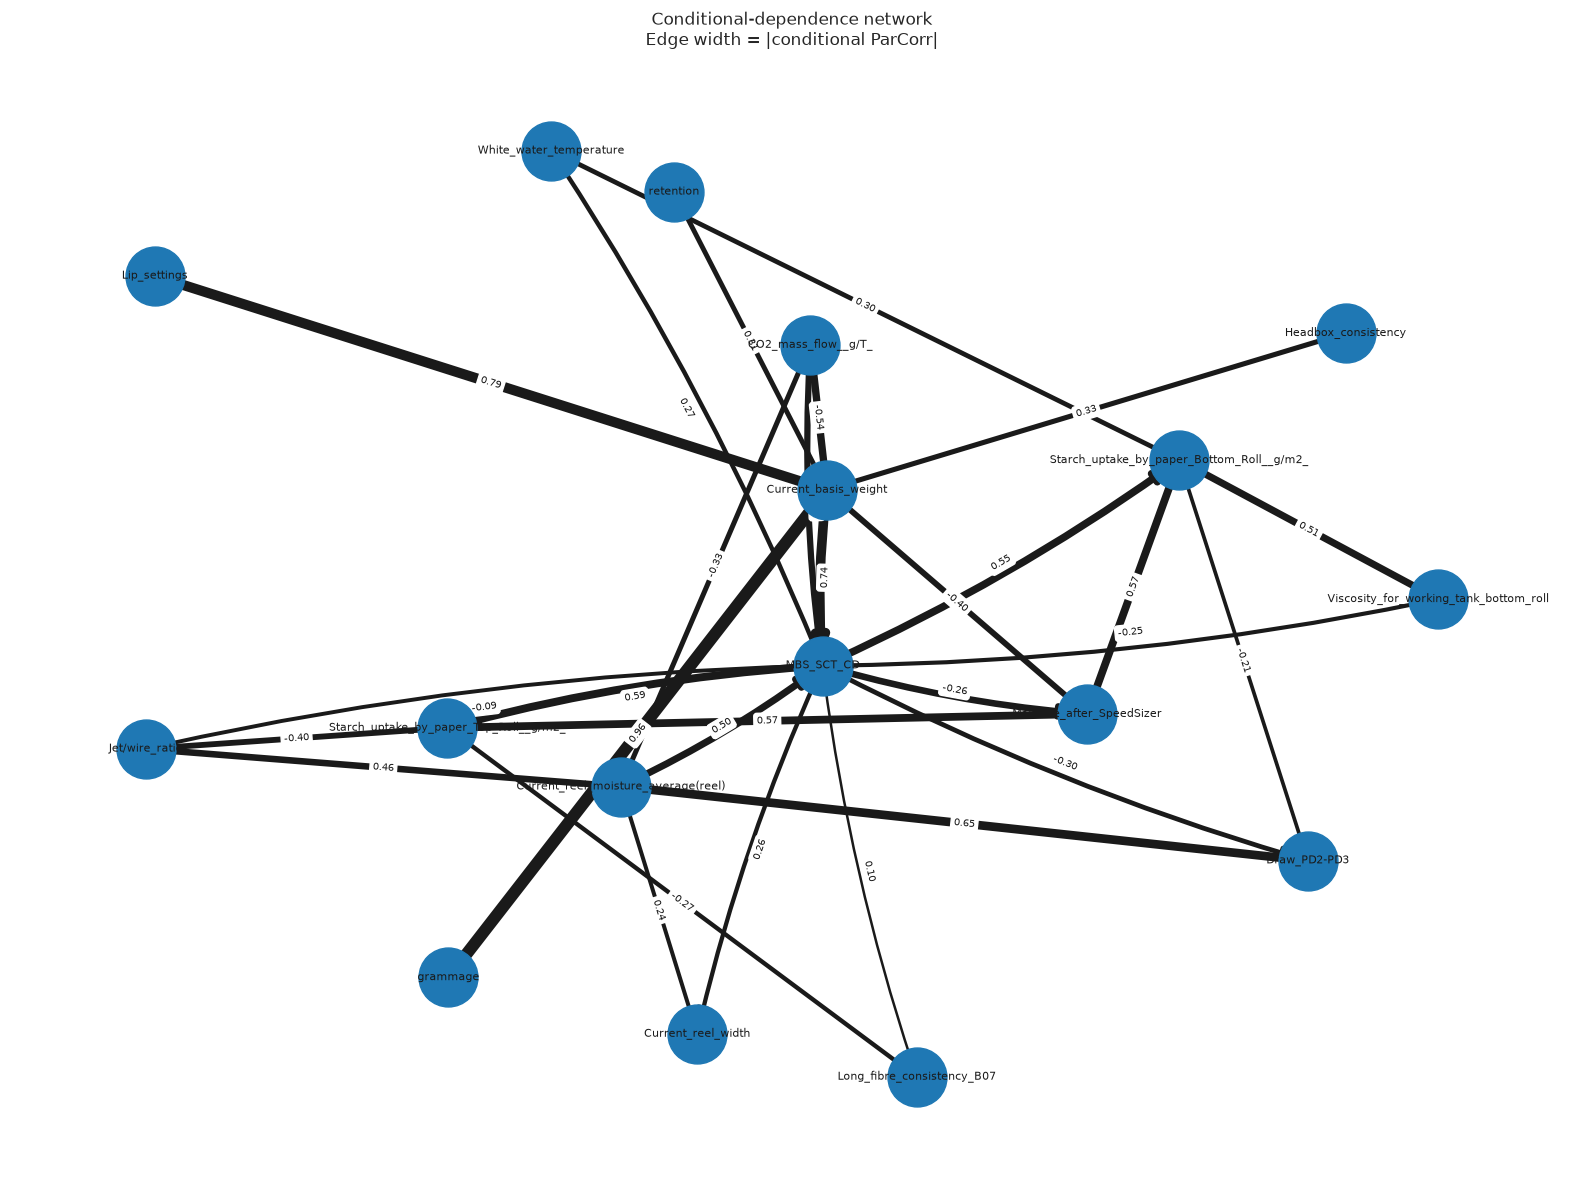

In [46]:
plot_dependence_graph(
    edge_summary,
    y_name="MBS_SCT_CD"
)

In [53]:
def hierarchical_positions(
    edge_summary,
    y_name="MBS_SCT_CD",
):
    """
    Arrange graph in 3 columns:

    left   = variables connected to SCT neighbours
    middle = variables directly linked to SCT
    right  = SCT output
    """

    # Direct neighbours of Y
    direct = sorted(
        set(
            edge_summary.loc[
                edge_summary["target"] == y_name,
                "source"
            ]
        )
    )

    # All remaining variables
    all_nodes = set(edge_summary["source"]) | set(edge_summary["target"])

    second_hop = sorted(
        all_nodes
        - set(direct)
        - {y_name}
    )

    pos = {}

    # SCT output
    pos[y_name] = (2.0, 0.0)

    # Direct neighbours
    if direct:
        ys = np.linspace(
            1.0,
            -1.0,
            len(direct)
        )

        for node, yy in zip(direct, ys):
            pos[node] = (1.0, yy)

    # Second-hop nodes
    if second_hop:
        ys = np.linspace(
            1.5,
            -1.5,
            len(second_hop)
        )

        for node, yy in zip(second_hop, ys):
            pos[node] = (0.0, yy)

    return pos

In [56]:
def plot_dependence_graph(
    edge_summary,
    y_name="MBS_SCT_CD",
    min_strength=0.05,
):

    G = nx.Graph()

    # --------------------------------------------------------
    # Add edges
    # --------------------------------------------------------

    for _, row in edge_summary.iterrows():

        if row["mean_strength"] < min_strength:
            continue

        G.add_edge(
            row["source"],
            row["target"],
            strength=row["mean_strength"],
            signed=row["mean_signed_strength"],
            type=row["type"],
            support=row["support_count"],
        )

    # --------------------------------------------------------
    # Hierarchical layout
    # --------------------------------------------------------

    pos = hierarchical_positions(
        edge_summary=edge_summary,
        y_name=y_name,
    )

    # Keep only nodes actually present in G
    pos = {
        node: xy
        for node, xy in pos.items()
        if node in G.nodes
    }

    plt.figure(figsize=(20, 12))

    # --------------------------------------------------------
    # Nodes
    # --------------------------------------------------------

    direct_nodes = [
        node
        for node in G.nodes
        if node != y_name
        and G.has_edge(node, y_name)
    ]

    other_nodes = [
        node
        for node in G.nodes
        if node not in direct_nodes
        and node != y_name
    ]

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=other_nodes,
        node_size=1600,
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=direct_nodes,
        node_size=1900,
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[y_name],
        node_size=2400,
    )

    # --------------------------------------------------------
    # Node labels
    # --------------------------------------------------------

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=8,
    )

    # --------------------------------------------------------
    # Predictor-predictor edges
    # --------------------------------------------------------

    undirected_edges = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d["type"] == "undirected"
    ]

    undirected_widths = [
        0.5 + 6 * G[u][v]["strength"]
        for u, v in undirected_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=undirected_edges,
        width=undirected_widths,
        alpha=0.55,
    )

    # --------------------------------------------------------
    # Edges into SCT
    # --------------------------------------------------------

    directed_edges = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d["type"] == "to_output"
    ]

    directed_widths = [
        1.0 + 8 * G[u][v]["strength"]
        for u, v in directed_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=directed_edges,
        width=directed_widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20,
        connectionstyle="arc3,rad=0.03",
    )

    # --------------------------------------------------------
    # Edge labels
    # --------------------------------------------------------

    edge_labels = {
        (u, v): f'{d["signed"]:.2f}'
        for u, v, d in G.edges(data=True)
        if d["type"] == "undirected"
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=7,
        label_pos=0.5,
    )

    plt.title(
        "Conditional-dependence network\n"
        "Edge width = |conditional ParCorr|"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

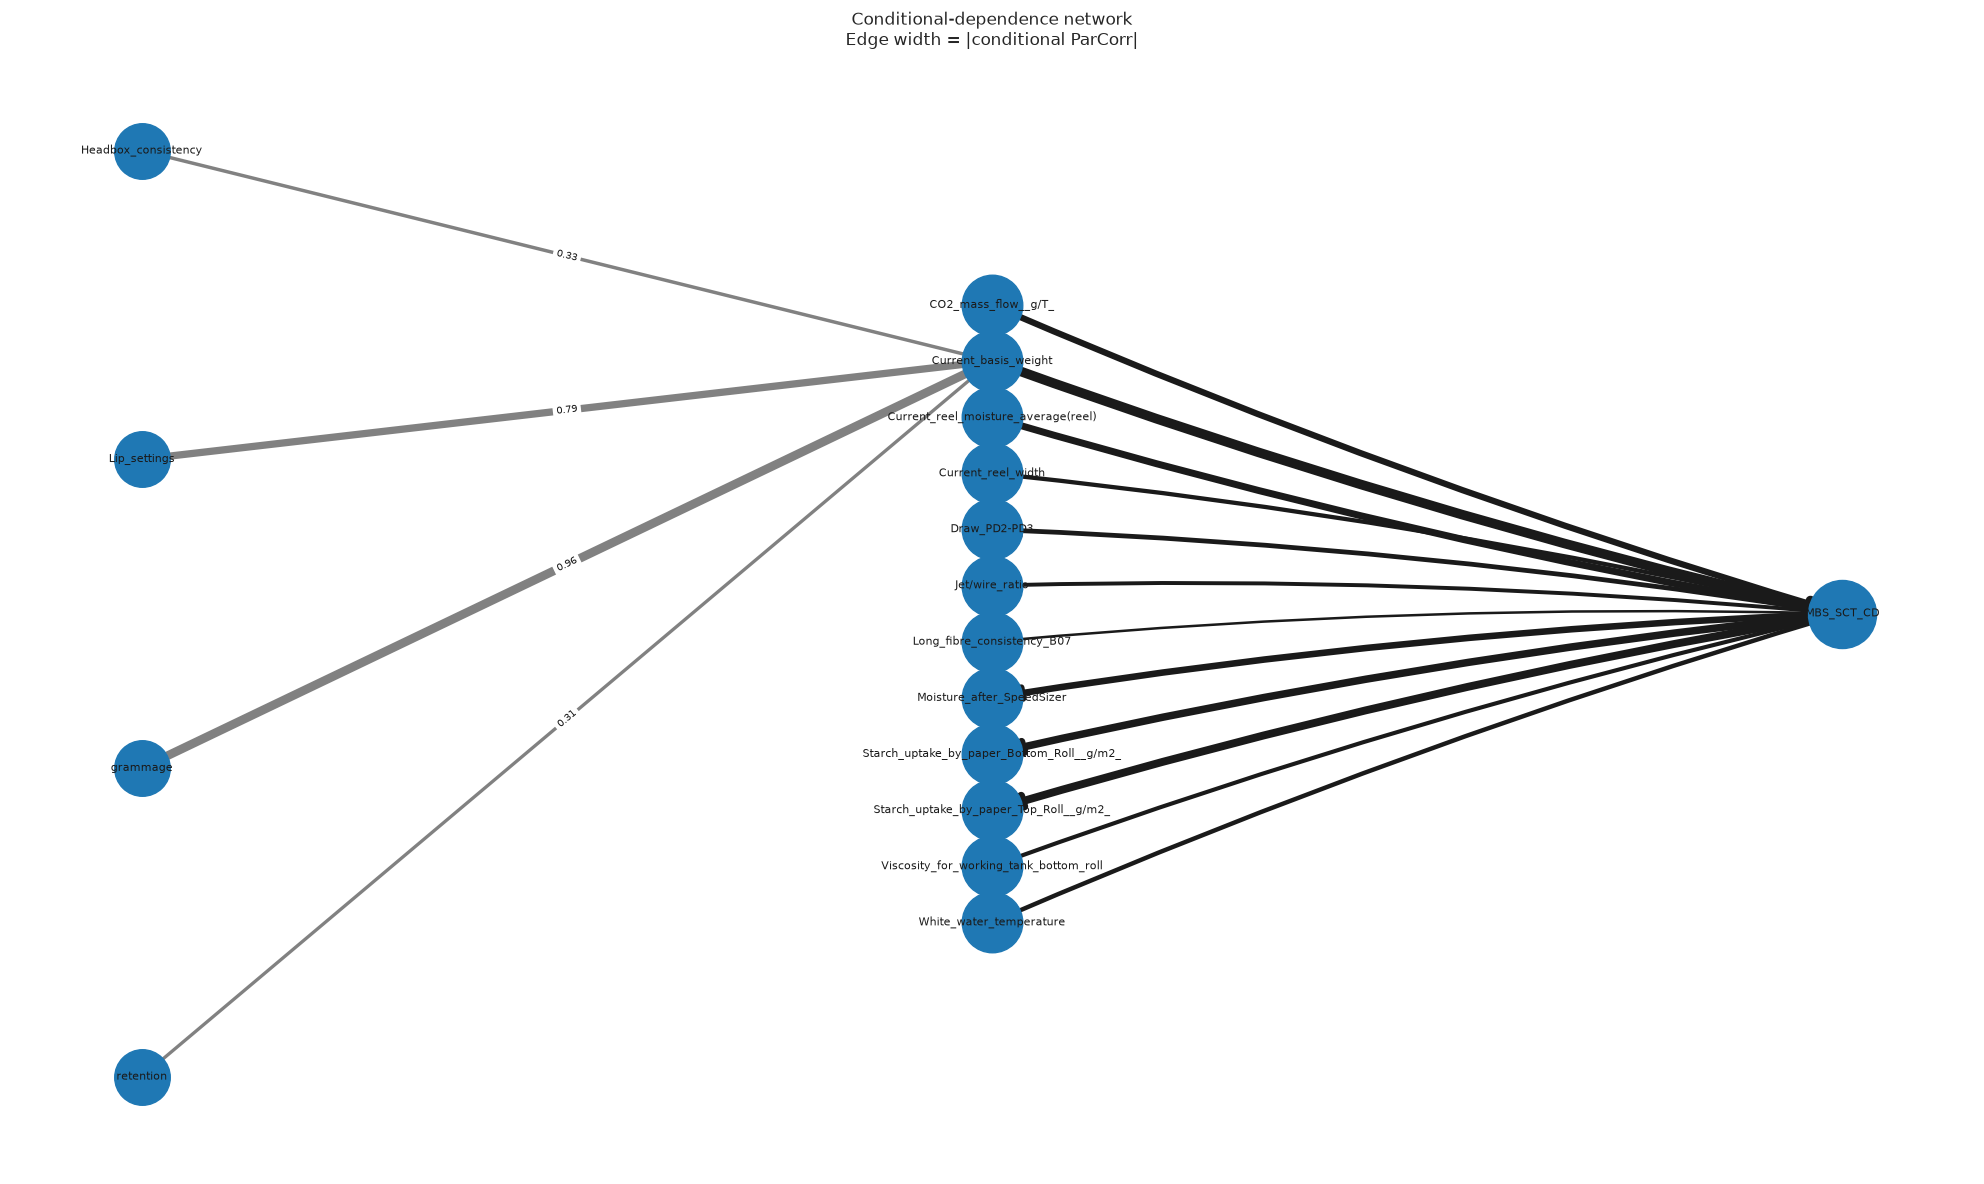

In [57]:
plot_dependence_graph(
    edge_summary,
    y_name="MBS_SCT_CD",
    min_strength=0.05,
)

# 5. No PCMCI+

In [10]:
"""
conditional_dependence_skeleton.py

PC-like contemporaneous conditional-dependence skeleton using Tigramite ParCorr.

An edge X--Y is removed when a conditioning set S with |S| <= max_cond_dim
makes the partial correlation practically negligible:

    abs(r(X, Y | S)) < min_abs_val

The p-value is retained for diagnostics but is not the pruning criterion.
Edges into the designated output can later be drawn as arrows by domain
convention; process-process edges remain undirected.
"""

from __future__ import annotations

from itertools import combinations
from pathlib import Path
from typing import Iterable, Optional

import networkx as nx
import pandas as pd
from tigramite.independence_tests.parcorr import ParCorr


OUTPUT_VAR = "MBS_SCT_CD"
MAX_COND_DIM = 3
MIN_ABS_VAL = 0.05
ALPHA = 0.05
OUTPUT_DIR = Path("conditional_dependence_results")


class ConditionalDependenceSkeleton:
    def __init__(
        self,
        dataframe,
        *,
        output_var: str = OUTPUT_VAR,
        max_cond_dim: int = MAX_COND_DIM,
        min_abs_val: float = MIN_ABS_VAL,
        alpha: float = ALPHA,
        verbosity: int = 1,
    ):
        self.dataframe = dataframe
        self.output_var = output_var
        self.max_cond_dim = int(max_cond_dim)
        self.min_abs_val = float(min_abs_val)
        self.alpha = float(alpha)
        self.verbosity = int(verbosity)

        self.var_names = list(dataframe.var_names)
        self.name_to_idx = {name: i for i, name in enumerate(self.var_names)}

        if self.output_var not in self.name_to_idx:
            raise ValueError(
                f"Output variable {self.output_var!r} is not in dataframe.var_names"
            )

        # This is the missing piece from the earlier snippets:
        # a ParCorr object used outside PCMCI must be attached to the dataframe.
        self.triple_parcorr = ParCorr(significance="analytic")
        self.triple_parcorr.set_dataframe(self.dataframe)

        self.graph_: Optional[nx.Graph] = None
        self.separation_df_: Optional[pd.DataFrame] = None
        self.edge_diagnostics_df_: Optional[pd.DataFrame] = None

    def parcorr_test(
        self,
        x_name: str,
        y_name: str,
        z_names: Optional[Iterable[str]] = None,
    ) -> dict:
        if z_names is None:
            z_names = []
        z_names = list(z_names)

        x = self.name_to_idx[x_name]
        y = self.name_to_idx[y_name]
        z = [self.name_to_idx[name] for name in z_names]

        val, pval = self.triple_parcorr.run_test(
            X=[(x, 0)],
            Y=[(y, 0)],
            Z=[(zz, 0) for zz in z],
        )

        return {"val": float(val), "p": float(pval)}

    def classify_test(self, result: dict) -> str:
        val = result["val"]
        p = result["p"]

        if p < self.alpha:
            if abs(val) >= self.min_abs_val:
                return "DEP"
            return "WEAK"
        return "INDEP"

    def practically_independent(self, result: dict) -> bool:
        return abs(result["val"]) < self.min_abs_val

    @staticmethod
    def _complete_graph(variable_names: list[str]) -> nx.Graph:
        G = nx.Graph()
        G.add_nodes_from(variable_names)
        G.add_edges_from(combinations(variable_names, 2))
        return G

    def fit(self, variable_names: Optional[Iterable[str]] = None) -> nx.Graph:
        """Build the conditional-dependence skeleton.

        The search is level-wise (Stable-PC-like): the adjacency structure is
        frozen at the start of each conditioning dimension. For each edge X--Y,
        candidate conditioners are taken from the union of the current
        neighbours of X and Y. The edge is removed as soon as a separating set
        is found.
        """
        if variable_names is None:
            variable_names = self.var_names
        else:
            variable_names = list(variable_names)

        missing = [v for v in variable_names if v not in self.name_to_idx]
        if missing:
            raise ValueError(f"Variables not found in dataframe: {missing}")

        G = self._complete_graph(variable_names)
        separation_records = []
        best_by_edge: dict[tuple[str, str], dict] = {}

        for k in range(self.max_cond_dim + 1):
            if self.verbosity:
                print(f"\nSearching conditioning sets of size {k}...")

            adjacency_snapshot = {
                node: set(G.neighbors(node)) for node in G.nodes
            }
            edges_snapshot = list(G.edges())
            removed_this_round = 0
            tested_this_round = 0

            for x_name, y_name in edges_snapshot:
                if not G.has_edge(x_name, y_name):
                    continue

                if k == 0:
                    cond_sets = [tuple()]
                else:
                    #if self.output_var in {x_name, y_name}:
                        # For relationships with the output, do not restrict the
                        # separating-set search to the current graph neighbourhood.
                    #    candidates = sorted(
                    #        set(variable_names) - {x_name, y_name}
                    #    )
                    #else:
                        # Keep the cheaper PC-like neighbourhood search for
                        # process-process relationships.
                    #    neigh_x = adjacency_snapshot[x_name] - {y_name}
                    #    neigh_y = adjacency_snapshot[y_name] - {x_name}

                    #    candidates = sorted(neigh_x | neigh_y)

                    neigh_x = adjacency_snapshot[x_name] - {y_name}
                    neigh_y = adjacency_snapshot[y_name] - {x_name}

                    candidates = sorted(neigh_x | neigh_y)

                    if len(candidates) < k:
                        continue

                    cond_sets = combinations(candidates, k)

                for cond_set in cond_sets:
                    tested_this_round += 1
                    result = self.parcorr_test(x_name, y_name, cond_set)
                    abs_val = abs(result["val"])
                    edge_key = tuple(sorted((x_name, y_name)))

                    current_best = best_by_edge.get(edge_key)
                    if current_best is None or abs_val < current_best["abs_val"]:
                        best_by_edge[edge_key] = {
                            "X": edge_key[0],
                            "Y": edge_key[1],
                            "best_conditioning_set": tuple(cond_set),
                            "best_cond_dim": k,
                            "val": result["val"],
                            "abs_val": abs_val,
                            "p": result["p"],
                            "status": self.classify_test(result),
                        }

                    if self.practically_independent(result):
                        G.remove_edge(x_name, y_name)
                        separation_records.append({
                            "X": edge_key[0],
                            "Y": edge_key[1],
                            "conditioning_set": tuple(cond_set),
                            "cond_dim": k,
                            "val": result["val"],
                            "abs_val": abs_val,
                            "p": result["p"],
                            "status": self.classify_test(result),
                        })
                        removed_this_round += 1
                        break

            if self.verbosity:
                print(f"Tested {tested_this_round:,} CI relations")
                print(
                    f"Removed {removed_this_round:,} edges; "
                    f"{G.number_of_edges():,} remain"
                )

            next_k = k + 1
            if next_k <= self.max_cond_dim:
                can_continue = False
                for x_name, y_name in G.edges():
                    candidates = (
                        (set(G.neighbors(x_name)) - {y_name})
                        | (set(G.neighbors(y_name)) - {x_name})
                    )
                    if len(candidates) >= next_k:
                        can_continue = True
                        break
                if not can_continue:
                    if self.verbosity:
                        print(
                            "Stopping early: no remaining edge has enough "
                            f"candidate conditioners for dimension {next_k}."
                        )
                    break

        self.graph_ = G
        self.separation_df_ = pd.DataFrame(
            separation_records,
            columns=[
                "X", "Y", "conditioning_set", "cond_dim",
                "val", "abs_val", "p", "status",
            ],
        )
        self.edge_diagnostics_df_ = pd.DataFrame(
            list(best_by_edge.values()),
            columns=[
                "X", "Y", "best_conditioning_set", "best_cond_dim",
                "val", "abs_val", "p", "status",
            ],
        )

        if not self.edge_diagnostics_df_.empty:
            retained = {tuple(sorted(edge)) for edge in G.edges()}
            self.edge_diagnostics_df_["retained"] = [
                (row.X, row.Y) in retained
                for row in self.edge_diagnostics_df_.itertuples()
            ]

        return G

    def neighbours(self, variable: str) -> list[str]:
        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")
        return sorted(self.graph_.neighbors(variable))

    def separating_record(self, x_name: str, y_name: str) -> pd.DataFrame:
        if self.separation_df_ is None:
            raise RuntimeError("Call fit() first.")
        a, b = sorted((x_name, y_name))
        return self.separation_df_[
            (self.separation_df_["X"] == a)
            & (self.separation_df_["Y"] == b)
        ].copy()

    def local_subgraph(
        self,
        center: Optional[str] = None,
        depth: int = 2,
    ) -> nx.Graph:
        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")
        if center is None:
            center = self.output_var

        nodes = {center}
        frontier = {center}
        for _ in range(depth):
            new_frontier = set()
            for node in frontier:
                new_frontier.update(self.graph_.neighbors(node))
            new_frontier -= nodes
            if not new_frontier:
                break
            nodes.update(new_frontier)
            frontier = new_frontier

        return self.graph_.subgraph(nodes).copy()

    def plot_edge_table(self, graph: Optional[nx.Graph] = None) -> pd.DataFrame:
        """Return edges with OUTPUT_VAR tagged as an output-directed edge.

        'to_output' is a display/domain convention, not a statistically inferred
        causal direction.
        """
        if graph is None:
            if self.graph_ is None:
                raise RuntimeError("Call fit() first.")
            graph = self.graph_

        rows = []
        for a, b in graph.edges():
            if a == self.output_var:
                rows.append({"source": b, "target": a, "type": "to_output"})
            elif b == self.output_var:
                rows.append({"source": a, "target": b, "type": "to_output"})
            else:
                aa, bb = sorted((a, b))
                rows.append({"source": aa, "target": bb, "type": "undirected"})
        return pd.DataFrame(rows)

    def save_results(
        self,
        output_dir: Path | str = OUTPUT_DIR,
        local_depth: int = 2,
    ) -> None:
        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")

        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        sep = self.separation_df_.copy()
        if not sep.empty:
            sep["conditioning_set"] = sep["conditioning_set"].apply(
                lambda x: " | ".join(x)
            )
            sep.to_csv(output_dir / "separation_sets.csv", index=False)

        diag = self.edge_diagnostics_df_.copy()
        if not diag.empty:
            diag["best_conditioning_set"] = diag["best_conditioning_set"].apply(
                lambda x: " | ".join(x)
            )
            diag.to_csv(output_dir / "edge_diagnostics.csv", index=False)

        nx.write_graphml(self.graph_, output_dir / "dependence_skeleton.graphml")

        local_graph = self.local_subgraph(self.output_var, depth=local_depth)
        nx.write_graphml(
            local_graph,
            output_dir / f"{self.output_var}_local.graphml",
        )
        self.plot_edge_table(local_graph).to_csv(
            output_dir / f"{self.output_var}_local_edges.csv",
            index=False,
        )


def run_dependence_analysis(
    dataframe,
    *,
    output_var: str = OUTPUT_VAR,
    variable_names: Optional[Iterable[str]] = None,
    max_cond_dim: int = MAX_COND_DIM,
    min_abs_val: float = MIN_ABS_VAL,
    alpha: float = ALPHA,
    output_dir: Optional[Path | str] = OUTPUT_DIR,
    verbosity: int = 1,
):
    analyser = ConditionalDependenceSkeleton(
        dataframe=dataframe,
        output_var=output_var,
        max_cond_dim=max_cond_dim,
        min_abs_val=min_abs_val,
        alpha=alpha,
        verbosity=verbosity,
    )

    graph = analyser.fit(variable_names=variable_names)
    output_neighbours = analyser.neighbours(output_var)

    if verbosity:
        print("\n" + "=" * 70)
        print("FINAL RESULT")
        print("=" * 70)
        print(f"Nodes: {graph.number_of_nodes()}")
        print(f"Edges: {graph.number_of_edges()}")
        print(f"\nRemaining direct neighbours of {output_var}:")
        for name in output_neighbours:
            print(f"  - {name}")

    if output_dir is not None:
        analyser.save_results(output_dir)
        if verbosity:
            print(f"\nResults written to: {Path(output_dir).resolve()}")

    local_graph = analyser.local_subgraph(output_var, depth=2)

    return {
        "analyser": analyser,
        "graph": graph,
        "separation_df": analyser.separation_df_,
        "edge_diagnostics_df": analyser.edge_diagnostics_df_,
        "output_neighbours": output_neighbours,
        "local_graph": local_graph,
        "local_edges": analyser.plot_edge_table(local_graph),
    }

results = run_dependence_analysis(
         dataframe=dataframe,
         output_var="MBS_SCT_CD",
         max_cond_dim=3,
         min_abs_val=0.05,
)


Searching conditioning sets of size 0...
Tested 903 CI relations
Removed 379 edges; 524 remain

Searching conditioning sets of size 1...


KeyboardInterrupt: 

In [81]:
print(results["output_neighbours"])

['Current_basis_weight', 'Starch_uptake_by_paper_Bottom_Roll__g/m2_', 'Starch_uptake_by_paper_Top_Roll__g/m2_']


In [82]:
print(
         results["analyser"].separating_record(
             "Speed",
             "MBS_SCT_CD",
         )
)

              X      Y                             conditioning_set  cond_dim  \
713  MBS_SCT_CD  Speed  (CO2_mass_flow__g/T_, Current_basis_weight)         2   

          val   abs_val         p status  
713 -0.016916  0.016916  0.113435  INDEP  


In [83]:
print(
         results["separation_df"]
         .sort_values(["cond_dim", "abs_val"])
         .head(50)
)

                                       X  \
7        Linepressure_2nd_press_FS__bar_   
203                         Draw_PD1-PD2   
83       Linepressure_2nd_press_FS__bar_   
9        Linepressure_2nd_press_DS__bar_   
127         Consistency_starch_main_line   
118          Bentonite_2_mass_flow__g/T_   
67   Current_reel_moisture_average(reel)   
288      Linepressure_2nd_press_FS__bar_   
287      Linepressure_2nd_press_FS__bar_   
2                           Draw_AD6-AD7   
364          Bentonite_2_mass_flow__g/T_   
343          Bentonite_2_mass_flow__g/T_   
98       Linepressure_2nd_press_FS__bar_   
277                       Jet/wire_ratio   
305         Conductivity_white_water_B46   
360          Bentonite_2_mass_flow__g/T_   
230                         Draw_PD3-PD4   
373          Short_fibre_B06_consistency   
104         Conductivity_white_water_B46   
279      Linepressure_2nd_press_FS__bar_   
249                         Draw_PD2-PD3   
306                   Current_re

In [84]:
for var in dataframe.var_names:
    if var == "MBS_SCT_CD":
        continue

    sep = results["analyser"].separating_record(
        var,
        "MBS_SCT_CD",
    )

    if len(sep) > 0:
        row = sep.iloc[0]

        print(
            f"{var:55s} "
            f"removed by {row['conditioning_set']} "
            f"r={row['val']:.3f}"
        )

retention                                               removed by ('Current_basis_weight',) r=-0.016
grammage                                                removed by ('Current_basis_weight',) r=0.028
Speed                                                   removed by ('CO2_mass_flow__g/T_', 'Current_basis_weight') r=-0.017
Moisture_after_SpeedSizer                               removed by ('retention',) r=0.031
Current_reel_moisture_average(reel)                     removed by ('CO2_mass_flow__g/T_',) r=0.046
SpeedSizer_Linepressure_DS                              removed by () r=-0.013
SpeedSizer_Linepressure_FS                              removed by () r=0.005
Viscosity_for_working_tank_bottom_roll                  removed by ('Current_reel_width',) r=0.050
Consistency_starch_main_line                            removed by ('Current_reel_width',) r=-0.042
Draw_PD5-SS                                             removed by ('Current_basis_weight',) r=-0.027
Draw_AD7-PR              

In [85]:
for var in results["output_neighbours"]:
    diag = results["edge_diagnostics_df"]

    mask = (
        (
            (diag["X"] == var)
            & (diag["Y"] == "MBS_SCT_CD")
        )
        |
        (
            (diag["Y"] == var)
            & (diag["X"] == "MBS_SCT_CD")
        )
    )

    print(
        diag.loc[
            mask,
            [
                "X",
                "Y",
                "best_conditioning_set",
                "best_cond_dim",
                "val",
                "abs_val",
                "p",
                "retained",
            ]
        ]
    )

                       X           Y  \
35  Current_basis_weight  MBS_SCT_CD   

                            best_conditioning_set  best_cond_dim      val  \
35  (Headbox_consistency, Lip_settings, grammage)              3  0.20675   

    abs_val             p  retained  
35  0.20675  3.642261e-85      True  
             X                                          Y  \
40  MBS_SCT_CD  Starch_uptake_by_paper_Bottom_Roll__g/m2_   

                                best_conditioning_set  best_cond_dim  \
40  (Current_basis_weight, Moisture_after_SpeedSiz...              3   

         val   abs_val             p  retained  
40  0.079978  0.079978  6.621380e-14      True  
             X                                       Y  \
41  MBS_SCT_CD  Starch_uptake_by_paper_Top_Roll__g/m2_   

                                best_conditioning_set  best_cond_dim     val  \
41  (Headbox_consistency, Lip_settings, Moisture_a...              3  0.1571   

    abs_val             p  retained  
41   0

In [86]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


def plot_sct_dependence_graph(
    results,
    output_var="MBS_SCT_CD",
    depth=2,
    min_edge_strength=0.05,
    figsize=(18, 12),
):
    """
    Plot the local conditional-dependence skeleton around SCT.

    Interpretation
    --------------
    * Edges into SCT are arrows only because SCT is assumed to be an output.
    * Process-process edges are undirected.
    * Edge width represents robustness:

          min |partial correlation|

      found across all conditioning sets tested for that retained edge.
    """

    analyser = results["analyser"]
    G_full = results["graph"]
    diagnostics = results["edge_diagnostics_df"].copy()

    # --------------------------------------------------------
    # 1. Local two-hop graph
    # --------------------------------------------------------

    G = analyser.local_subgraph(
        center=output_var,
        depth=depth,
    )

    direct_nodes = set(G_full.neighbors(output_var))

    second_hop_nodes = (
        set(G.nodes())
        - direct_nodes
        - {output_var}
    )

    print("Direct SCT neighbours:")
    for node in sorted(direct_nodes):
        print("  ", node)

    print("\nSecond-hop variables:")
    for node in sorted(second_hop_nodes):
        print("  ", node)

    # --------------------------------------------------------
    # 2. Lookup robustness of retained edges
    # --------------------------------------------------------

    strength_lookup = {}

    for row in diagnostics.itertuples():

        if not row.retained:
            continue

        key = tuple(sorted((row.X, row.Y)))

        strength_lookup[key] = {
            "strength": row.abs_val,
            "signed": row.val,
            "conditioning_set": row.best_conditioning_set,
        }

    # --------------------------------------------------------
    # 3. Remove very weak retained edges if desired
    # --------------------------------------------------------

    edges_to_remove = []

    for a, b in G.edges():

        key = tuple(sorted((a, b)))

        info = strength_lookup.get(key)

        if info is None:
            continue

        if info["strength"] < min_edge_strength:
            edges_to_remove.append((a, b))

    G.remove_edges_from(edges_to_remove)

    # Remove isolated second-hop nodes
    isolated = [
        node
        for node in G.nodes()
        if node != output_var
        and G.degree(node) == 0
    ]

    G.remove_nodes_from(isolated)

    # Recalculate groups
    direct_nodes = set(G.neighbors(output_var))

    second_hop_nodes = (
        set(G.nodes())
        - direct_nodes
        - {output_var}
    )

    # --------------------------------------------------------
    # 4. Hierarchical positions
    # --------------------------------------------------------

    pos = {}

    # SCT on right
    pos[output_var] = (2.2, 0)

    # Direct neighbours in middle
    direct_sorted = sorted(direct_nodes)

    if direct_sorted:
        ys = np.linspace(
            1.2,
            -1.2,
            len(direct_sorted),
        )

        for node, y in zip(direct_sorted, ys):
            pos[node] = (1.15, y)

    # Second-hop variables on left.
    #
    # Position each one close to the average y-position of the
    # direct nodes to which it is connected.
    second_sorted = sorted(second_hop_nodes)

    grouped = []

    for node in second_sorted:

        linked_direct = [
            neighbour
            for neighbour in G.neighbors(node)
            if neighbour in direct_nodes
        ]

        if linked_direct:
            target_y = np.mean(
                [pos[n][1] for n in linked_direct]
            )
        else:
            target_y = 0

        grouped.append(
            (node, target_y)
        )

    grouped.sort(key=lambda x: -x[1])

    # Add some vertical spreading so labels do not overlap
    if grouped:
        raw_y = np.array(
            [v for _, v in grouped]
        )

        # Start with ordered evenly spaced positions
        spread_y = np.linspace(
            2.5,
            -2.5,
            len(grouped),
        )

        for (node, _), y in zip(
            grouped,
            spread_y,
        ):
            pos[node] = (0, y)

    # --------------------------------------------------------
    # 5. Plot nodes
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=sorted(second_hop_nodes),
        node_size=1500,
        alpha=0.75,
        ax=ax,
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=sorted(direct_nodes),
        node_size=2300,
        alpha=0.9,
        ax=ax,
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[output_var],
        node_size=3200,
        ax=ax,
    )

    # --------------------------------------------------------
    # 6. Process-process edges
    # --------------------------------------------------------

    process_edges = []

    for a, b in G.edges():

        if output_var not in {a, b}:
            process_edges.append((a, b))

    process_widths = []

    for a, b in process_edges:

        key = tuple(sorted((a, b)))

        strength = strength_lookup.get(
            key,
            {"strength": min_edge_strength},
        )["strength"]

        process_widths.append(
            0.5 + 7 * strength
        )

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=process_edges,
        width=process_widths,
        alpha=0.45,
        arrows=False,
        ax=ax,
    )

    # --------------------------------------------------------
    # 7. SCT edges as arrows
    # --------------------------------------------------------

    output_edges = []

    for node in direct_nodes:
        output_edges.append(
            (node, output_var)
        )

    output_widths = []

    for a, b in output_edges:

        key = tuple(sorted((a, b)))

        strength = strength_lookup.get(
            key,
            {"strength": min_edge_strength},
        )["strength"]

        output_widths.append(
            1.0 + 9 * strength
        )

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=output_edges,
        width=output_widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=25,
        min_source_margin=25,
        min_target_margin=35,
        ax=ax,
    )

    # --------------------------------------------------------
    # 8. Labels
    # --------------------------------------------------------

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=9,
        ax=ax,
    )

    # --------------------------------------------------------
    # 9. Optional SCT-edge strength labels
    # --------------------------------------------------------

    edge_labels = {}

    for a, b in output_edges:

        key = tuple(sorted((a, b)))

        info = strength_lookup.get(key)

        if info is not None:
            edge_labels[(a, b)] = (
                f"{info['strength']:.2f}"
            )

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=9,
        rotate=False,
        label_pos=0.55,
        ax=ax,
    )

    # --------------------------------------------------------
    # 10. Titles / annotations
    # --------------------------------------------------------

    ax.set_title(
        "Conditional-dependence structure around SCT CD\n"
        "Edge width = minimum |partial correlation| "
        "across tested conditioning sets",
        fontsize=14,
    )

    ax.text(
        0,
        2.8,
        "Related process variables",
        ha="center",
        fontsize=11,
    )

    ax.text(
        1.15,
        1.65,
        "Robust direct SCT neighbours",
        ha="center",
        fontsize=11,
    )

    ax.text(
        2.2,
        0.45,
        "Output",
        ha="center",
        fontsize=11,
    )

    ax.axis("off")

    plt.tight_layout()

    return fig, ax, G

Direct SCT neighbours:
   Current_basis_weight
   Starch_uptake_by_paper_Bottom_Roll__g/m2_
   Starch_uptake_by_paper_Top_Roll__g/m2_

Second-hop variables:
   Jet/wire_ratio
   Long_fibre_consistency_B07
   Moisture_after_SpeedSizer
   Viscosity_for_working_tank_bottom_roll
   White_water_temperature
   grammage


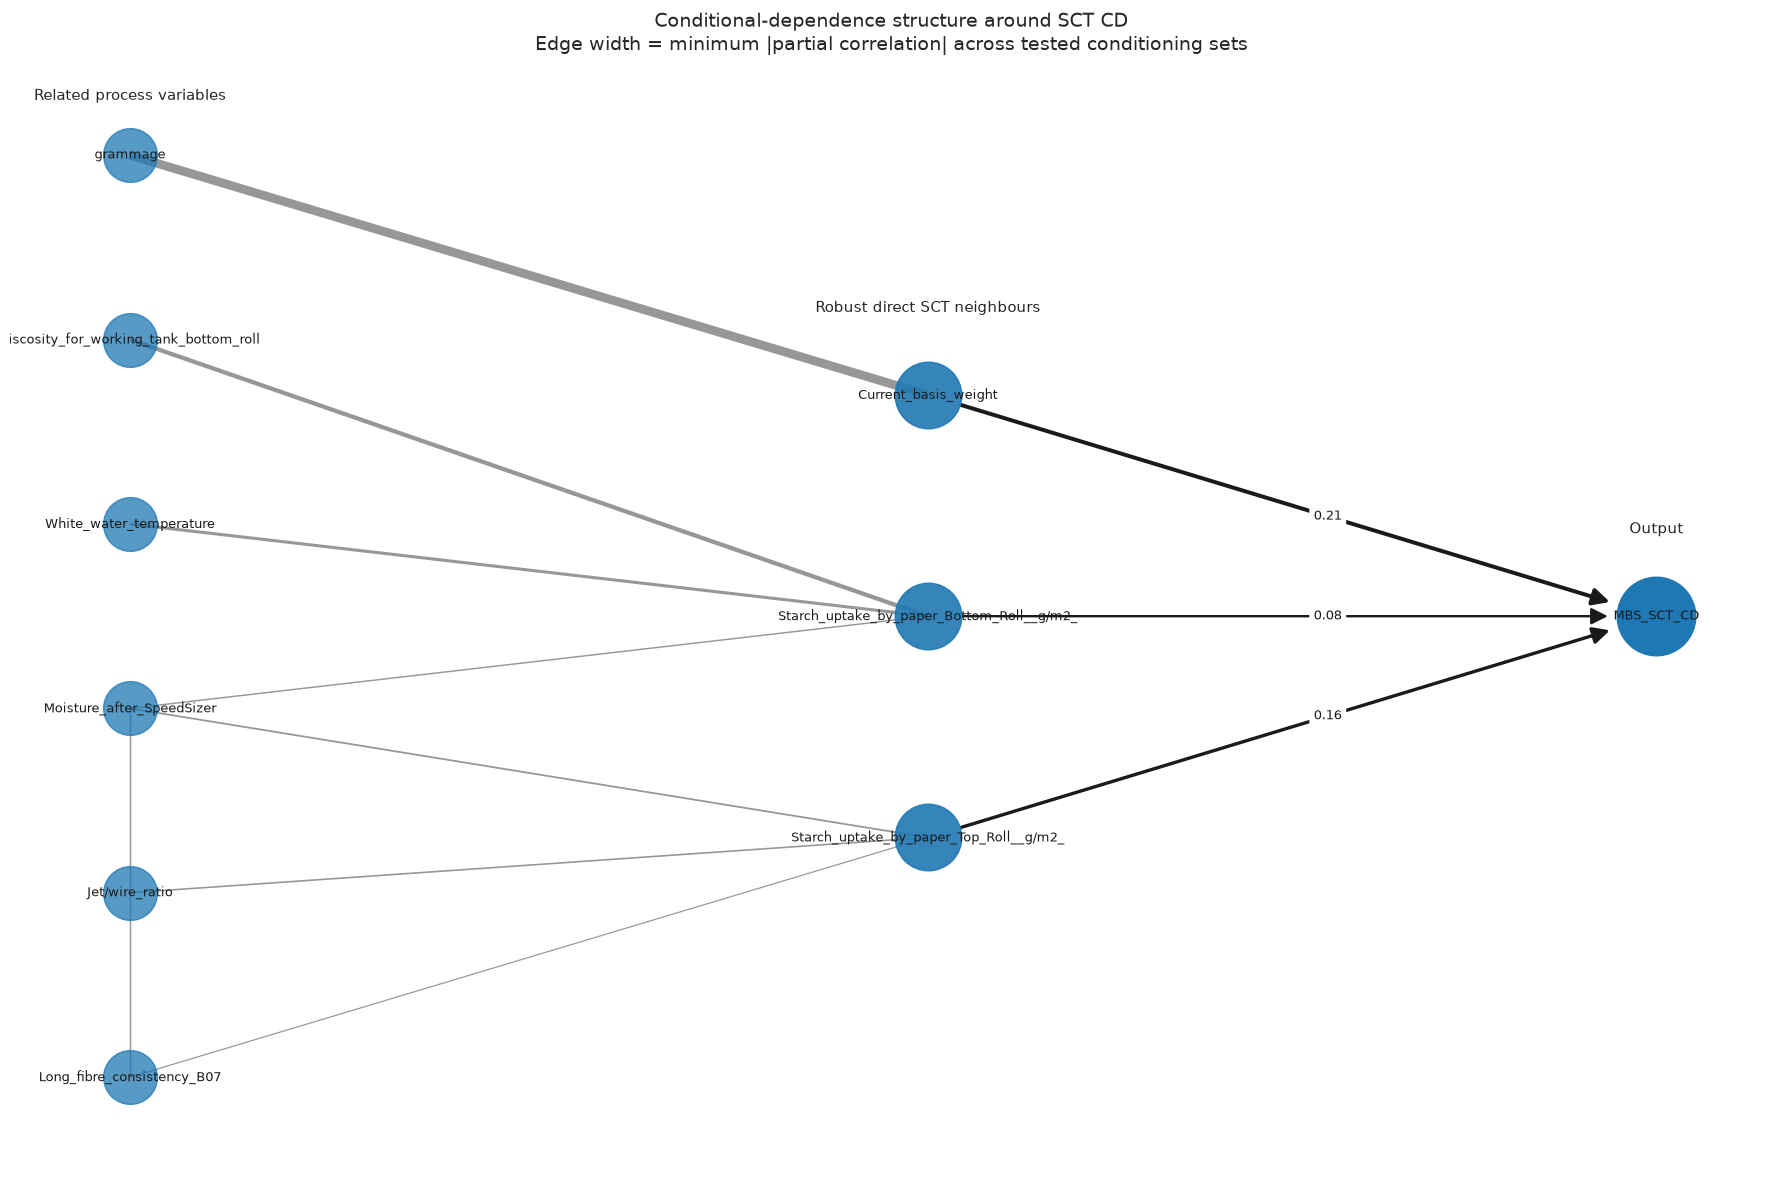

In [87]:
fig, ax, G_sct = plot_sct_dependence_graph(
    results,
    output_var="MBS_SCT_CD",
    depth=2,
)

plt.show()

# 6. Filtering

In [17]:
import pandas as pd
import numpy as np
import tigramite.data_processing as pp


def ewm_filter_by_segment(
    df,
    columns,
    halflife="120min",
    max_gap="12h",
):
    df = df.copy().sort_index()

    # New segment at grade change or >12 h gap
    grade_change = (
        df["AB_Grade_ID"]
        .ne(df["AB_Grade_ID"].shift().fillna(True))
    )

    time_gap = (
        df.index.to_series()
        .diff()
        .gt(pd.Timedelta(max_gap)
        ).fillna(False)
    )

    segment_start = (grade_change | time_gap).fillna(True)

    segment = pd.Series(
        segment_start.to_numpy(dtype=bool),
        index=df.index,
    ).cumsum()

    result = df.copy()

    for _, idx in df.groupby(segment).groups.items():

        block = df.loc[idx, columns]

        result.loc[idx, columns] = (
            block
            .ewm(
                halflife=halflife,
                times=block.index,
                adjust=True,
            )
            .mean()
        )

    return result

In [ ]:
filtered_data = ewm_filter_by_segment(
    turnup_data,
    columns=var_names,
    halflife="240min",
)

In [94]:
data_array_filtered = (
    filtered_data[var_names]
    .dropna()
    .values
)

dataframe_filtered = pp.DataFrame(
    data_array_filtered,
    var_names=var_names,
)

In [95]:
results_ewm = run_dependence_analysis(
    dataframe=dataframe_filtered,
    output_var="MBS_SCT_CD",
    max_cond_dim=3,
    min_abs_val=0.05,
)


Searching conditioning sets of size 0...
Tested 903 CI relations
Removed 315 edges; 588 remain

Searching conditioning sets of size 1...
Tested 11,271 CI relations
Removed 376 edges; 212 remain

Searching conditioning sets of size 2...
Tested 16,691 CI relations
Removed 115 edges; 97 remain

Searching conditioning sets of size 3...
Tested 36,667 CI relations
Removed 21 edges; 76 remain

FINAL RESULT
Nodes: 43
Edges: 76

Remaining direct neighbours of MBS_SCT_CD:
  - Current_basis_weight
  - Starch_uptake_by_paper_Bottom_Roll__g/m2_
  - Starch_uptake_by_paper_Top_Roll__g/m2_

Results written to: /home/susarro/workspace/costimiser/TFP/src/conditional_dependence_results


In [96]:
print(results_ewm["output_neighbours"])

['Current_basis_weight', 'Starch_uptake_by_paper_Bottom_Roll__g/m2_', 'Starch_uptake_by_paper_Top_Roll__g/m2_']


In [97]:
a = results_ewm["analyser"]

print(
    "Jet-wire vs SCT:",
    a.parcorr_test(
        "Jet/wire_ratio",
        "MBS_SCT_CD",
    )
)

Jet-wire vs SCT: {'val': -0.10162408247538178, 'p': 1.5013414957392477e-21}


In [98]:
print(
    a.separating_record(
        "Jet/wire_ratio",
        "MBS_SCT_CD",
    )
)

                  X           Y conditioning_set  cond_dim       val  \
331  Jet/wire_ratio  MBS_SCT_CD  (Draw_PD2-PD3,)         1  0.010924   

      abs_val         p status  
331  0.010924  0.306638  INDEP  


In [99]:
a = results_ewm["analyser"]

print(
    "JW - SCT       ",
    a.parcorr_test(
        "Jet/wire_ratio",
        "MBS_SCT_CD",
    )
)

print(
    "JW - Draw      ",
    a.parcorr_test(
        "Jet/wire_ratio",
        "Draw_PD2-PD3",
    )
)

print(
    "Draw - SCT     ",
    a.parcorr_test(
        "Draw_PD2-PD3",
        "MBS_SCT_CD",
    )
)

print(
    "JW - SCT|Draw  ",
    a.parcorr_test(
        "Jet/wire_ratio",
        "MBS_SCT_CD",
        ["Draw_PD2-PD3"],
    )
)

print(
    "Draw - SCT|JW  ",
    a.parcorr_test(
        "Draw_PD2-PD3",
        "MBS_SCT_CD",
        ["Jet/wire_ratio"],
    )
)

JW - SCT        {'val': -0.10162408247538178, 'p': 1.5013414957392477e-21}
JW - Draw       {'val': 0.5115563062585016, 'p': 0.0}
Draw - SCT      {'val': -0.21657082353170135, 'p': 1.7204896876676843e-93}
JW - SCT|Draw   {'val': 0.010924492382504657, 'p': 0.30663766334558656}
Draw - SCT|JW   {'val': -0.1925410983203611, 'p': 6.461318271421279e-74}


Direct SCT neighbours:
   Current_basis_weight
   Starch_uptake_by_paper_Bottom_Roll__g/m2_
   Starch_uptake_by_paper_Top_Roll__g/m2_

Second-hop variables:
   Headbox_consistency
   Jet/wire_ratio
   Moisture_after_SpeedSizer
   Viscosity_for_working_tank_bottom_roll
   White_water_temperature
   grammage
   retention


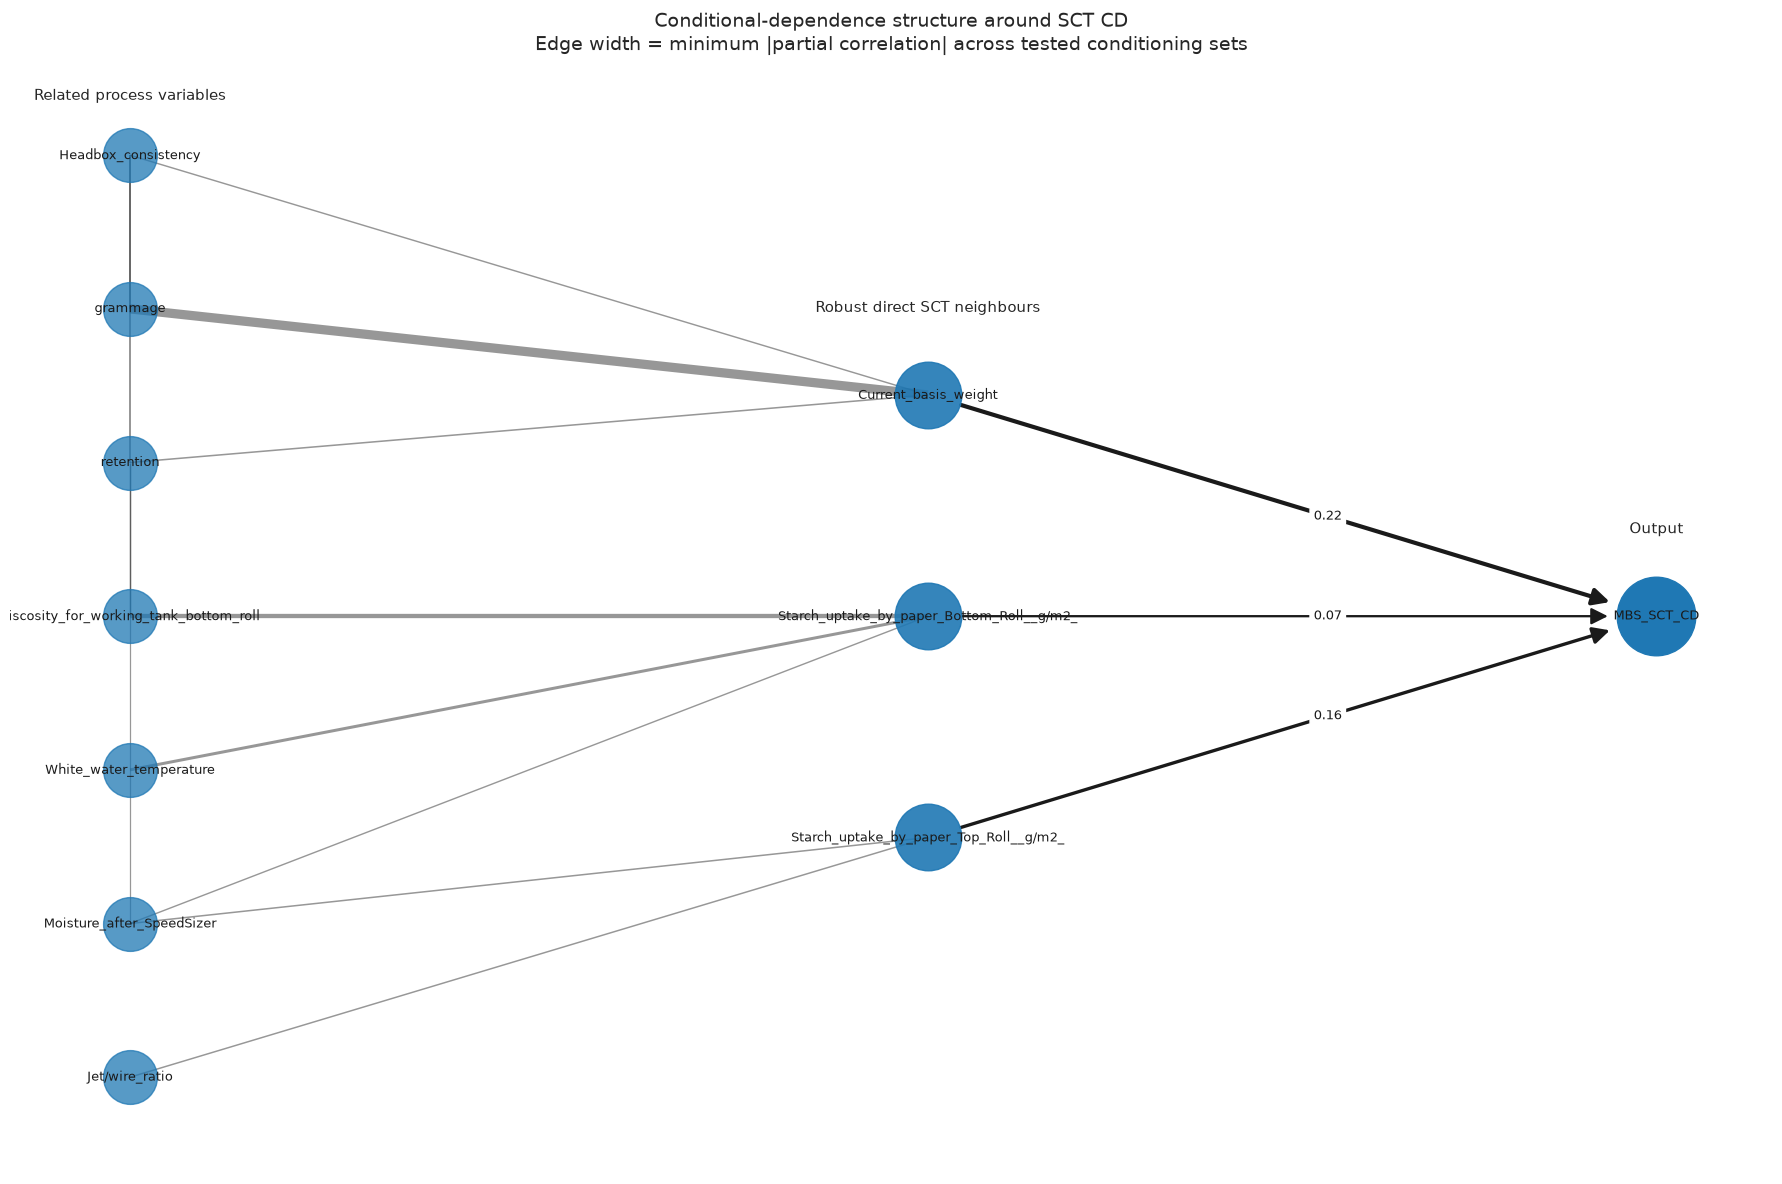

In [100]:
fig, ax, G_sct = plot_sct_dependence_graph(
    results_ewm,
    output_var="MBS_SCT_CD",
    depth=2,
)

plt.show()

In [101]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


def build_sct_pathway_graph(
    results,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
    max_depth=4,
):
    """
    Build an explanatory pathway graph around SCT.

    Interpretation
    --------------
    1. Variables that survive as direct SCT neighbours are connected
       directly to SCT.

    2. If X-SCT was removed by a SINGLE separator Z, retain X by
       connecting X--Z, provided X and Z themselves have a meaningful
       marginal relationship.

       Then recursively explain how Z relates to SCT.

    3. If X-SCT was removed by a MULTIVARIABLE separator, create a
       synthetic 'separator set' node. This prevents us from incorrectly
       pretending that either member alone explains the relationship.

    IMPORTANT:
    This is an explanatory dependence graph, not a discovered causal DAG.
    Only arrows into SCT are imposed by domain knowledge.
    """

    analyser = results["analyser"]
    skeleton = results["graph"]
    separation_df = results["separation_df"]

    G = nx.Graph()

    G.add_node(
        output_var,
        node_type="output",
    )

    # --------------------------------------------------------
    # Lookup: how was variable -- SCT removed?
    # --------------------------------------------------------

    def get_separator(var):
        sep = analyser.separating_record(
            var,
            output_var,
        )

        if sep.empty:
            return None

        # The algorithm records the first/smallest separator found.
        row = sep.iloc[0]

        return {
            "conditioning_set": tuple(
                row["conditioning_set"]
            ),
            "val": row["val"],
            "abs_val": row["abs_val"],
            "p": row["p"],
            "cond_dim": row["cond_dim"],
        }

    # --------------------------------------------------------
    # Helper: relationship between two process variables
    # --------------------------------------------------------

    def process_relation(a, b):

        result = analyser.parcorr_test(a, b)

        return {
            "val": result["val"],
            "abs_val": abs(result["val"]),
            "p": result["p"],
            "supported": abs(result["val"]) >= min_abs_val,
        }

    # --------------------------------------------------------
    # Recursive explanation
    # --------------------------------------------------------

    visited = set()

    def explain_variable(var, depth=0):

        if depth > max_depth:
            return

        key = (var, depth)

        if key in visited:
            return

        visited.add(key)

        # ----------------------------------------------
        # Case 1:
        # retained direct SCT neighbour
        # ----------------------------------------------

        if skeleton.has_edge(var, output_var):

            diagnostics = results["edge_diagnostics_df"]

            mask = (
                (
                    (diagnostics["X"] == var)
                    & (diagnostics["Y"] == output_var)
                )
                |
                (
                    (diagnostics["Y"] == var)
                    & (diagnostics["X"] == output_var)
                )
            )

            strength = np.nan

            tmp = diagnostics.loc[mask]

            if len(tmp):
                strength = float(
                    tmp.iloc[0]["abs_val"]
                )

            G.add_node(
                var,
                node_type="direct",
            )

            G.add_edge(
                var,
                output_var,
                edge_type="to_output",
                strength=strength,
            )

            return

        # ----------------------------------------------
        # Case 2:
        # removed SCT relationship
        # ----------------------------------------------

        separator = get_separator(var)

        if separator is None:
            return

        cond_set = separator["conditioning_set"]

        # Marginally independent already
        if len(cond_set) == 0:
            return

        G.add_node(
            var,
            node_type="process",
        )

        # ----------------------------------------------
        # SINGLE separator
        # ----------------------------------------------

        if len(cond_set) == 1:

            z = cond_set[0]

            rel = process_relation(var, z)

            # Do not invent a pathway if X-Z itself is weak.
            if not rel["supported"]:
                return

            G.add_node(
                z,
                node_type="separator",
            )

            G.add_edge(
                var,
                z,
                edge_type="process",
                strength=rel["abs_val"],
                signed_strength=rel["val"],
            )

            explain_variable(
                z,
                depth + 1,
            )

        # ----------------------------------------------
        # MULTIVARIABLE separator
        # ----------------------------------------------

        else:

            # Represent the SET explicitly.
            #
            # Example:
            #
            #   Speed -- {CO2 + Basis weight}
            #
            # rather than incorrectly claiming
            #
            #   Speed -- CO2
            #
            # is sufficient by itself.

            sep_label = (
                "{"
                + " + ".join(cond_set)
                + "}"
            )

            G.add_node(
                sep_label,
                node_type="separator_set",
                members=cond_set,
            )

            G.add_edge(
                var,
                sep_label,
                edge_type="joint_separator",
                strength=abs(
                    analyser.parcorr_test(
                        var,
                        output_var,
                    )["val"]
                ),
            )

            # Connect separator-set node to its members.
            for z in cond_set:

                G.add_node(
                    z,
                    node_type="separator",
                )

                G.add_edge(
                    sep_label,
                    z,
                    edge_type="set_member",
                    strength=0.05,
                )

                explain_variable(
                    z,
                    depth + 1,
                )

    # --------------------------------------------------------
    # Start from every variable that has some relationship
    # with SCT
    # --------------------------------------------------------

    for var in analyser.var_names:

        if var == output_var:
            continue

        marginal = analyser.parcorr_test(
            var,
            output_var,
        )

        if abs(marginal["val"]) >= min_abs_val:
            explain_variable(
                var,
                depth=0,
            )

    return G

In [102]:
def plot_sct_pathway_graph(
    results,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
    max_depth=4,
    figsize=(20, 14),
):

    G = build_sct_pathway_graph(
        results,
        output_var=output_var,
        min_abs_val=min_abs_val,
        max_depth=max_depth,
    )

    # --------------------------------------------------------
    # Distance from SCT for hierarchical layout
    # --------------------------------------------------------

    distances = {}

    for node in G.nodes():

        try:
            distances[node] = nx.shortest_path_length(
                G,
                source=node,
                target=output_var,
            )
        except nx.NetworkXNoPath:
            distances[node] = max_depth + 1

    max_distance = max(
        distances.values(),
        default=1,
    )

    pos = {}

    # SCT on far right
    pos[output_var] = (
        max_distance,
        0,
    )

    # Nodes grouped by distance from SCT
    for d in range(1, max_distance + 1):

        nodes = [
            n
            for n, dist in distances.items()
            if dist == d
        ]

        nodes = sorted(nodes)

        if not nodes:
            continue

        ys = np.linspace(
            2.5,
            -2.5,
            len(nodes),
        )

        for node, yy in zip(nodes, ys):

            pos[node] = (
                max_distance - d,
                yy,
            )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=figsize
    )

    node_types = nx.get_node_attributes(
        G,
        "node_type",
    )

    # Output
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G
            if node_types.get(n) == "output"
        ],
        node_size=3200,
        ax=ax,
    )

    # Robust direct neighbours
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G
            if node_types.get(n) == "direct"
        ],
        node_size=2300,
        alpha=0.9,
        ax=ax,
    )

    # Ordinary process/separator variables
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G
            if node_types.get(n)
            in {"process", "separator"}
        ],
        node_size=1600,
        alpha=0.75,
        ax=ax,
    )

    # Joint separator sets
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G
            if node_types.get(n) == "separator_set"
        ],
        node_size=2300,
        node_shape="s",
        alpha=0.65,
        ax=ax,
    )

    # --------------------------------------------------------
    # Process-process edges
    # --------------------------------------------------------

    process_edges = []

    for u, v, data in G.edges(data=True):

        if data["edge_type"] == "process":
            process_edges.append(
                (u, v)
            )

    process_widths = [
        0.5
        + 6
        * G[u][v].get(
            "strength",
            min_abs_val,
        )
        for u, v in process_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=process_edges,
        width=process_widths,
        alpha=0.55,
        arrows=False,
        ax=ax,
    )

    # --------------------------------------------------------
    # Direct SCT edges
    # --------------------------------------------------------

    output_edges = [
        (u, v)
        for u, v, data
        in G.edges(data=True)
        if data["edge_type"]
        == "to_output"
    ]

    output_widths = [
        1
        + 8
        * G[u][v].get(
            "strength",
            min_abs_val,
        )
        for u, v in output_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=output_edges,
        width=output_widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=25,
        min_source_margin=25,
        min_target_margin=35,
        ax=ax,
    )

    # --------------------------------------------------------
    # Joint-separator edges
    # --------------------------------------------------------

    joint_edges = [
        (u, v)
        for u, v, data
        in G.edges(data=True)
        if data["edge_type"]
        == "joint_separator"
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=joint_edges,
        width=1.5,
        style="dashed",
        alpha=0.6,
        ax=ax,
    )

    # Separator-set membership
    member_edges = [
        (u, v)
        for u, v, data
        in G.edges(data=True)
        if data["edge_type"]
        == "set_member"
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=member_edges,
        width=0.8,
        style="dotted",
        alpha=0.45,
        ax=ax,
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    display_names = {
        "Current_basis_weight":
            "Basis weight",

        "Starch_uptake_by_paper_Top_Roll__g/m2_":
            "Top starch",

        "Starch_uptake_by_paper_Bottom_Roll__g/m2_":
            "Bottom starch",

        "Jet/wire_ratio":
            "Jet-wire difference",

        "Draw_PD2-PD3":
            "Draw PD2-PD3",

        "Headbox_consistency":
            "Headbox consistency",

        "CO2_mass_flow__g/T_":
            "CO2 g/T",
    }

    labels = {
        node: display_names.get(
            node,
            node,
        )
        for node in G.nodes()
    }

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=8,
        ax=ax,
    )

    ax.set_title(
        "SCT CD explanatory conditional-dependence pathways\n"
        "Removed relationships are retained through their separating variables",
        fontsize=14,
    )

    ax.axis("off")

    plt.tight_layout()

    return fig, ax, G

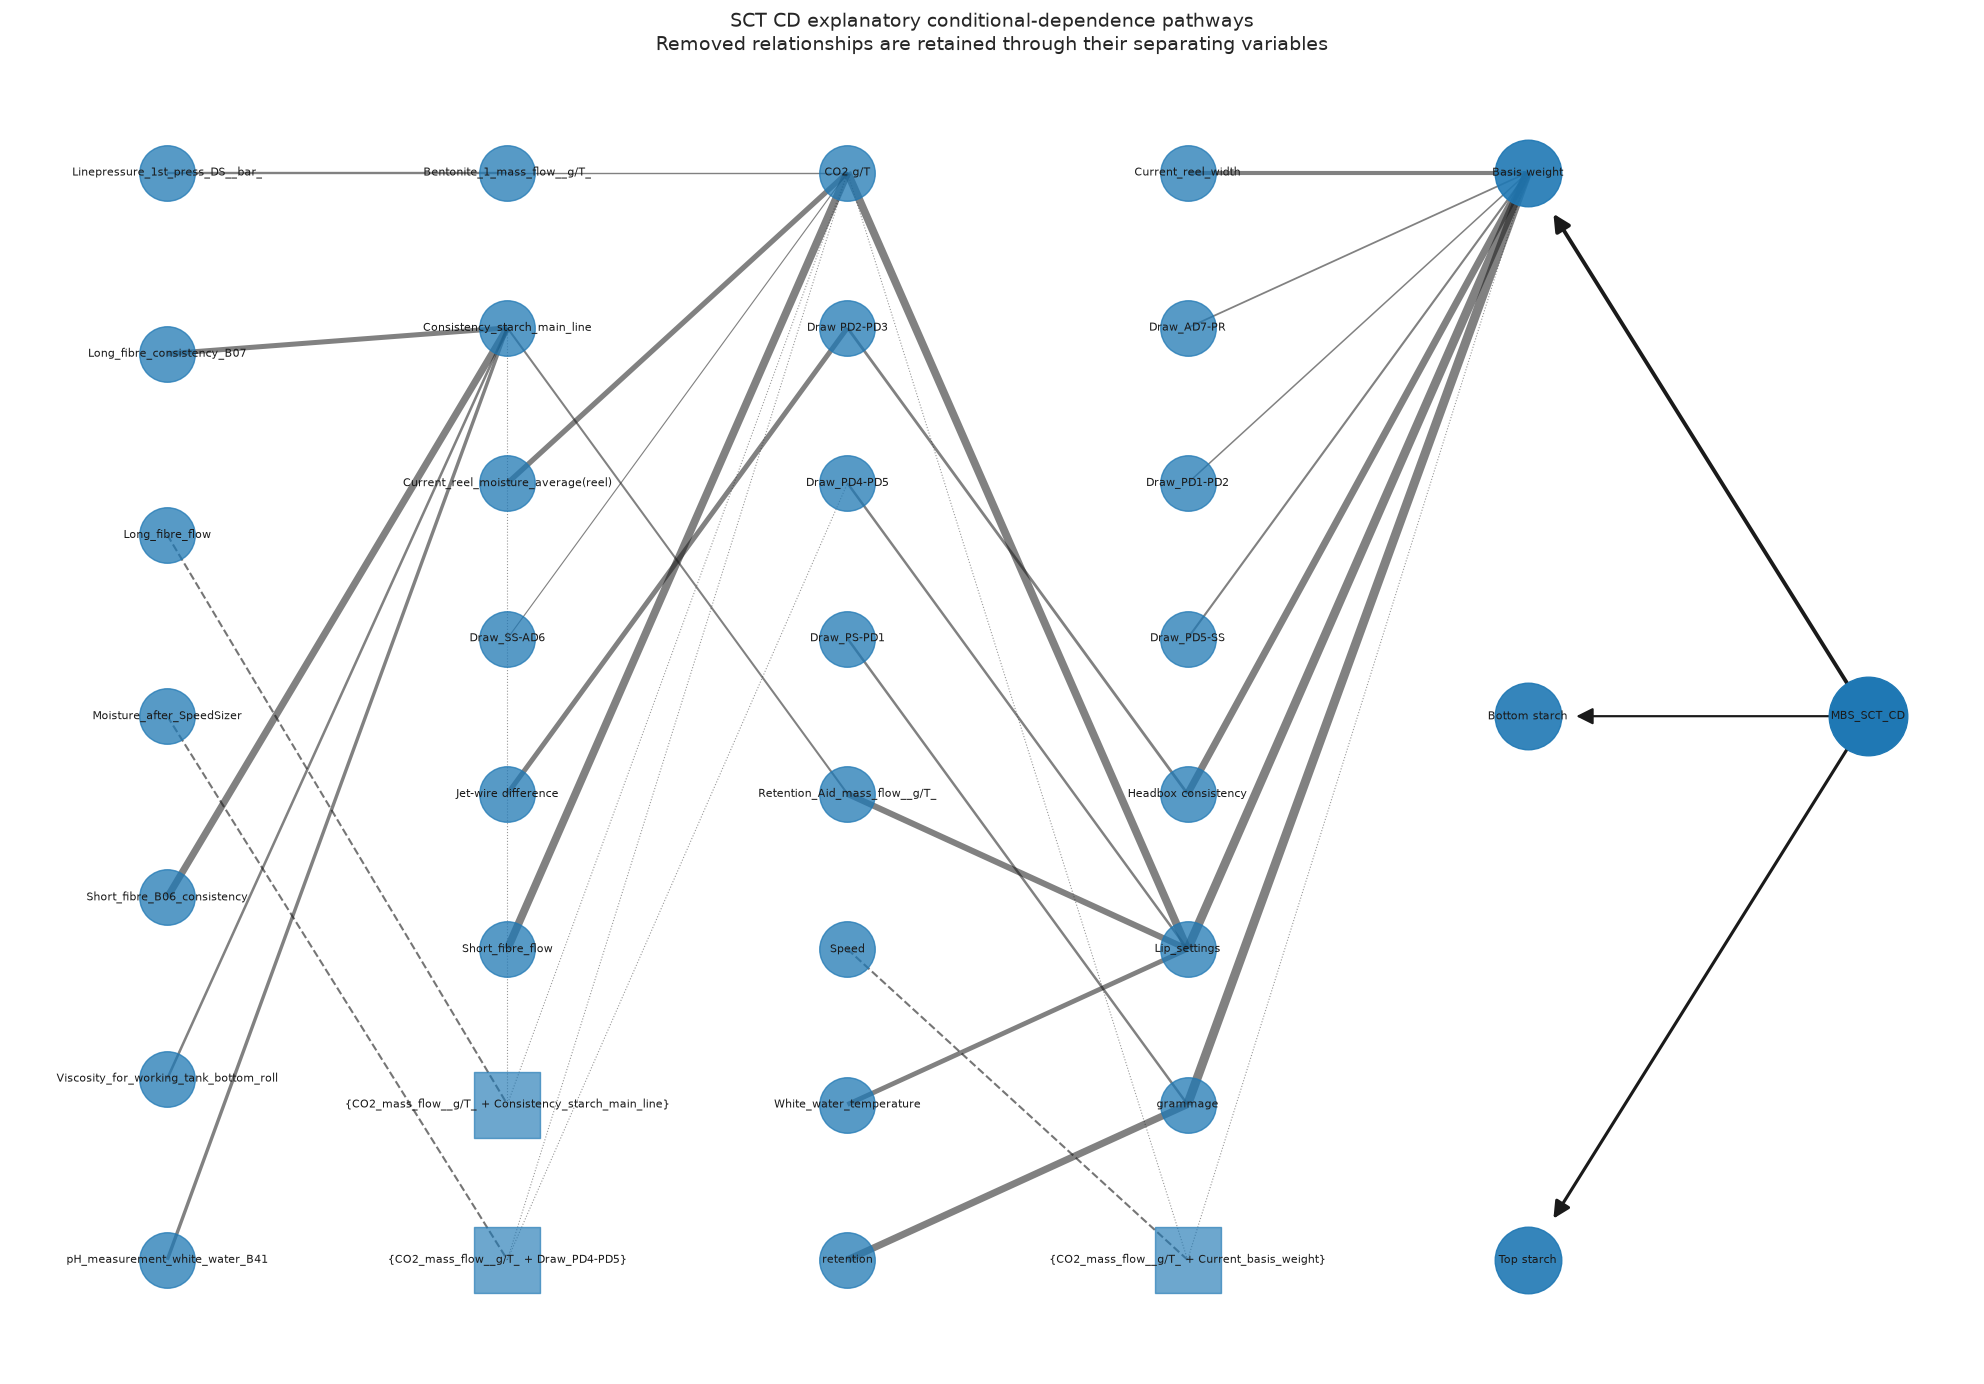

In [103]:
fig, ax, G_pathways = plot_sct_pathway_graph(
    results_ewm,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
    max_depth=4,
)

plt.show()

In [18]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


# ============================================================
# Build validated SCT motifs
# ============================================================

def build_validated_sct_motifs(
    results,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
):
    """
    Build individually validated three-variable motifs around SCT.

    A motif X - Z - SCT is retained when:

        |r(X,SCT)|       >= threshold
        |r(X,Z)|         >= threshold
        |r(Z,SCT)|       >= threshold
        |r(X,SCT | Z)|   <  threshold
        |r(Z,SCT | X)|   >= threshold

    This corresponds to a clean local pattern in which Z blocks
    the X-SCT association.

    IMPORTANT
    ---------
    This does NOT establish causal direction.

    Direct SCT neighbours from the final skeleton are also returned
    separately.
    """

    analyser = results["analyser"]

    direct_sct = set(
        results["output_neighbours"]
    )

    rows = []

    for x_name in analyser.var_names:

        if x_name == output_var:
            continue

        # Already a robust direct neighbour.
        if x_name in direct_sct:
            continue

        sep = analyser.separating_record(
            x_name,
            output_var,
        )

        if sep.empty:
            continue

        row_sep = sep.iloc[0]

        cond_set = tuple(
            row_sep["conditioning_set"]
        )

        # We only want simple one-variable motifs.
        if len(cond_set) != 1:
            continue

        z_name = cond_set[0]

        # ----------------------------------------------
        # Run the five relevant tests
        # ----------------------------------------------

        XY = analyser.parcorr_test(
            x_name,
            output_var,
        )

        XZ = analyser.parcorr_test(
            x_name,
            z_name,
        )

        ZY = analyser.parcorr_test(
            z_name,
            output_var,
        )

        XY_Z = analyser.parcorr_test(
            x_name,
            output_var,
            [z_name],
        )

        ZY_X = analyser.parcorr_test(
            z_name,
            output_var,
            [x_name],
        )

        # ----------------------------------------------
        # Validation rule
        # ----------------------------------------------

        valid = (
            abs(XY["val"]) >= min_abs_val
            and abs(XZ["val"]) >= min_abs_val
            and abs(ZY["val"]) >= min_abs_val
            and abs(XY_Z["val"]) < min_abs_val
            and abs(ZY_X["val"]) >= min_abs_val
        )

        if not valid:
            continue

        attenuation = (
            1 - abs(XY_Z["val"]) / abs(XY["val"])
            if abs(XY["val"]) > 1e-12
            else np.nan
        )

        rows.append({
            "X": x_name,
            "Z": z_name,
            "Y": output_var,

            "XY_val": XY["val"],
            "XZ_val": XZ["val"],
            "ZY_val": ZY["val"],

            "XY_given_Z_val": XY_Z["val"],
            "XY_given_Z_p": XY_Z["p"],

            "ZY_given_X_val": ZY_X["val"],
            "ZY_given_X_p": ZY_X["p"],

            "attenuation_XY_by_Z": attenuation,
        })

    motifs = pd.DataFrame(rows)

    if not motifs.empty:
        motifs = motifs.sort_values(
            "attenuation_XY_by_Z",
            ascending=False,
        ).reset_index(drop=True)

    return motifs

In [105]:
motifs = build_validated_sct_motifs(
    results_ewm,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
)

print(
    motifs[
        [
            "X",
            "Z",
            "XY_val",
            "XZ_val",
            "ZY_val",
            "XY_given_Z_val",
            "ZY_given_X_val",
            "attenuation_XY_by_Z",
        ]
    ].to_string(index=False)
)

                                     X                             Z    XY_val    XZ_val    ZY_val  XY_given_Z_val  ZY_given_X_val  attenuation_XY_by_Z
                           Draw_AD7-PR          Current_basis_weight  0.126014  0.129711  0.971534       -0.000021        0.971068             0.999836
         Retention_Aid_mass_flow__g/T_                  Lip_settings -0.617162 -0.649305  0.950210       -0.000783        0.918239             0.998731
                             retention                      grammage  0.732449  0.756484  0.969601       -0.006487        0.933185             0.991144
                    Current_reel_width          Current_basis_weight  0.400684  0.411137  0.971534        0.005791        0.965995             0.985547
                              grammage          Current_basis_weight  0.969601  0.997683  0.971534        0.019773        0.251052             0.979607
                   CO2_mass_flow__g/T_                  Lip_settings -0.812994 -0.859332

In [20]:
def plot_validated_sct_motifs(
    results,
    motifs,
    output_var="MBS_SCT_CD",
    figsize=(18, 12),
):
    """
    Plot:

    X -- Z -- SCT

    for validated single-separator motifs, together with the
    robust direct SCT neighbours.

    Interpretation
    --------------
    * Solid arrows into SCT:
        robust direct conditional dependencies.

    * Grey X--Z--SCT motifs:
        local conditional-dependence patterns where Z explains
        the X-SCT association.

    * Predictor-predictor links are NOT given causal direction.
    """

    analyser = results["analyser"]
    diagnostics = results["edge_diagnostics_df"]

    direct_nodes = list(
        results["output_neighbours"]
    )

    G = nx.Graph()

    G.add_node(
        output_var,
        node_type="output",
    )

    # ========================================================
    # Direct SCT neighbours
    # ========================================================

    direct_strength = {}

    for var in direct_nodes:

        mask = (
            (
                (diagnostics["X"] == var)
                & (diagnostics["Y"] == output_var)
            )
            |
            (
                (diagnostics["Y"] == var)
                & (diagnostics["X"] == output_var)
            )
        )

        tmp = diagnostics.loc[mask]

        if len(tmp):
            strength = float(
                tmp.iloc[0]["abs_val"]
            )
        else:
            strength = np.nan

        direct_strength[var] = strength

        G.add_node(
            var,
            node_type="direct",
        )

        G.add_edge(
            var,
            output_var,
            edge_type="direct_sct",
            strength=strength,
        )

    # ========================================================
    # Validated motifs
    # ========================================================

    if not motifs.empty:

        for row in motifs.itertuples():

            x = row.X
            z = row.Z

            if x not in G:
                G.add_node(
                    x,
                    node_type="upstream",
                )

            if z not in G:
                G.add_node(
                    z,
                    node_type="separator",
                )

            # X-Z relationship
            G.add_edge(
                x,
                z,
                edge_type="motif_process",
                strength=abs(row.XZ_val),
                signed_strength=row.XZ_val,
            )

            # Z-SCT relationship inside THIS motif.
            #
            # We draw this differently from a robust direct SCT edge,
            # because it is only evidence from this local triple.
            if not G.has_edge(
                z,
                output_var,
            ):
                G.add_edge(
                    z,
                    output_var,
                    edge_type="motif_sct",
                    strength=abs(row.ZY_given_X_val),
                    signed_strength=row.ZY_given_X_val,
                )

    # ========================================================
    # Layout
    # ========================================================

    pos = {}

    # Output far right
    pos[output_var] = (3.0, 0.0)

    # Robust direct neighbours
    direct_sorted = sorted(direct_nodes)

    if direct_sorted:

        ys = np.linspace(
            1.5,
            -1.5,
            len(direct_sorted),
        )

        for node, yy in zip(
            direct_sorted,
            ys,
        ):
            pos[node] = (
                2.0,
                yy,
            )

    # Separator nodes that are not already direct SCT neighbours
    separators = sorted({
        row.Z
        for row in motifs.itertuples()
        if row.Z not in direct_nodes
    })

    if separators:

        ys = np.linspace(
            2.2,
            -2.2,
            len(separators),
        )

        for node, yy in zip(
            separators,
            ys,
        ):
            pos[node] = (
                1.15,
                yy,
            )

    # Upstream X variables
    upstream = sorted({
        row.X
        for row in motifs.itertuples()
        if row.X not in direct_nodes
        and row.X not in separators
    })

    if upstream:

        # Put each X close to its separator Z vertically.
        grouped = []

        for x in upstream:

            z_values = motifs.loc[
                motifs["X"] == x,
                "Z",
            ].tolist()

            target_y = np.mean([
                pos[z][1]
                for z in z_values
                if z in pos
            ])

            grouped.append(
                (x, target_y)
            )

        grouped.sort(
            key=lambda item: -item[1]
        )

        # Spread a little to avoid overlap
        base_y = np.linspace(
            2.7,
            -2.7,
            len(grouped),
        )

        for (
            (node, target_y),
            spread_y,
        ) in zip(
            grouped,
            base_y,
        ):

            yy = (
                0.65 * target_y
                + 0.35 * spread_y
            )

            pos[node] = (
                0.0,
                yy,
            )

    # Some nodes may be both separator and upstream.
    # Give them a fallback position if needed.
    for node in G.nodes():

        if node not in pos:

            pos[node] = (
                1.0,
                0.0,
            )

    # ========================================================
    # Plot
    # ========================================================

    fig, ax = plt.subplots(
        figsize=figsize
    )

    node_type = nx.get_node_attributes(
        G,
        "node_type",
    )

    # Upstream
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G.nodes
            if node_type.get(n)
            == "upstream"
        ],
        node_size=1400,
        alpha=0.7,
        ax=ax,
    )

    # Separators
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G.nodes
            if node_type.get(n)
            == "separator"
        ],
        node_size=1800,
        alpha=0.8,
        ax=ax,
    )

    # Direct neighbours
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[
            n for n in G.nodes
            if node_type.get(n)
            == "direct"
        ],
        node_size=2400,
        alpha=0.9,
        ax=ax,
    )

    # Output
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[output_var],
        node_size=3200,
        ax=ax,
    )

    # ========================================================
    # Motif X-Z edges
    # ========================================================

    motif_process_edges = [
        (u, v)
        for u, v, d
        in G.edges(data=True)
        if d["edge_type"]
        == "motif_process"
    ]

    widths = [
        0.5
        + 5 * G[u][v]["strength"]
        for u, v in motif_process_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=motif_process_edges,
        width=widths,
        alpha=0.45,
        arrows=False,
        ax=ax,
    )

    # ========================================================
    # Motif Z-SCT edges
    #
    # Dashed because they are local triple evidence, not robust
    # direct SCT neighbours.
    # ========================================================

    motif_sct_edges = [
        (u, v)
        for u, v, d
        in G.edges(data=True)
        if d["edge_type"]
        == "motif_sct"
    ]

    widths = [
        0.5
        + 5 * G[u][v]["strength"]
        for u, v in motif_sct_edges
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=motif_sct_edges,
        width=widths,
        style="dashed",
        alpha=0.45,
        arrows=False,
        ax=ax,
    )

    # ========================================================
    # Robust direct SCT edges
    # ========================================================

    direct_edges = []

    for node in direct_nodes:
        direct_edges.append(
            (node, output_var)
        )

    widths = [
        1.0
        + 8 * direct_strength[node]
        for node in direct_nodes
    ]

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=direct_edges,
        width=widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=26,
        min_source_margin=25,
        min_target_margin=35,
        ax=ax,
    )

    # ========================================================
    # Cleaner display names
    # ========================================================

    display_names = {
        "MBS_SCT_CD":
            "SCT CD",

        "Current_basis_weight":
            "Basis weight",

        "Starch_uptake_by_paper_Top_Roll__g/m2_":
            "Top starch",

        "Starch_uptake_by_paper_Bottom_Roll__g/m2_":
            "Bottom starch",

        "Jet/wire_ratio":
            "Jet-wire difference",

        "Draw_PD2-PD3":
            "Draw PD2-PD3",

        "Headbox_consistency":
            "Headbox consistency",

        "Lip_settings":
            "Lip settings",

        "CO2_mass_flow__g/T_":
            "CO2 g/T",
    }

    labels = {
        node: display_names.get(
            node,
            node,
        )
        for node in G.nodes
    }

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=8,
        ax=ax,
    )

    # ========================================================
    # Column labels
    # ========================================================

    ax.text(
        0.0,
        3.05,
        "Associated process variables",
        ha="center",
        fontsize=11,
    )

    ax.text(
        1.15,
        3.05,
        "Separating variables",
        ha="center",
        fontsize=11,
    )

    ax.text(
        2.0,
        3.05,
        "Robust SCT neighbours",
        ha="center",
        fontsize=11,
    )

    ax.text(
        3.0,
        3.05,
        "Output",
        ha="center",
        fontsize=11,
    )

    ax.set_title(
        "Validated conditional-dependence motifs around SCT CD\n"
        "Solid arrows = robust SCT neighbours; "
        "grey motifs = locally validated blocking structures",
        fontsize=14,
    )

    ax.axis("off")

    plt.tight_layout()

    return fig, ax, G

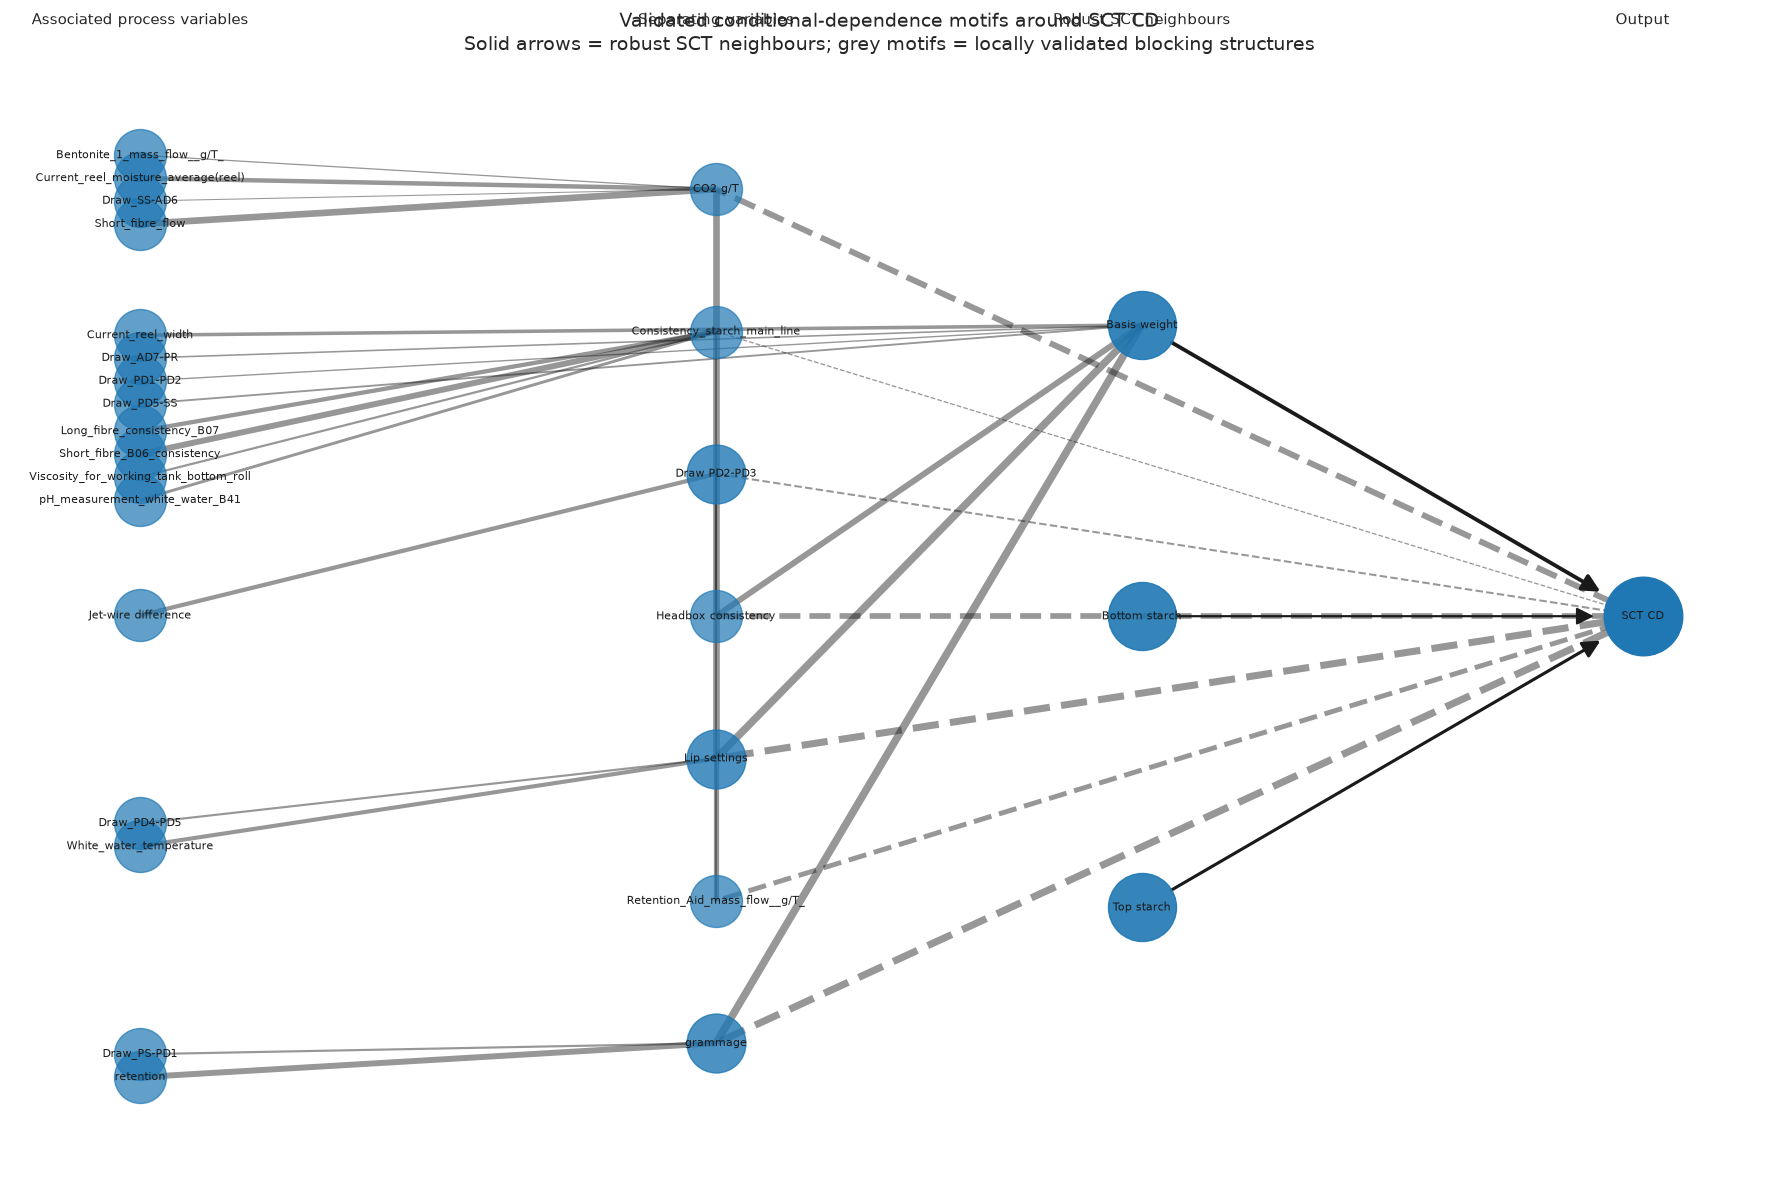

In [107]:
motifs = build_validated_sct_motifs(
    results_ewm,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
)

fig, ax, G_motifs = plot_validated_sct_motifs(
    results_ewm,
    motifs,
    output_var="MBS_SCT_CD",
)

plt.show()

In [108]:
print(
    motifs[
        [
            "X",
            "Z",
            "XY_val",
            "XZ_val",
            "ZY_val",
            "XY_given_Z_val",
            "ZY_given_X_val",
            "attenuation_XY_by_Z",
        ]
    ].to_string(index=False)
)

                                     X                             Z    XY_val    XZ_val    ZY_val  XY_given_Z_val  ZY_given_X_val  attenuation_XY_by_Z
                           Draw_AD7-PR          Current_basis_weight  0.126014  0.129711  0.971534       -0.000021        0.971068             0.999836
         Retention_Aid_mass_flow__g/T_                  Lip_settings -0.617162 -0.649305  0.950210       -0.000783        0.918239             0.998731
                             retention                      grammage  0.732449  0.756484  0.969601       -0.006487        0.933185             0.991144
                    Current_reel_width          Current_basis_weight  0.400684  0.411137  0.971534        0.005791        0.965995             0.985547
                              grammage          Current_basis_weight  0.969601  0.997683  0.971534        0.019773        0.251052             0.979607
                   CO2_mass_flow__g/T_                  Lip_settings -0.812994 -0.859332

# By grade

In [158]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


def plot_sct_structure(
    results,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
    aliases=None,
    figsize=(20, 11),
):
    """
    Plot SCT-centred conditional-dependence structure.

    Meaning
    -------
    Solid black -> SCT:
        Robust SCT neighbour. No tested conditioning set up to max_cond_dim
        reduced |partial correlation| below min_abs_val.

    Grey X -- Z:
        X-SCT relationship is removed by conditioning on single variable Z.

    Grey X -- [conditioning set]:
        X-SCT relationship is removed only by a multi-variable conditioning set.

    Dashed grey -> SCT:
        Indicates that the X-SCT relationship does not survive the displayed
        conditioning variable/set.
    """

    analyser = results["analyser"]
    robust = set(results["output_neighbours"])

    if aliases is None:
        aliases = {}

    def label(v):
        return aliases.get(v, v)

    # ---------------------------------------------------------
    # Collect SCT-associated variables that were removed
    # ---------------------------------------------------------
    single_sep = []
    multi_sep = []

    for x in analyser.var_names:

        if x == output_var or x in robust:
            continue

        # Must have a relevant marginal SCT relationship
        marginal = analyser.parcorr_test(x, output_var)

        if abs(marginal["val"]) < min_abs_val:
            continue

        sep = analyser.separating_record(x, output_var)

        if sep is None or sep.empty:
            continue

        # If several separating records exist, use the one giving
        # the smallest residual absolute partial correlation
        if "abs_val" in sep.columns:
            row = sep.sort_values("abs_val").iloc[0]
        else:
            row = sep.iloc[0]

        S = tuple(row["conditioning_set"])

        if len(S) == 0:
            continue

        record = {
            "x": x,
            "S": S,
            "marginal": marginal["val"],
            "conditional": row["val"],
        }

        if len(S) == 1:
            single_sep.append(record)
        else:
            multi_sep.append(record)

    # ---------------------------------------------------------
    # Graph
    # ---------------------------------------------------------
    G = nx.DiGraph()

    G.add_node(output_var, kind="output")

    for x in robust:
        G.add_node(x, kind="robust")

    # Single-variable motifs
    for rec in single_sep:
        x = rec["x"]
        z = rec["S"][0]

        G.add_node(x, kind="associated")

        if z not in G:
            kind = "robust" if z in robust else "separator"
            G.add_node(z, kind=kind)

    # Multi-variable motifs:
    # use explicit conditioning-set boxes rather than pretending
    # that the conditioning set is a process variable.
    for i, rec in enumerate(multi_sep):
        x = rec["x"]
        S = rec["S"]

        G.add_node(x, kind="associated")

        set_node = f"__SET_{i}__"

        G.add_node(
            set_node,
            kind="conditioning_set",
            members=S,
        )

        rec["set_node"] = set_node

    # ---------------------------------------------------------
    # Manual column layout
    # ---------------------------------------------------------

    pos = {}

    # Four columns
    x_assoc = 0.0
    x_sep = 1.8
    x_robust = 3.7
    x_output = 5.5

    # Associated variables
    associated_nodes = sorted({
        rec["x"] for rec in single_sep + multi_sep
    })

    ys = np.linspace(
        1,
        max(len(associated_nodes), 1),
        max(len(associated_nodes), 1),
    )

    for node, y in zip(associated_nodes, ys[::-1]):
        pos[node] = (x_assoc, y)

    # Separator nodes from single-variable motifs
    separator_nodes = sorted({
        rec["S"][0]
        for rec in single_sep
        if rec["S"][0] not in robust
    })

    conditioning_set_nodes = [
        rec["set_node"] for rec in multi_sep
    ]

    middle_nodes = separator_nodes + conditioning_set_nodes

    ys_middle = np.linspace(
        1,
        max(len(middle_nodes), 1),
        max(len(middle_nodes), 1),
    )

    for node, y in zip(middle_nodes, ys_middle[::-1]):
        pos[node] = (x_sep, y)

    # Robust neighbours
    robust_nodes = sorted(robust)

    ys_robust = np.linspace(
        1,
        max(len(robust_nodes), 1),
        max(len(robust_nodes), 1),
    )

    for node, y in zip(robust_nodes, ys_robust[::-1]):
        pos[node] = (x_robust, y)

    # Output centred vertically
    max_y = max(
        len(associated_nodes),
        len(middle_nodes),
        len(robust_nodes),
        1,
    )

    pos[output_var] = (x_output, (max_y + 1) / 2)

    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    # ---------- associated process nodes ----------
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=associated_nodes,
        node_size=1500,
        ax=ax,
    )

    # ---------- separator variables ----------
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=separator_nodes,
        node_size=1700,
        ax=ax,
    )

    # ---------- robust neighbours ----------
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=robust_nodes,
        node_size=1900,
        ax=ax,
    )

    # ---------- output ----------
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[output_var],
        node_size=2200,
        ax=ax,
    )

    # ---------- multi-variable conditioning-set boxes ----------
    for node in conditioning_set_nodes:

        members = G.nodes[node]["members"]

        text = "Condition on:\n" + "\n".join(
            label(v) for v in members
        )

        x, y = pos[node]

        ax.text(
            x,
            y,
            text,
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.45",
                facecolor="white",
                edgecolor="0.55",
                linewidth=1.3,
            ),
        )

    # ---------------------------------------------------------
    # Robust SCT edges
    # ---------------------------------------------------------
    for x in robust_nodes:

        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=[(x, output_var)],
            edge_color="black",
            width=1.8,
            arrows=True,
            arrowsize=20,
            ax=ax,
        )

    # ---------------------------------------------------------
    # Single-separator motifs
    #
    # X -- Z       association/blocking structure
    # X ---> SCT   dashed = X-SCT does not survive conditioning
    # ---------------------------------------------------------
    for rec in single_sep:

        x = rec["x"]
        z = rec["S"][0]

        # X -- Z
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=[(x, z)],
            edge_color="0.6",
            width=1.5,
            arrows=False,
            ax=ax,
        )

        # X --dashed--> SCT
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=[(x, output_var)],
            edge_color="0.65",
            width=1.2,
            style="dashed",
            arrows=True,
            arrowsize=15,
            ax=ax,
        )

    # ---------------------------------------------------------
    # Multi-variable separator motifs
    #
    # X -- [S]
    # X ---> SCT dashed
    # ---------------------------------------------------------
    for rec in multi_sep:

        x = rec["x"]
        set_node = rec["set_node"]

        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=[(x, set_node)],
            edge_color="0.6",
            width=1.5,
            arrows=False,
            ax=ax,
        )

        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=[(x, output_var)],
            edge_color="0.65",
            width=1.2,
            style="dashed",
            arrows=True,
            arrowsize=15,
            ax=ax,
        )

    # ---------------------------------------------------------
    # Labels
    # ---------------------------------------------------------
    normal_nodes = (
        associated_nodes
        + separator_nodes
        + robust_nodes
        + [output_var]
    )

    labels = {
        node: label(node)
        for node in normal_nodes
    }

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=8,
        ax=ax,
    )

    # ---------------------------------------------------------
    # Column headings
    # ---------------------------------------------------------
    heading_y = max_y + 1.3

    ax.text(
        x_assoc,
        heading_y,
        "SCT-associated variables\nremoved by conditioning",
        ha="center",
        fontsize=11,
    )

    ax.text(
        x_sep,
        heading_y,
        "Separating variable / set",
        ha="center",
        fontsize=11,
    )

    ax.text(
        x_robust,
        heading_y,
        "Robust SCT neighbours",
        ha="center",
        fontsize=11,
    )

    ax.text(
        x_output,
        heading_y,
        "Output",
        ha="center",
        fontsize=11,
    )

    ax.set_title(
        "Conditional-dependence structure around SCT CD\n"
        "Solid = survives conditioning; dashed = removed by conditioning",
        fontsize=13,
    )

    ax.axis("off")
    plt.tight_layout()

    return fig, ax

In [127]:
ctl_vars

['retention',
 'grammage',
 'delta_basis_weight',
 'Speed',
 'Moisture_after_SpeedSizer',
 'Current_reel_moisture_average(reel)',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Viscosity_for_working_tank_bottom_roll',
 'Starch_uptake__g/m2_',
 'Consistency_starch_main_line',
 'Draw_PD5-SS',
 'Draw_AD7-PR',
 'Draw_AD6-AD7',
 'Draw_PD4-PD5',
 'Draw_WS-PS',
 'Draw_PD1-PD2',
 'Draw_PD3-PD4',
 'Draw_SS-AD6',
 'Draw_PS-PD1',
 'Draw_PD2-PD3',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_shoe_press__bar_',
 'pH_measurement_white_water_B41',
 'Headbox_consistency',
 'Lip_settings',
 'Jet/wire_ratio',
 'Retention_Aid_mass_flow__g/T_',
 'Bentonite_1_mass_flow__g/T_',
 'Bentonite_2_mass_flow__g/T_',
 'CO2_mass_flow__g/T_',
 'fibre_short/long',
 'White_water_temperature',
 'Conductivity_white_water_B46',
 'Current_reel_width']

In [130]:
import pandas as pd
import tigramite.data_processing as pp


# ============================================================
# 1. Load raw data
# ============================================================

turnup_data = pd.read_parquet(DATA_PATH)


# ============================================================
# 2. Build variable list
# ============================================================

ctl_vars = unique_in_order(
    v for v in CONTROL_VARS[Y_COLUMN]
    if "vacuum" not in v.lower()
)

created_vars = ordered_intersection(
    CREATED_VARIABLE_CANDIDATES,
    ctl_vars,
)


# ============================================================
# 3. Feature engineering
# ============================================================

turnup_data = _feature_engineering(
    turnup_data,
    setpoint_df,
    steam_null=False,
    clip=True,
)

turnup_data = (
    turnup_data
    .set_index("Wedge_Time")
    .sort_index()
)


if len(created_vars) > 0:

    fc = FeatureCreator(
        features_to_create=created_vars,
        features_to_keep=list(
            set(
                turnup_data.columns.to_list()
                + created_vars
            )
        ),
    )

    turnup_data = fc.fit_transform(turnup_data)

    fr = fc.features_required()

else:
    fr = []


#var_names = (
#    [Y_COLUMN] 
#    + unique_in_order(
#        ordered_difference(
#            ctl_vars,
#            created_vars,
#        )
#        + fr
#    )
#)

var_names = [Y_COLUMN]  + ctl_vars


# ============================================================
# 4. Create delta basis weight
# ============================================================
#
# This is created from the ORIGINAL, non-EWM-filtered values.
#
# Ideally:
#
#   actual basis weight - target basis weight
#
# Here grammage is assumed to represent the intended/nominal
# basis weight.
# ============================================================

turnup_data["delta_basis_weight"] = (
    turnup_data["Current_basis_weight"]
    - turnup_data["grammage"]
)



# ============================================================
# 5. Define variables for the within-grade analysis
# ============================================================
#
# Remove absolute basis weight and grammage.
# Replace them with delta_basis_weight.
# ============================================================

within_product_vars = [
    v
    for v in var_names
    if v not in {
        "Current_basis_weight",
        "grammage",
        "retention"
    }
]


within_product_vars = unique_in_order(
    within_product_vars
)


# ============================================================
# 6. Within-grade transformation
# ============================================================
#
# IMPORTANT:
# This is done BEFORE EWM filtering.
#
# For each variable:
#
#   X_within = X - mean(X | grade)
#
# Therefore all variables become deviations from their
# grade-specific mean.
#
# Example:
#
#   SCT_within =
#       SCT - average SCT for that grade
#
# ============================================================

GRADE_VAR = "AB_Grade_ID"

turnup_within = turnup_data.copy()


grade_means = (
    turnup_data
    .groupby(GRADE_VAR)[within_product_vars]
    .transform("mean")
)


turnup_within[within_product_vars] = (
    turnup_data[within_product_vars]
    - grade_means
)


# ============================================================
# 7. Optional sanity checks
# ============================================================

print(
    turnup_within
    .groupby(GRADE_VAR)[within_product_vars]
    .mean()
    .round(6)
)

             MBS_SCT_CD  delta_basis_weight     Speed  \
AB_Grade_ID                                             
3200115            -0.0                 0.0  0.000066   
3300085             0.0                -0.0  0.000076   
3300100            -0.0                 0.0 -0.000023   
3300110             0.0                 0.0  0.000001   
3300120            -0.0                 0.0  0.000036   
6010085             0.0                 0.0 -0.000037   
6010090             0.0                -0.0 -0.000027   
6010100             0.0                -0.0  0.000095   
6010110             0.0                -0.0 -0.000009   
6010120            -0.0                -0.0 -0.000017   

             Moisture_after_SpeedSizer  Current_reel_moisture_average(reel)  \
AB_Grade_ID                                                                   
3200115                      -0.000002                             0.000000   
3300085                       0.000000                            -0.000000   

In [168]:
# ============================================================
# 8. EWM filtering of the WITHIN-GRADE deviations
# ============================================================

filtered_within = ewm_filter_by_segment(
    turnup_within,
    columns=within_product_vars,
    halflife="120min",
)

# ============================================================
# 9. Create Tigramite dataframe
# ============================================================

analysis_df = (
    filtered_within[within_product_vars]
    .dropna()
)


data_array = analysis_df.values


dataframe_within = pp.DataFrame(
    data_array,
    var_names=within_product_vars,
)

# ============================================================
# 10. Conditional-dependence skeleton
# ============================================================

results_within = run_dependence_analysis(
    dataframe=dataframe_within,
    output_var=Y_COLUMN,
    max_cond_dim=3,
    min_abs_val=0.05,
)


Searching conditioning sets of size 0...
Tested 666 CI relations
Removed 325 edges; 341 remain

Searching conditioning sets of size 1...
Tested 5,599 CI relations
Removed 191 edges; 150 remain

Searching conditioning sets of size 2...
Tested 13,908 CI relations
Removed 57 edges; 93 remain

Searching conditioning sets of size 3...
Tested 40,473 CI relations
Removed 18 edges; 75 remain

FINAL RESULT
Nodes: 37
Edges: 75

Remaining direct neighbours of MBS_SCT_CD:
  - Jet/wire_ratio
  - Starch_uptake__g/m2_
  - White_water_temperature
  - delta_basis_weight

Results written to: /home/susarro/workspace/costimiser/TFP/src/conditional_dependence_results


In [169]:
print(
    results_within["output_neighbours"]
)

['Jet/wire_ratio', 'Starch_uptake__g/m2_', 'White_water_temperature', 'delta_basis_weight']


In [152]:
a = results_within["analyser"]


# ============================================================
# delta basis weight
# ============================================================

print(
    "\ndelta BW - SCT"
)

print(
    a.parcorr_test(
        "delta_basis_weight",
        Y_COLUMN,
    )
)

print(
    a.separating_record(
        "delta_basis_weight",
        Y_COLUMN,
    )
)


# ============================================================
# Jet-wire difference
# ============================================================

print(
    "\nJet-wire - SCT"
)

print(
    a.parcorr_test(
        "Jet/wire_ratio",
        Y_COLUMN,
    )
)

print(
    a.separating_record(
        "Jet/wire_ratio",
        Y_COLUMN,
    )
)


delta BW - SCT
{'val': 0.23552441922540904, 'p': 1.0571071731103894e-110}
Empty DataFrame
Columns: [X, Y, conditioning_set, cond_dim, val, abs_val, p, status]
Index: []

Jet-wire - SCT
{'val': 0.10761685086919438, 'p': 5.507822187825824e-24}
Empty DataFrame
Columns: [X, Y, conditioning_set, cond_dim, val, abs_val, p, status]
Index: []


In [153]:
from itertools import combinations
import pandas as pd


def best_conditioning_set(
    analyser,
    x,
    y,
    max_cond_dim=3,
):
    """
    Find the conditioning set S, up to max_cond_dim,
    that minimizes |r(X,Y | S)|.
    """

    candidates = [
        v for v in analyser.var_names
        if v not in {x, y}
    ]

    rows = []

    # Marginal relationship
    result = analyser.parcorr_test(x, y)

    rows.append({
        "conditioning_set": (),
        "cond_dim": 0,
        "val": result["val"],
        "abs_val": abs(result["val"]),
        "p": result["p"],
    })

    # Conditional relationships
    for k in range(1, max_cond_dim + 1):

        for S in combinations(candidates, k):

            result = analyser.parcorr_test(
                x,
                y,
                list(S),
            )

            rows.append({
                "conditioning_set": S,
                "cond_dim": k,
                "val": result["val"],
                "abs_val": abs(result["val"]),
                "p": result["p"],
            })

    df = pd.DataFrame(rows)

    return (
        df
        .sort_values("abs_val")
        .reset_index(drop=True)
    )

In [154]:
a = results_within["analyser"]

for x in results_within["output_neighbours"]:

    df_best = best_conditioning_set(
        analyser=a,
        x=x,
        y=Y_COLUMN,
        max_cond_dim=3,
    )

    marginal = df_best.loc[
        df_best["cond_dim"] == 0
    ].iloc[0]

    best = df_best.iloc[0]

    print("\n" + "=" * 80)
    print(x)

    print(
        f"Marginal: "
        f"r={marginal['val']:+.4f}, "
        f"p={marginal['p']:.3g}"
    )

    print(
        f"Best conditioning set: "
        f"{best['conditioning_set']}"
    )

    print(
        f"Conditional: "
        f"r={best['val']:+.4f}, "
        f"p={best['p']:.3g}"
    )

    attenuation = (
        1
        - best["abs_val"]
        / marginal["abs_val"]
    )

    print(
        f"Attenuation: "
        f"{100 * attenuation:.1f}%"
    )


Jet/wire_ratio
Marginal: r=+0.1076, p=5.51e-24
Best conditioning set: ('Linepressure_2nd_press_FS__bar_', 'Linepressure_2nd_press_DS__bar_', 'White_water_temperature')
Conditional: r=+0.0906, p=1.91e-17
Attenuation: 15.8%

Moisture_after_SpeedSizer
Marginal: r=+0.2073, p=1.12e-85
Best conditioning set: ('Viscosity_for_working_tank_bottom_roll', 'Starch_uptake__g/m2_', 'White_water_temperature')
Conditional: r=+0.0452, p=2.31e-05
Attenuation: 78.2%

Starch_uptake__g/m2_
Marginal: r=+0.2166, p=1.58e-93
Best conditioning set: ('Moisture_after_SpeedSizer', 'Headbox_consistency', 'Bentonite_2_mass_flow__g/T_')
Conditional: r=+0.0919, p=6.95e-18
Attenuation: 57.6%

White_water_temperature
Marginal: r=-0.1648, p=2.08e-54
Best conditioning set: ('Speed', 'Linepressure_2nd_press_DS__bar_', 'Retention_Aid_mass_flow__g/T_')
Conditional: r=-0.0764, p=8.28e-13
Attenuation: 53.7%

delta_basis_weight
Marginal: r=+0.2355, p=1.06e-110
Best conditioning set: ('Speed', 'Retention_Aid_mass_flow__g/T_', '

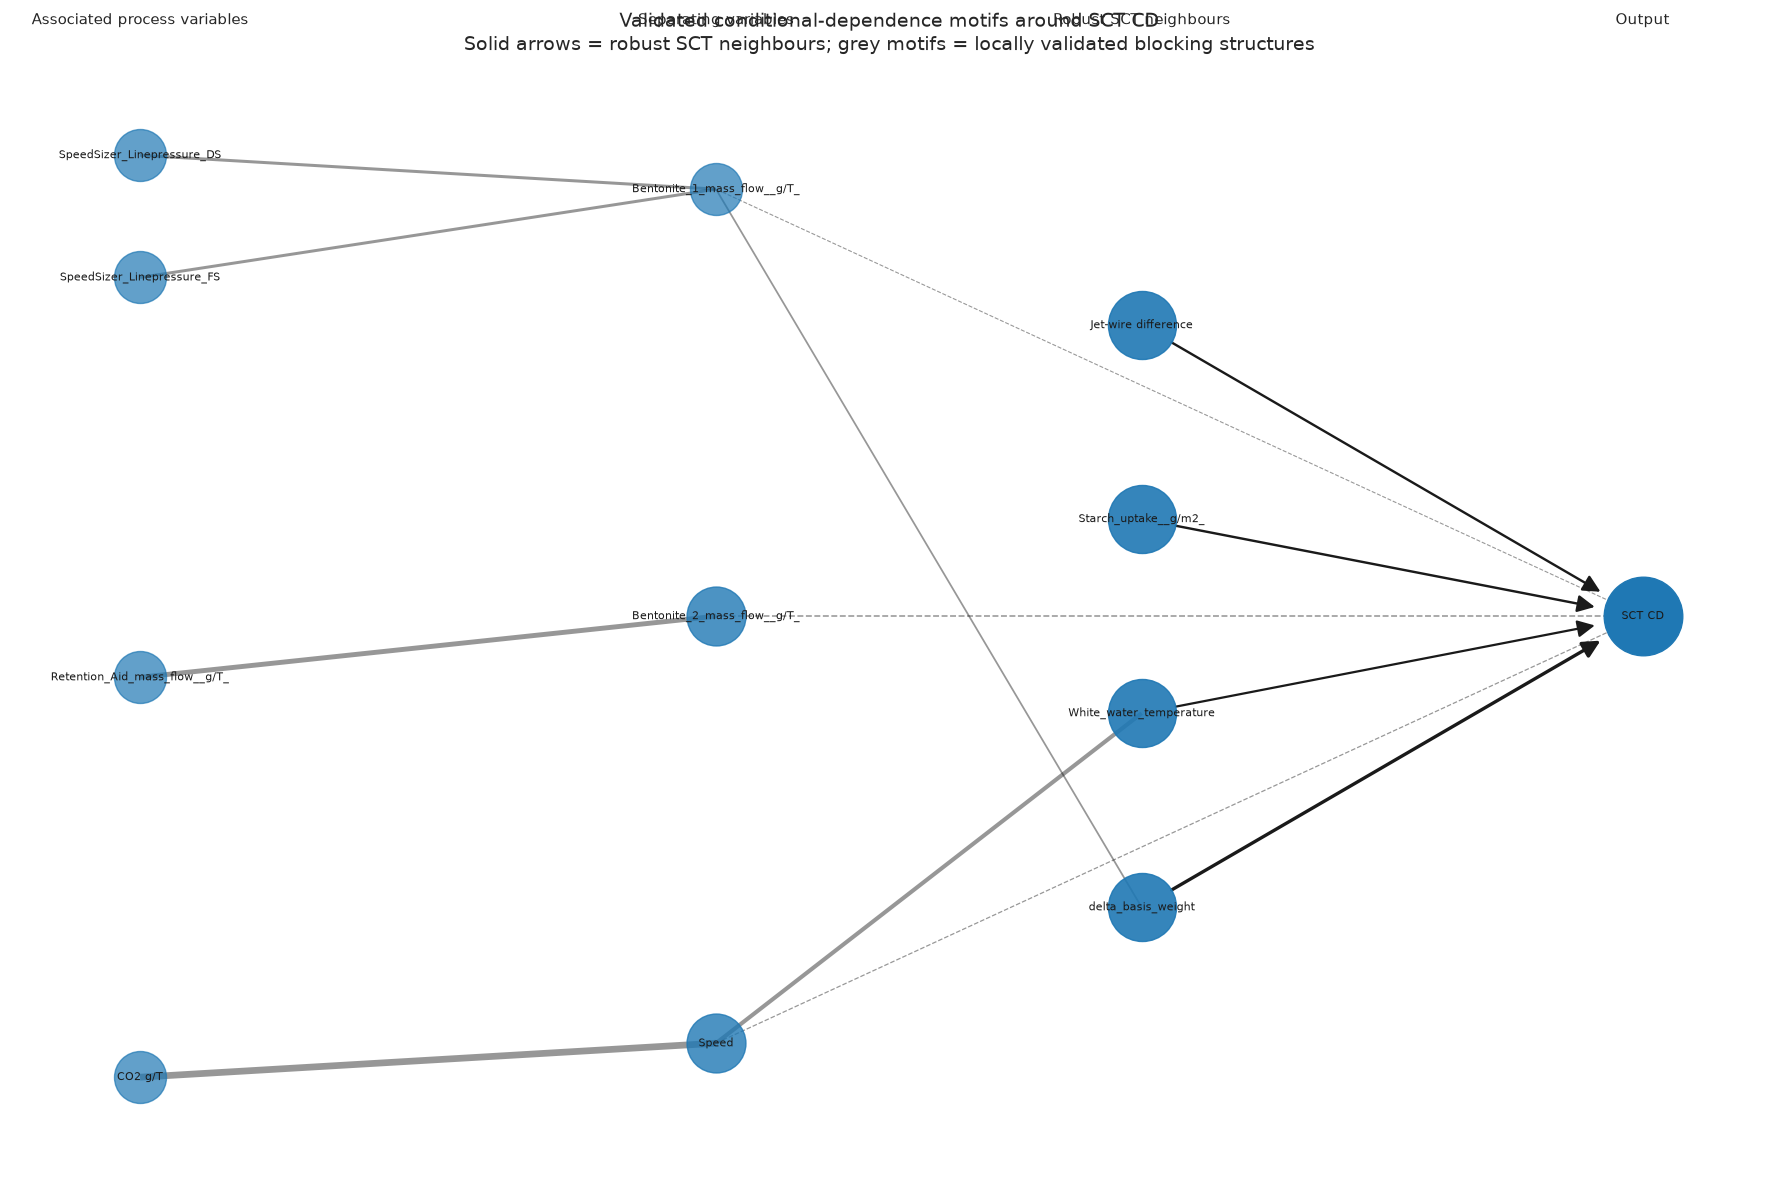

In [170]:
motifs = build_validated_sct_motifs(
    results_within,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
)

fig, ax, G_motifs = plot_validated_sct_motifs(
    results_within,
    motifs,
    output_var="MBS_SCT_CD",
)

plt.show()

In [139]:
print(
    a.parcorr_test(
        "Bentonite_1_mass_flow__g/T_",
        Y_COLUMN,
    )
)

print(
    a.parcorr_test(
        "Bentonite_1_mass_flow__g/T_",
        "delta_basis_weight",
    )
)

print(
    a.parcorr_test(
        "Bentonite_1_mass_flow__g/T_",
        Y_COLUMN,
        ["delta_basis_weight"],
    )
)

print(
    a.parcorr_test(
        "delta_basis_weight",
        Y_COLUMN,
        ["Bentonite_1_mass_flow__g/T_"],
    )
)

{'val': -0.0720607836679888, 'p': 1.4548293010386488e-11}
{'val': -0.15460770792124182, 'p': 5.347916465304017e-48}
{'val': -0.03712511773507578, 'p': 0.0005104262558419756}
{'val': 0.22770608098223882, 'p': 2.1306647400421657e-103}


In [147]:
sep = a.separating_record(
    "Bentonite_2_mass_flow__g/T_",
    Y_COLUMN,
)

print(sep.iloc[0]["conditioning_set"])

('Bentonite_1_mass_flow__g/T_', 'Conductivity_white_water_B46', 'Retention_Aid_mass_flow__g/T_')


In [148]:
sep = a.separating_record(
    "Bentonite_1_mass_flow__g/T_",
    Y_COLUMN,
)

print(sep.iloc[0]["conditioning_set"])

('delta_basis_weight',)


In [156]:
sep = a.separating_record(
    "Viscosity_for_working_tank_bottom_roll",
    Y_COLUMN,
)

print(sep.iloc[0]["conditioning_set"])

('Starch_uptake__g/m2_', 'delta_basis_weight')


In [157]:
print(results_within["output_neighbours"])

['Jet/wire_ratio', 'Moisture_after_SpeedSizer', 'Starch_uptake__g/m2_', 'White_water_temperature', 'delta_basis_weight']


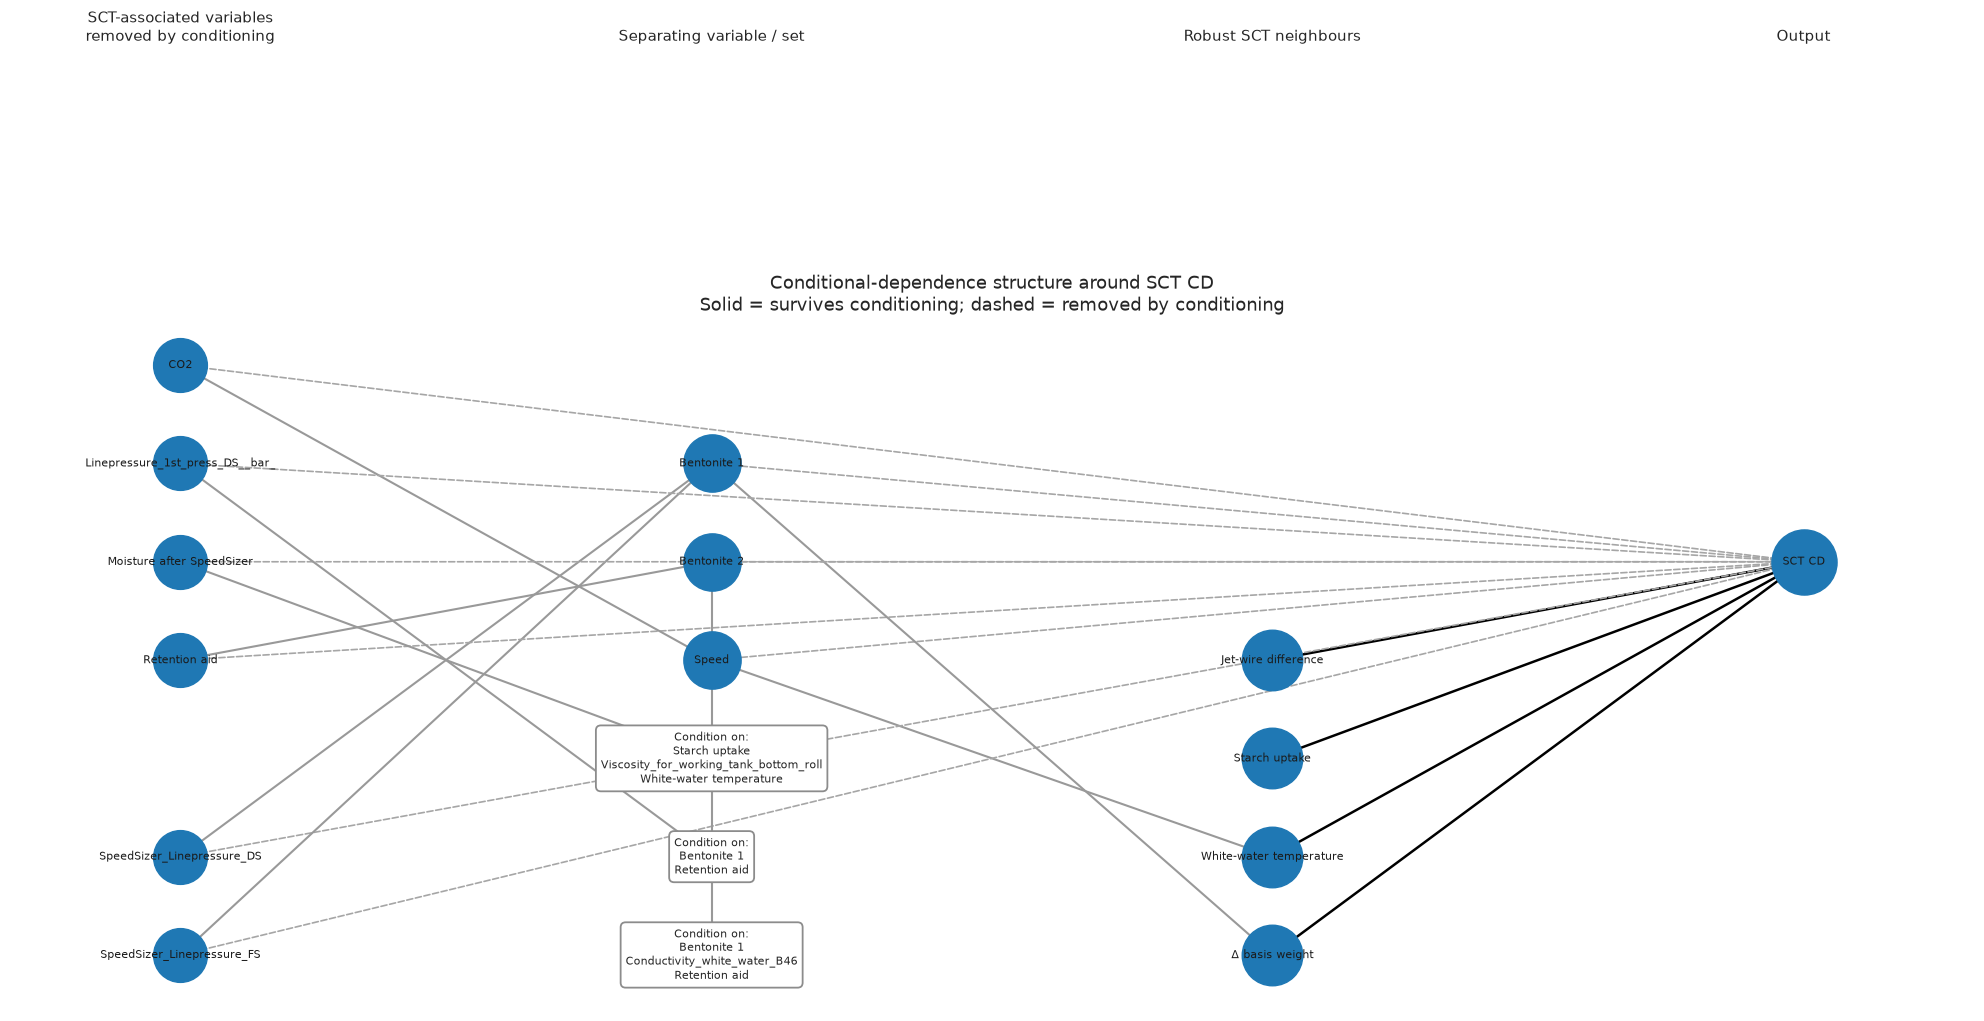

In [171]:
aliases = {
    "MBS_SCT_CD": "SCT CD",
    "Jet/wire_ratio": "Jet-wire difference",
    "Moisture_after_SpeedSizer": "Moisture after SpeedSizer",
    "Starch_uptake__g/m2_": "Starch uptake",
    "White_water_temperature": "White-water temperature",
    "delta_basis_weight": "Δ basis weight",

    "Bentonite_1_mass_flow__g/T_": "Bentonite 1",
    "Bentonite_2_mass_flow__g/T_": "Bentonite 2",
    "Retention_Aid_mass_flow__g/T_": "Retention aid",
    "CO2_mass_flow__g/T_": "CO2",
    "Speed": "Speed",
}

fig, ax = plot_sct_structure(
    results_within,
    output_var=Y_COLUMN,
    min_abs_val=0.03,   # use the same threshold as the analysis
    aliases=aliases,
)

# All features

In [4]:
OUTPUT_VAR = "MBS_SCT_CD"
MAX_COND_DIM = 3
MIN_ABS_VAL = 0.05
ALPHA = 0.05
OUTPUT_DIR = Path("conditional_dependence_results")

In [5]:
from itertools import combinations
from pathlib import Path
from typing import Iterable, Optional

import networkx as nx
import pandas as pd
from tigramite.independence_tests.parcorr import ParCorr


class ConditionalDependenceSkeleton:
    def __init__(
        self,
        dataframe,
        *,
        output_var: str = OUTPUT_VAR,
        max_cond_dim: int = MAX_COND_DIM,
        min_abs_val: float = MIN_ABS_VAL,
        alpha: float = ALPHA,
        verbosity: int = 1,
    ):
        self.dataframe = dataframe
        self.output_var = output_var
        self.max_cond_dim = int(max_cond_dim)
        self.min_abs_val = float(min_abs_val)
        self.alpha = float(alpha)
        self.verbosity = int(verbosity)

        self.var_names = list(dataframe.var_names)
        self.name_to_idx = {
            name: i for i, name in enumerate(self.var_names)
        }

        if self.output_var not in self.name_to_idx:
            raise ValueError(
                f"Output variable {self.output_var!r} "
                "is not in dataframe.var_names"
            )

        self.triple_parcorr = ParCorr(significance="analytic")
        self.triple_parcorr.set_dataframe(self.dataframe)

        self.graph_: Optional[nx.Graph] = None
        self.separation_df_: Optional[pd.DataFrame] = None
        self.edge_diagnostics_df_: Optional[pd.DataFrame] = None

        self.target_screening_df_: Optional[pd.DataFrame] = None
        self.separator_motifs_df_: Optional[pd.DataFrame] = None
        self.selected_variables_: Optional[list[str]] = None
        self.separating_variables_: Optional[list[str]] = None

    # ============================================================
    # Basic CI utilities
    # ============================================================

    def parcorr_test(
        self,
        x_name: str,
        y_name: str,
        z_names: Optional[Iterable[str]] = None,
    ) -> dict:
        if z_names is None:
            z_names = []

        z_names = list(z_names)

        x = self.name_to_idx[x_name]
        y = self.name_to_idx[y_name]
        z = [self.name_to_idx[name] for name in z_names]

        val, pval = self.triple_parcorr.run_test(
            X=[(x, 0)],
            Y=[(y, 0)],
            Z=[(zz, 0) for zz in z],
        )

        return {
            "val": float(val),
            "p": float(pval),
        }

    def classify_test(self, result: dict) -> str:
        val = result["val"]
        p = result["p"]

        if p < self.alpha:
            if abs(val) >= self.min_abs_val:
                return "DEP"
            return "WEAK"

        return "INDEP"

    def practically_independent(self, result: dict) -> bool:
        return abs(result["val"]) < self.min_abs_val

    @staticmethod
    def _complete_graph(variable_names: list[str]) -> nx.Graph:
        G = nx.Graph()
        G.add_nodes_from(variable_names)
        G.add_edges_from(combinations(variable_names, 2))
        return G

    # ============================================================
    # PHASE 1
    # Target screening
    # ============================================================

    def _target_screening(
        self,
        variable_names: list[str],
    ):
        target = self.output_var

        all_candidates = [
            v
            for v in variable_names
            if v != target
        ]

        diagnostics = []
        separation_records = []
        motif_records = []

        if self.verbosity:
            print("\n" + "=" * 70)
            print("PHASE 1: TARGET SCREENING")
            print("=" * 70)
            print(f"Target: {target}")
            print(f"Candidate variables: {len(all_candidates):,}")

        # --------------------------------------------------------
        # k = 0
        # --------------------------------------------------------

        if self.verbosity:
            print("\nTarget screening: conditioning dimension 0...")

        marginal_survivors = []

        for x_name in all_candidates:
            result = self.parcorr_test(
                target,
                x_name,
                [],
            )

            abs_val = abs(result["val"])

            if self.practically_independent(result):
                separation_records.append({
                    "X": x_name,
                    "Y": target,
                    "conditioning_set": tuple(),
                    "cond_dim": 0,
                    "val": result["val"],
                    "abs_val": abs_val,
                    "p": result["p"],
                    "status": self.classify_test(result),
                })

                diagnostics.append({
                    "X": x_name,
                    "Y": target,
                    "marginal_val": result["val"],
                    "marginal_abs_val": abs_val,
                    "marginal_p": result["p"],
                    "best_separator": None,
                    "conditional_val": None,
                    "conditional_abs_val": None,
                    "conditional_p": None,
                    "retained": False,
                })

            else:
                marginal_survivors.append(x_name)

                diagnostics.append({
                    "X": x_name,
                    "Y": target,
                    "marginal_val": result["val"],
                    "marginal_abs_val": abs_val,
                    "marginal_p": result["p"],
                    "best_separator": None,
                    "conditional_val": None,
                    "conditional_abs_val": None,
                    "conditional_p": None,
                    "retained": True,
                })

        if self.verbosity:
            print(
                f"Marginally associated with {target}: "
                f"{len(marginal_survivors):,}"
            )

        # --------------------------------------------------------
        # k = 1
        # Search ALL Z and keep the best separator for each X
        # --------------------------------------------------------

        robust_neighbours = []
        separating_variables = set()

        if self.max_cond_dim >= 1:

            if self.verbosity:
                print(
                    "\nTarget screening: conditioning dimension 1..."
                )
                print(
                    "Testing all single-variable conditioners "
                    "from the full variable pool."
                )

            diag_lookup = {
                row["X"]: row
                for row in diagnostics
            }

            total_tested = 0

            for i, x_name in enumerate(
                marginal_survivors,
                start=1,
            ):

                candidate_conditioners = [
                    z
                    for z in all_candidates
                    if z != x_name
                ]

                best_separator = None
                best_result = None
                best_abs_val = float("inf")

                for z_name in candidate_conditioners:

                    result = self.parcorr_test(
                        target,
                        x_name,
                        [z_name],
                    )

                    total_tested += 1
                    abs_val = abs(result["val"])

                    if abs_val < best_abs_val:
                        best_abs_val = abs_val
                        best_separator = z_name
                        best_result = result

                diag = diag_lookup[x_name]

                if best_result is not None:
                    diag["best_separator"] = best_separator
                    diag["conditional_val"] = best_result["val"]
                    diag["conditional_abs_val"] = best_abs_val
                    diag["conditional_p"] = best_result["p"]

                if (
                    best_result is not None
                    and best_abs_val < self.min_abs_val
                ):
                    separating_variables.add(best_separator)

                    separation_records.append({
                        "X": x_name,
                        "Y": target,
                        "conditioning_set": (best_separator,),
                        "cond_dim": 1,
                        "val": best_result["val"],
                        "abs_val": best_abs_val,
                        "p": best_result["p"],
                        "status": self.classify_test(best_result),
                    })

                    motif_records.append({
                        "associated_variable": x_name,
                        "separator": best_separator,
                        "target": target,
                        "marginal_val": diag["marginal_val"],
                        "marginal_abs_val": diag["marginal_abs_val"],
                        "marginal_p": diag["marginal_p"],
                        "conditional_val": best_result["val"],
                        "conditional_abs_val": best_abs_val,
                        "conditional_p": best_result["p"],
                        "attenuation": (
                            1.0
                            - best_abs_val
                            / diag["marginal_abs_val"]
                            if diag["marginal_abs_val"] > 0
                            else None
                        ),
                    })

                    diag["retained"] = False

                else:
                    robust_neighbours.append(x_name)
                    diag["retained"] = True

                if self.verbosity >= 2 and i % 25 == 0:
                    print(
                        f"Processed {i:,}/"
                        f"{len(marginal_survivors):,} candidates..."
                    )

            if self.verbosity:
                print(f"Tested {total_tested:,} CI relations")
                print(
                    f"Robust target neighbours: "
                    f"{len(robust_neighbours):,}"
                )
                print(
                    f"Distinct best separators: "
                    f"{len(separating_variables):,}"
                )

        else:
            robust_neighbours = list(marginal_survivors)

        self.target_screening_df_ = pd.DataFrame(diagnostics)
        self.separator_motifs_df_ = pd.DataFrame(motif_records)
        self.separating_variables_ = sorted(separating_variables)

        return (
            robust_neighbours,
            separation_records,
        )

    # ============================================================
    # PHASE 2
    # Deeper skeleton only among robust target neighbours
    # ============================================================

    def _fit_robust_skeleton(
        self,
        variable_names: list[str],
    ):
        G = self._complete_graph(variable_names)

        separation_records = []
        best_by_edge = {}

        for k in range(self.max_cond_dim + 1):

            if self.verbosity:
                print(
                    f"\nRobust skeleton: conditioning sets "
                    f"of size {k}..."
                )

            adjacency_snapshot = {
                node: set(G.neighbors(node))
                for node in G.nodes
            }

            edges_snapshot = list(G.edges())

            tested_this_round = 0
            removed_this_round = 0

            for x_name, y_name in edges_snapshot:

                if not G.has_edge(x_name, y_name):
                    continue

                if k == 0:
                    cond_sets = [tuple()]

                else:
                    neigh_x = (
                        adjacency_snapshot[x_name]
                        - {y_name}
                    )

                    neigh_y = (
                        adjacency_snapshot[y_name]
                        - {x_name}
                    )

                    candidates = sorted(
                        neigh_x | neigh_y
                    )

                    if len(candidates) < k:
                        continue

                    cond_sets = combinations(
                        candidates,
                        k,
                    )

                for cond_set in cond_sets:

                    tested_this_round += 1

                    result = self.parcorr_test(
                        x_name,
                        y_name,
                        cond_set,
                    )

                    abs_val = abs(result["val"])

                    edge_key = tuple(
                        sorted((x_name, y_name))
                    )

                    current_best = best_by_edge.get(
                        edge_key
                    )

                    if (
                        current_best is None
                        or abs_val < current_best["abs_val"]
                    ):
                        best_by_edge[edge_key] = {
                            "X": edge_key[0],
                            "Y": edge_key[1],
                            "best_conditioning_set":
                                tuple(cond_set),
                            "best_cond_dim": k,
                            "val": result["val"],
                            "abs_val": abs_val,
                            "p": result["p"],
                            "status":
                                self.classify_test(result),
                        }

                    if self.practically_independent(result):

                        G.remove_edge(
                            x_name,
                            y_name,
                        )

                        separation_records.append({
                            "X": edge_key[0],
                            "Y": edge_key[1],
                            "conditioning_set":
                                tuple(cond_set),
                            "cond_dim": k,
                            "val": result["val"],
                            "abs_val": abs_val,
                            "p": result["p"],
                            "status":
                                self.classify_test(result),
                        })

                        removed_this_round += 1
                        break

            if self.verbosity:
                print(
                    f"Tested {tested_this_round:,} CI relations"
                )
                print(
                    f"Removed {removed_this_round:,} edges; "
                    f"{G.number_of_edges():,} remain"
                )

            next_k = k + 1

            if next_k <= self.max_cond_dim:

                can_continue = False

                for x_name, y_name in G.edges():

                    candidates = (
                        (
                            set(G.neighbors(x_name))
                            - {y_name}
                        )
                        |
                        (
                            set(G.neighbors(y_name))
                            - {x_name}
                        )
                    )

                    if len(candidates) >= next_k:
                        can_continue = True
                        break

                if not can_continue:

                    if self.verbosity:
                        print(
                            "Stopping early: no remaining edge "
                            "has enough candidate conditioners "
                            f"for dimension {next_k}."
                        )

                    break

        return (
            G,
            separation_records,
            best_by_edge,
        )

    # ============================================================
    # Main fit
    # ============================================================

    def fit(
        self,
        variable_names: Optional[Iterable[str]] = None,
    ) -> nx.Graph:

        if variable_names is None:
            variable_names = list(self.var_names)
        else:
            variable_names = list(variable_names)

        missing = [
            v
            for v in variable_names
            if v not in self.name_to_idx
        ]

        if missing:
            raise ValueError(
                f"Variables not found in dataframe: {missing}"
            )

        if self.output_var not in variable_names:
            variable_names = [
                self.output_var,
                *variable_names,
            ]

        if self.verbosity:
            print(
                f"Variables entering screening: "
                f"{len(variable_names):,}"
            )

        # ========================================================
        # Phase 1
        # ========================================================

        (
            robust_neighbours,
            target_separation_records,
        ) = self._target_screening(
            variable_names
        )

        # ========================================================
        # Phase 2 variable set
        # ========================================================

        selected_variables = [
            self.output_var,
            *robust_neighbours,
        ]

        self.selected_variables_ = selected_variables

        if self.verbosity:
            print("\n" + "=" * 70)
            print("PHASE 2: ROBUST TARGET SKELETON")
            print("=" * 70)
            print(
                f"Variables entering deeper skeleton: "
                f"{len(selected_variables):,}"
            )

        # ========================================================
        # Phase 2
        # ========================================================

        (
            G,
            reduced_separation_records,
            best_by_edge,
        ) = self._fit_robust_skeleton(
            selected_variables
        )

        self.graph_ = G

        self.separation_df_ = pd.DataFrame(
            target_separation_records
            + reduced_separation_records,
            columns=[
                "X",
                "Y",
                "conditioning_set",
                "cond_dim",
                "val",
                "abs_val",
                "p",
                "status",
            ],
        )

        self.edge_diagnostics_df_ = pd.DataFrame(
            list(best_by_edge.values()),
            columns=[
                "X",
                "Y",
                "best_conditioning_set",
                "best_cond_dim",
                "val",
                "abs_val",
                "p",
                "status",
            ],
        )

        if not self.edge_diagnostics_df_.empty:

            retained = {
                tuple(sorted(edge))
                for edge in G.edges()
            }

            self.edge_diagnostics_df_["retained"] = [
                (row.X, row.Y) in retained
                for row
                in self.edge_diagnostics_df_.itertuples()
            ]

        return G

    # ============================================================
    # Helpers
    # ============================================================

    def neighbours(self, variable: str) -> list[str]:

        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")

        return sorted(
            self.graph_.neighbors(variable)
        )

    def separating_record(
        self,
        x_name: str,
        y_name: str,
    ) -> pd.DataFrame:

        if self.separation_df_ is None:
            raise RuntimeError("Call fit() first.")

        a, b = sorted((x_name, y_name))

        temp = self.separation_df_.copy()

        mask = temp.apply(
            lambda row:
                tuple(sorted((row["X"], row["Y"])))
                == (a, b),
            axis=1,
        )

        return temp.loc[mask].copy()

    def local_subgraph(
        self,
        center: Optional[str] = None,
        depth: int = 2,
    ) -> nx.Graph:

        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")

        if center is None:
            center = self.output_var

        nodes = {center}
        frontier = {center}

        for _ in range(depth):

            new_frontier = set()

            for node in frontier:
                new_frontier.update(
                    self.graph_.neighbors(node)
                )

            new_frontier -= nodes

            if not new_frontier:
                break

            nodes.update(new_frontier)
            frontier = new_frontier

        return self.graph_.subgraph(nodes).copy()

    def plot_edge_table(
        self,
        graph: Optional[nx.Graph] = None,
    ) -> pd.DataFrame:

        if graph is None:

            if self.graph_ is None:
                raise RuntimeError("Call fit() first.")

            graph = self.graph_

        rows = []

        for a, b in graph.edges():

            if a == self.output_var:

                rows.append({
                    "source": b,
                    "target": a,
                    "type": "to_output",
                })

            elif b == self.output_var:

                rows.append({
                    "source": a,
                    "target": b,
                    "type": "to_output",
                })

            else:

                aa, bb = sorted((a, b))

                rows.append({
                    "source": aa,
                    "target": bb,
                    "type": "undirected",
                })

        return pd.DataFrame(rows)

    def save_results(
        self,
        output_dir: Path | str = OUTPUT_DIR,
        local_depth: int = 2,
    ) -> None:

        if self.graph_ is None:
            raise RuntimeError("Call fit() first.")

        output_dir = Path(output_dir)
        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        sep = self.separation_df_.copy()

        if not sep.empty:

            sep["conditioning_set"] = (
                sep["conditioning_set"].apply(
                    lambda x: " | ".join(x)
                )
            )

            sep.to_csv(
                output_dir / "separation_sets.csv",
                index=False,
            )

        diag = self.edge_diagnostics_df_.copy()

        if not diag.empty:

            diag["best_conditioning_set"] = (
                diag["best_conditioning_set"].apply(
                    lambda x: " | ".join(x)
                )
            )

            diag.to_csv(
                output_dir / "edge_diagnostics.csv",
                index=False,
            )

        if (
            self.target_screening_df_ is not None
            and not self.target_screening_df_.empty
        ):
            self.target_screening_df_.to_csv(
                output_dir / "target_screening.csv",
                index=False,
            )

        if (
            self.separator_motifs_df_ is not None
            and not self.separator_motifs_df_.empty
        ):
            self.separator_motifs_df_.to_csv(
                output_dir / "separator_motifs.csv",
                index=False,
            )

        if self.selected_variables_ is not None:

            pd.DataFrame({
                "variable": self.selected_variables_
            }).to_csv(
                output_dir / "selected_variables.csv",
                index=False,
            )

        if self.separating_variables_ is not None:

            pd.DataFrame({
                "variable": self.separating_variables_
            }).to_csv(
                output_dir / "separating_variables.csv",
                index=False,
            )

        nx.write_graphml(
            self.graph_,
            output_dir / "dependence_skeleton.graphml",
        )

        local_graph = self.local_subgraph(
            self.output_var,
            depth=local_depth,
        )

        nx.write_graphml(
            local_graph,
            output_dir
            / f"{self.output_var}_local.graphml",
        )

        self.plot_edge_table(
            local_graph
        ).to_csv(
            output_dir
            / f"{self.output_var}_local_edges.csv",
            index=False,
        )

In [6]:

def run_dependence_analysis(
    dataframe,
    *,
    output_var: str = OUTPUT_VAR,
    variable_names: Optional[Iterable[str]] = None,
    max_cond_dim: int = MAX_COND_DIM,
    min_abs_val: float = MIN_ABS_VAL,
    alpha: float = ALPHA,
    output_dir: Optional[Path | str] = OUTPUT_DIR,
    verbosity: int = 1,
    max_target_neighbours: int = 40,
):
    analyser = ConditionalDependenceSkeleton(
        dataframe=dataframe,
        output_var=output_var,
        max_cond_dim=max_cond_dim,
        min_abs_val=min_abs_val,
        alpha=alpha,
        verbosity=verbosity,
    )

    graph = analyser.fit(variable_names=variable_names)
    output_neighbours = analyser.neighbours(output_var)

    if verbosity:
        print("\n" + "=" * 70)
        print("FINAL RESULT")
        print("=" * 70)
        print(f"Nodes: {graph.number_of_nodes()}")
        print(f"Edges: {graph.number_of_edges()}")
        print(f"\nRemaining direct neighbours of {output_var}:")
        for name in output_neighbours:
            print(f"  - {name}")

    if output_dir is not None:
        analyser.save_results(output_dir)
        if verbosity:
            print(f"\nResults written to: {Path(output_dir).resolve()}")

    local_graph = analyser.local_subgraph(output_var, depth=2)

    return {
        "analyser": analyser,
        "graph": graph,
        "separation_df": analyser.separation_df_,
        "edge_diagnostics_df": analyser.edge_diagnostics_df_,
        "output_neighbours": output_neighbours,
        "local_graph": local_graph,
        "local_edges": analyser.plot_edge_table(local_graph),
    }


In [ ]:
turnup_data[within_product_vars].dtypes[
    ~turnup_data[within_product_vars].dtypes.apply(
        lambda x: pd.api.types.is_numeric_dtype(x)
    )
]

In [7]:
import pandas as pd
import tigramite.data_processing as pp


# ============================================================
# 1. Load raw data
# ============================================================

turnup_data = pd.read_parquet(DATA_PATH)


# ============================================================
# 2. Build variable list
# ============================================================


created_vars = []


# ============================================================
# 3. Feature engineering
# ============================================================

turnup_data = _feature_engineering(
    turnup_data,
    setpoint_df,
    steam_null=False,
    clip=True,
)

ctl_vars = unique_in_order(
    v for v in turnup_data.columns
    if "mbs" not in v.lower() and
    "wedge" not in v.lower() and
    "m2" not in v.lower() and
    "€" not in v and
    "grade" not in v.lower() and
    "overprocessing" not in v.lower() and
    "underprocessing" not in v.lower() and 
    "grammage_check" not in v.lower() and
    "paper_type" not in v.lower()
)


turnup_data = (
    turnup_data
    .set_index("Wedge_Time")
    .sort_index()
)


if len(created_vars) > 0:

    fc = FeatureCreator(
        features_to_create=created_vars,
        features_to_keep=list(
            set(
                turnup_data.columns.to_list()
                + created_vars
            )
        ),
    )

    turnup_data = fc.fit_transform(turnup_data)

    fr = fc.features_required()

else:
    fr = []



var_names = [Y_COLUMN]  + ctl_vars


# ============================================================
# 4. Create delta basis weight
# ============================================================
#
# This is created from the ORIGINAL, non-EWM-filtered values.
#
# Ideally:
#
#   actual basis weight - target basis weight
#
# Here grammage is assumed to represent the intended/nominal
# basis weight.
# ============================================================

turnup_data["delta_basis_weight"] = (
    turnup_data["Current_basis_weight"]
    - turnup_data["grammage"]
)



# ============================================================
# 5. Define variables for the within-grade analysis
# ============================================================
#
# Remove absolute basis weight and grammage.
# Replace them with delta_basis_weight.
# ============================================================

within_product_vars = [
    v
    for v in var_names
    if v not in {
        "Current_basis_weight",
        "grammage",
        "retention"
    }
]


within_product_vars = unique_in_order(
    within_product_vars
)


# ============================================================
# 6. Within-grade transformation
# ============================================================
#
# IMPORTANT:
# This is done BEFORE EWM filtering.
#
# For each variable:
#
#   X_within = X - mean(X | grade)
#
# Therefore all variables become deviations from their
# grade-specific mean.
#
# Example:
#
#   SCT_within =
#       SCT - average SCT for that grade
#
# ============================================================

GRADE_VAR = "AB_Grade_ID"

turnup_within = turnup_data.copy()


grade_means = (
    turnup_data
    .groupby(GRADE_VAR)[within_product_vars]
    .transform("mean")
)


turnup_within[within_product_vars] = (
    turnup_data[within_product_vars]
    - grade_means
)


# ============================================================
# 7. Optional sanity checks
# ============================================================

print(
    turnup_within
    .groupby(GRADE_VAR)[within_product_vars]
    .mean()
    .round(6)
)

c:\workspace\costimiser\utility.py:2845: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  turnup = turnup.assign(
c:\workspace\costimiser\utility.py:2845: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  turnup = turnup.assign(
c:\workspace\costimiser\utility.py:7280: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.co

             MBS_SCT_CD  Stock_pump_power     Speed  Current_reel_weight  \
AB_Grade_ID                                                                
3200115             0.0          0.000028 -0.000040             0.000886   
3300085             0.0          0.000023  0.000076             0.000703   
3300100             0.0          0.000006 -0.000042            -0.002209   
3300110            -0.0         -0.000034  0.000047            -0.000781   
3300120             0.0         -0.000022  0.000048             0.000000   
3300125             0.0          0.000000  0.000000            -0.001953   
6010085             0.0          0.000031 -0.000033             0.001625   
6010090            -0.0         -0.000002  0.000073             0.000657   
6010100             0.0         -0.000024 -0.000071            -0.002131   
6010110             0.0          0.000005 -0.000009            -0.001502   
6010120            -0.0         -0.000011 -0.000026             0.002643   

           

C:\Users\Gbmiggon\AppData\Local\Temp\ipykernel_46296\4058886440.py:90: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  turnup_data["delta_basis_weight"] = (


In [ ]:
filtered_within = ewm_filter_by_segment(
    turnup_within,
    columns=within_product_vars,
    halflife="240min",
)


In [9]:
filtered_within.shape

(8760, 523)

In [232]:
non_numeric = analysis_df.select_dtypes(exclude="number").columns.tolist()

print("Non-numeric columns:")
for col in non_numeric:
    print(col, analysis_df[col].dtype)

Non-numeric columns:


In [18]:
turnup_within[within_product_vars] = (
    turnup_within[within_product_vars]
    .astype("float64")
)

filtered_within = ewm_filter_by_segment(
    turnup_within,
    columns=within_product_vars,
    halflife="240min",
)

analysis_df = (
    filtered_within[within_product_vars]
    .apply(pd.to_numeric, errors="coerce")
    .dropna()
)

data_array = analysis_df.to_numpy(dtype=float)

dataframe_within = pp.DataFrame(
    data_array,
    var_names=within_product_vars,
)

# ============================================================
# 10. Conditional-dependence skeleton
# ============================================================

results_within = run_dependence_analysis(
    dataframe=dataframe_within,
    output_var=Y_COLUMN,
    max_cond_dim=3,
    min_abs_val=0.05,
    max_target_neighbours=40,
)

Variables entering screening: 499

PHASE 1: TARGET SCREENING
Target: MBS_SCT_CD
Candidate variables: 498

Target screening: conditioning dimension 0...
Marginally associated with MBS_SCT_CD: 281

Target screening: conditioning dimension 1...
Testing all single-variable conditioners from the full variable pool.
Tested 139,657 CI relations
Robust target neighbours: 28
Distinct best separators: 109

PHASE 2: ROBUST TARGET SKELETON
Variables entering deeper skeleton: 29

Robust skeleton: conditioning sets of size 0...
Tested 406 CI relations
Removed 107 edges; 299 remain

Robust skeleton: conditioning sets of size 1...
Tested 5,277 CI relations
Removed 140 edges; 159 remain

Robust skeleton: conditioning sets of size 2...
Tested 15,894 CI relations
Removed 65 edges; 94 remain

Robust skeleton: conditioning sets of size 3...
Tested 14,248 CI relations
Removed 23 edges; 71 remain

FINAL RESULT
Nodes: 29
Edges: 71

Remaining direct neighbours of MBS_SCT_CD:
  - Current_reel_dry_average
  - Dr

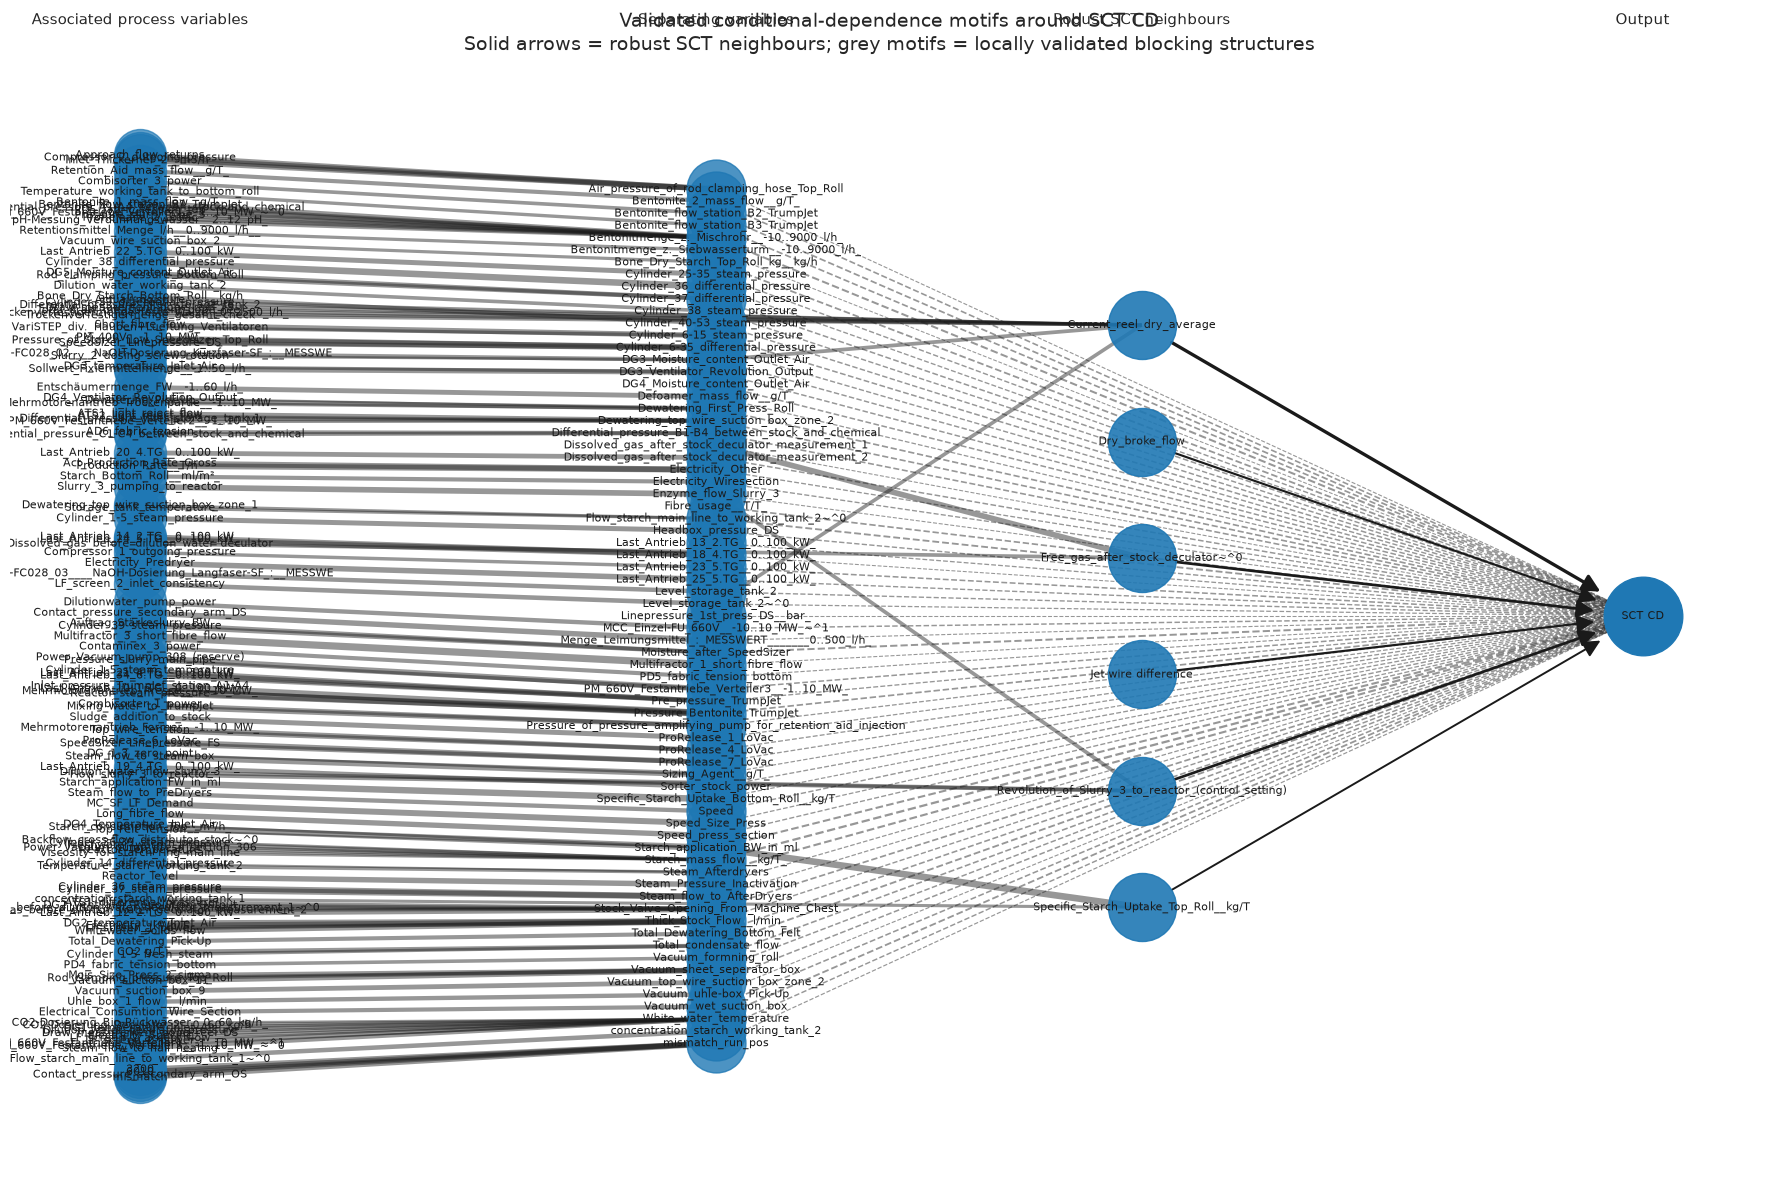

In [32]:
motifs = build_validated_sct_motifs(
    results_within,
    output_var="MBS_SCT_CD",
    min_abs_val=0.05,
)

fig, ax, G_motifs = plot_validated_sct_motifs(
    results_within,
    motifs,
    output_var="MBS_SCT_CD",
)

plt.show()

In [19]:
import json
from pathlib import Path

import pandas as pd


def plot_interactive_dependency_graph(
    results,
    output_var="MBS_SCT_CD",
    output_label="SCT CD",
    output_file="interactive_dependence_graph.html",
    height="850px",
    show_blocked_relations=True,
):
    """
    Create an interactive dependence graph.

    Rules
    -----
    1. Output is always visible.
    2. Robust neighbours are always visible.
    3. A separator is initially visible only if it is also a robust neighbour.
    4. Pure associated/blocked variables start hidden.
    5. Clicking a visible separator expands/collapses its associated variables.
    6. If show_blocked_relations=True, revealed blocked variables also get
       dashed X -> output relations.
    7. No pure separator is shown as an orphan in the collapsed graph.

    Parameters
    ----------
    results : dict
        Result dictionary from run_dependence_analysis().

    output_var : str
        Name of output variable.

    output_label : str
        Display label for output node.

    output_file : str or Path
        HTML output path.

    height : str
        HTML graph height.

    show_blocked_relations : bool
        If True, revealed blocked variables also show dashed X -> output links.

    Returns
    -------
    Path
        Path to generated HTML.
    """

    # ============================================================
    # Retrieve motif dataframe
    # ============================================================

    if "separator_motifs_df" in results:
        motifs = results["separator_motifs_df"].copy()

    else:
        analyser = results.get("analyser")

        if analyser is None:
            raise KeyError(
                "Could not find 'separator_motifs_df' or 'analyser' in results."
            )

        if not hasattr(analyser, "separator_motifs_df_"):
            raise AttributeError(
                "The analyser does not contain 'separator_motifs_df_'."
            )

        motifs = analyser.separator_motifs_df_.copy()

    # ============================================================
    # Robust neighbours
    # ============================================================

    if "output_neighbours" not in results:
        raise KeyError(
            "results does not contain 'output_neighbours'."
        )

    robust = [
        str(x)
        for x in results["output_neighbours"]
    ]

    output_var = str(output_var)

    # ============================================================
    # Validate motifs
    # ============================================================

    required_columns = {
        "associated_variable",
        "separator",
        "marginal_abs_val",
        "conditional_abs_val",
        "attenuation",
    }

    missing = (
        required_columns
        - set(motifs.columns)
    )

    if missing:
        raise ValueError(
            "separator_motifs_df is missing columns: "
            f"{sorted(missing)}"
        )

    motifs = (
        motifs
        .dropna(
            subset=[
                "associated_variable",
                "separator",
            ]
        )
        .copy()
    )

    motifs["associated_variable"] = (
        motifs["associated_variable"]
        .astype(str)
    )

    motifs["separator"] = (
        motifs["separator"]
        .astype(str)
    )

    # ============================================================
    # Roles
    # ============================================================

    separators = sorted(
        motifs["separator"]
        .drop_duplicates()
        .tolist()
    )

    associated = sorted(
        motifs["associated_variable"]
        .drop_duplicates()
        .tolist()
    )

    robust_set = set(robust)
    separator_set = set(separators)
    associated_set = set(associated)

    # ============================================================
    # Only initially meaningful nodes are included visibly
    #
    # Pure separators and pure associated vars still exist in the
    # dataset, but start hidden.
    # ============================================================

    all_names = (
        [output_var]
        + robust
        + separators
        + associated
    )

    all_names = list(
        dict.fromkeys(all_names)
    )

    node_id = {
        name: f"n{i}"
        for i, name in enumerate(all_names)
    }

    # ============================================================
    # Nodes
    # ============================================================

    nodes = []

    for name in all_names:

        # --------------------------------------------------------
        # Output
        # --------------------------------------------------------

        if name == output_var:

            nodes.append({
                "id": node_id[name],
                "label": output_label,
                "title": (
                    "<b>Output</b><br>"
                    + output_var
                ),
                "group": "output",
                "level": 3,
                "shape": "ellipse",
                "size": 32,
                "hidden": False,
            })

            continue

        # --------------------------------------------------------
        # Robust neighbour
        # --------------------------------------------------------

        if name in robust_set:

            title = (
                "<b>Robust SCT neighbour</b><br>"
                + name
            )

            if name in separator_set:

                n_children = int(
                    motifs["separator"]
                    .eq(name)
                    .sum()
                )

                title += (
                    "<br><br>"
                    "<b>Also acts as separator</b><br>"
                    f"{n_children} blocked variable"
                    f"{'' if n_children == 1 else 's'}"
                    "<br><br>"
                    "<b>Click to expand/collapse</b>"
                )

            nodes.append({
                "id": node_id[name],
                "label": name,
                "title": title,
                "group": "robust",
                "level": 2,
                "shape": "dot",
                "size": 24,
                "hidden": False,
            })

            continue

        # --------------------------------------------------------
        # Pure separator
        #
        # Important:
        # hidden initially, otherwise it becomes an orphan.
        # --------------------------------------------------------

        if name in separator_set:

            n_children = int(
                motifs["separator"]
                .eq(name)
                .sum()
            )

            title = (
                "<b>Separating variable</b><br>"
                + name
                + "<br><br>"
                + f"{n_children} blocked variable"
                + (
                    ""
                    if n_children == 1
                    else "s"
                )
            )

            nodes.append({
                "id": node_id[name],
                "label": name,
                "title": title,
                "group": "separator",
                "level": 1,
                "shape": "dot",
                "size": 18,
                "hidden": True,
            })

            continue

        # --------------------------------------------------------
        # Pure associated / blocked variable
        # --------------------------------------------------------

        if name in associated_set:

            rows = motifs[
                motifs["associated_variable"]
                == name
            ]

            row = rows.iloc[0]

            marginal_abs_val = row["marginal_abs_val"]
            conditional_abs_val = row["conditional_abs_val"]
            attenuation = row["attenuation"]
            separator_name = str(row["separator"])

            marginal_txt = (
                f"{marginal_abs_val:.3f}"
                if pd.notna(marginal_abs_val)
                else "NA"
            )

            conditional_txt = (
                f"{conditional_abs_val:.3f}"
                if pd.notna(conditional_abs_val)
                else "NA"
            )

            attenuation_txt = (
                f"{100 * attenuation:.1f}%"
                if pd.notna(attenuation)
                else "NA"
            )

            title = (
                "Blocked process variable\n"
                + name
                + "\n\n"
                + "Blocking conditioning set:\n"
                + separator_name
                + "\n\n"
                + f"|r marginal| = {marginal_txt}\n"
                + f"|r conditioned| = {conditional_txt}\n"
                + f"Attenuation = {attenuation_txt}"
            )

            nodes.append({
                "id": node_id[name],
                "label": name,
                "title": title,
                "group": "associated",
                "level": 0,
                "shape": "dot",
                "size": 11,
                "hidden": True,
            })

    # ============================================================
    # Duplicate-ID guard
    # ============================================================

    node_ids = [
        n["id"]
        for n in nodes
    ]

    if len(node_ids) != len(set(node_ids)):
        raise RuntimeError(
            "Duplicate node IDs detected."
        )

    # ============================================================
    # Edges
    # ============================================================

    edges = []
    edge_counter = 0

    # ------------------------------------------------------------
    # Robust -> output
    # ------------------------------------------------------------

    for name in robust:

        if name == output_var:
            continue

        if name not in node_id:
            continue

        edge_counter += 1

        edges.append({
            "id": f"e{edge_counter}",
            "from": node_id[name],
            "to": node_id[output_var],
            "arrows": "to",
            "width": 2.5,
            "dashes": False,
            "type": "robust",
            "hidden": False,
        })

    # ------------------------------------------------------------
    # Associated -> separator
    #
    # Always available, initially hidden.
    # ------------------------------------------------------------

    for _, row in motifs.iterrows():

        x = str(row["associated_variable"])
        z = str(row["separator"])

        if (
            x not in node_id
            or z not in node_id
        ):
            continue

        edge_counter += 1

        edges.append({
            "id": f"e{edge_counter}",
            "from": node_id[x],
            "to": node_id[z],
            "width": 1.5,
            "dashes": False,
            "type": "motif",
            "hidden": True,
        })

    # ------------------------------------------------------------
    # Optional dashed X -> output
    #
    # Initially hidden. They appear only when X is revealed.
    # ------------------------------------------------------------

    if show_blocked_relations:

        added = set()

        for _, row in motifs.iterrows():

            x = str(row["associated_variable"])

            if x == output_var:
                continue

            if x in robust_set:
                continue

            if x in added:
                continue

            if x not in node_id:
                continue

            added.add(x)

            edge_counter += 1

            edges.append({
                "id": f"e{edge_counter}",
                "from": node_id[x],
                "to": node_id[output_var],
                "arrows": "to",
                "width": 1.1,
                "dashes": True,
                "type": "blocked",
                "hidden": True,
            })

    # ============================================================
    # Separator -> children mapping
    # ============================================================

    children_by_separator = {}

    for separator, group in motifs.groupby(
        "separator",
        sort=False,
    ):

        separator = str(separator)

        if separator not in node_id:
            continue

        children = [
            node_id[str(x)]
            for x in (
                group["associated_variable"]
                .drop_duplicates()
                .tolist()
            )
            if str(x) in node_id
        ]

        children_by_separator[
            node_id[separator]
        ] = children

    # ============================================================
    # Reverse mapping:
    # child -> separators
    # ============================================================

    separators_by_child = {}

    for separator_id, children in children_by_separator.items():

        for child_id in children:

            separators_by_child.setdefault(
                child_id,
                []
            ).append(
                separator_id
            )

    # ============================================================
    # Pure associated nodes
    # ============================================================

    collapsible_nodes = {
        node_id[name]
        for name in associated
        if (
            name not in robust_set
            and name not in separator_set
            and name != output_var
        )
    }

    # ============================================================
    # Pure separators
    # ============================================================

    pure_separator_nodes = {
        node_id[name]
        for name in separators
        if (
            name not in robust_set
            and name != output_var
        )
    }

    # ============================================================
    # JSON
    # ============================================================

    nodes_json = json.dumps(
        nodes,
        ensure_ascii=False,
    )

    edges_json = json.dumps(
        edges,
        ensure_ascii=False,
    )

    children_json = json.dumps(
        children_by_separator,
        ensure_ascii=False,
    )

    separators_by_child_json = json.dumps(
        separators_by_child,
        ensure_ascii=False,
    )

    collapsible_json = json.dumps(
        list(collapsible_nodes),
        ensure_ascii=False,
    )

    pure_separator_json = json.dumps(
        list(pure_separator_nodes),
        ensure_ascii=False,
    )

    show_blocked_json = json.dumps(
        bool(show_blocked_relations)
    )

    # ============================================================
    # HTML
    # ============================================================

    html = """
<!DOCTYPE html>
<html>

<head>

<meta charset="utf-8">

<title>Interactive dependence graph</title>

<script
    type="text/javascript"
    src="https://unpkg.com/vis-network/standalone/umd/vis-network.min.js">
</script>

<style>

body {
    margin: 0;
    font-family: Arial, sans-serif;
    background: white;
}

#controls {
    padding: 10px 14px;
    border-bottom: 1px solid #ddd;
    background: #fafafa;
    display: flex;
    align-items: center;
    flex-wrap: wrap;
    gap: 8px;
}

#network {
    width: 100%;
    height: __HEIGHT__;
}

button {
    padding: 7px 12px;
    border: 1px solid #aaa;
    border-radius: 4px;
    background: white;
    cursor: pointer;
    font-size: 13px;
}

button:hover {
    background: #f0f0f0;
}

.help {
    margin-left: 10px;
    font-size: 13px;
    color: #555;
}

#status {
    margin-left: auto;
    font-size: 12px;
    color: #666;
}

</style>

</head>


<body>


<div id="controls">

    <button id="collapseAll">
        Collapse all
    </button>

    <button id="expandAll">
        Expand all
    </button>

    <button id="fitGraph">
        Fit
    </button>

    <span
        id="helpText"
        class="help">
    </span>

    <span id="status"></span>

</div>


<div id="network"></div>


<script>


const nodes = new vis.DataSet(
    __NODES_JSON__
);


const edges = new vis.DataSet(
    __EDGES_JSON__
);


const childrenBySeparator =
    __CHILDREN_JSON__;


const separatorsByChild =
    __SEPARATORS_BY_CHILD_JSON__;


const collapsibleNodes =
    new Set(
        __COLLAPSIBLE_NODES_JSON__
    );


const pureSeparatorNodes =
    new Set(
        __PURE_SEPARATOR_NODES_JSON__
    );


const showBlockedRelations =
    __SHOW_BLOCKED_RELATIONS__;


const expandedSeparators =
    new Set();


const container =
    document.getElementById(
        "network"
    );


const statusElement =
    document.getElementById(
        "status"
    );


const helpElement =
    document.getElementById(
        "helpText"
    );


const data = {
    nodes: nodes,
    edges: edges
};


const options = {

    layout: {

        hierarchical: {

            enabled: true,

            direction: "LR",

            sortMethod: "directed",

            levelSeparation: 330,

            nodeSpacing: 42,

            treeSpacing: 180,

            blockShifting: true,

            edgeMinimization: true,

            parentCentralization: true
        }
    },

    physics: {
        enabled: false
    },

    interaction: {

        hover: true,

        navigationButtons: true,

        keyboard: true,

        tooltipDelay: 150,

        zoomView: true,

        dragView: true
    },

    nodes: {

        borderWidth: 1,

        font: {
            size: 13,
            face: "Arial"
        }
    },

    groups: {

        output: {
            shape: "ellipse",
            size: 32
        },

        robust: {
            shape: "dot",
            size: 24
        },

        separator: {
            shape: "dot",
            size: 18
        },

        associated: {
            shape: "dot",
            size: 11
        }
    },

    edges: {

        smooth: {

            enabled: true,

            type: "cubicBezier",

            forceDirection: "horizontal",

            roundness: 0.25
        }
    }
};


const network =
    new vis.Network(
        container,
        data,
        options
    );


// ============================================================
// Help
// ============================================================

if (showBlockedRelations) {

    helpElement.textContent =
        "Click visible separator nodes to expand/collapse their parents. "
        + "Solid = robust relation. "
        + "Dashed = relation removed by conditioning.";

} else {

    helpElement.textContent =
        "Robust network with expandable blocking structures. "
        + "Dashed blocked relations are hidden.";
}


// ============================================================
// Child still needed by another expanded separator?
// ============================================================

function childStillNeeded(childId) {

    const parentSeparators =
        separatorsByChild[
            childId
        ] || [];

    for (
        const separatorId
        of parentSeparators
    ) {

        if (
            expandedSeparators.has(
                separatorId
            )
        ) {
            return true;
        }
    }

    return false;
}


// ============================================================
// Show/hide dashed X -> output edge
// ============================================================

function updateBlockedEdge(childId) {

    if (!showBlockedRelations) {
        return;
    }

    const node =
        nodes.get(
            childId
        );

    if (!node) {
        return;
    }

    const blockedEdges =
        edges.get({

            filter: function(edge) {

                return (
                    edge.type === "blocked"
                    &&
                    edge.from === childId
                );
            }
        });

    blockedEdges.forEach(
        edge => {

            edges.update({
                id: edge.id,
                hidden: Boolean(node.hidden)
            });
        }
    );
}


// ============================================================
// Reveal pure separator when required
// ============================================================

function revealSeparator(
    separatorId
) {

    if (
        pureSeparatorNodes.has(
            separatorId
        )
    ) {

        nodes.update({
            id: separatorId,
            hidden: false
        });
    }
}


// ============================================================
// Hide pure separator if it would become orphaned
// ============================================================

function hideSeparatorIfUnused(
    separatorId
) {

    if (
        !pureSeparatorNodes.has(
            separatorId
        )
    ) {
        return;
    }

    if (
        expandedSeparators.has(
            separatorId
        )
    ) {
        return;
    }

    nodes.update({
        id: separatorId,
        hidden: true
    });
}


// ============================================================
// Expand separator
// ============================================================

function expand(
    separatorId
) {

    const children =
        childrenBySeparator[
            separatorId
        ];

    if (!children) {
        return;
    }

    revealSeparator(
        separatorId
    );

    expandedSeparators.add(
        separatorId
    );

    children.forEach(
        childId => {

            if (
                collapsibleNodes.has(
                    childId
                )
            ) {

                nodes.update({
                    id: childId,
                    hidden: false
                });
            }

            const motifEdges =
                edges.get({

                    filter: function(edge) {

                        return (
                            edge.type === "motif"
                            &&
                            edge.from === childId
                            &&
                            edge.to === separatorId
                        );
                    }
                });

            motifEdges.forEach(
                edge => {

                    edges.update({
                        id: edge.id,
                        hidden: false
                    });
                }
            );

            updateBlockedEdge(
                childId
            );
        }
    );

    updateStatus();
}


// ============================================================
// Collapse separator
// ============================================================

function collapse(
    separatorId
) {

    const children =
        childrenBySeparator[
            separatorId
        ];

    if (!children) {
        return;
    }

    expandedSeparators.delete(
        separatorId
    );

    children.forEach(
        childId => {

            const motifEdges =
                edges.get({

                    filter: function(edge) {

                        return (
                            edge.type === "motif"
                            &&
                            edge.from === childId
                            &&
                            edge.to === separatorId
                        );
                    }
                });

            motifEdges.forEach(
                edge => {

                    edges.update({
                        id: edge.id,
                        hidden: true
                    });
                }
            );

            if (
                collapsibleNodes.has(
                    childId
                )
                &&
                !childStillNeeded(
                    childId
                )
            ) {

                nodes.update({
                    id: childId,
                    hidden: true
                });
            }

            updateBlockedEdge(
                childId
            );
        }
    );

    hideSeparatorIfUnused(
        separatorId
    );

    updateStatus();
}


// ============================================================
// Toggle
// ============================================================

function toggleSeparator(
    separatorId
) {

    if (
        expandedSeparators.has(
            separatorId
        )
    ) {

        collapse(
            separatorId
        );

    } else {

        expand(
            separatorId
        );
    }
}


// ============================================================
// Status
// ============================================================

function updateStatus() {

    statusElement.textContent =
        "Expanded separators: "
        + expandedSeparators.size;
}


// ============================================================
// Click
// ============================================================

network.on(

    "click",

    function(params) {

        if (
            params.nodes.length !== 1
        ) {
            return;
        }

        const id =
            params.nodes[0];

        if (
            !Object.prototype
                .hasOwnProperty
                .call(
                    childrenBySeparator,
                    id
                )
        ) {
            return;
        }

        toggleSeparator(
            id
        );
    }
);


// ============================================================
// Collapse all
// ============================================================

document
    .getElementById(
        "collapseAll"
    )
    .addEventListener(

        "click",

        function() {

            const expanded =
                Array.from(
                    expandedSeparators
                );

            expanded.forEach(
                separatorId => {

                    collapse(
                        separatorId
                    );
                }
            );

            network.fit({
                animation: true
            });
        }
    );


// ============================================================
// Expand all
// ============================================================

document
    .getElementById(
        "expandAll"
    )
    .addEventListener(

        "click",

        function() {

            Object.keys(
                childrenBySeparator
            ).forEach(
                separatorId => {

                    expand(
                        separatorId
                    );
                }
            );

            network.fit({
                animation: true
            });
        }
    );


// ============================================================
// Fit
// ============================================================

document
    .getElementById(
        "fitGraph"
    )
    .addEventListener(

        "click",

        function() {

            network.fit({
                animation: true
            });
        }
    );


// ============================================================
// Initial state
// ============================================================

updateStatus();


setTimeout(

    function() {

        network.fit({
            animation: false
        });

    },

    150
);


</script>

</body>

</html>
"""

    # ============================================================
    # Substitute placeholders
    # ============================================================

    html = (
        html
        .replace(
            "__HEIGHT__",
            str(height),
        )
        .replace(
            "__NODES_JSON__",
            nodes_json,
        )
        .replace(
            "__EDGES_JSON__",
            edges_json,
        )
        .replace(
            "__CHILDREN_JSON__",
            children_json,
        )
        .replace(
            "__SEPARATORS_BY_CHILD_JSON__",
            separators_by_child_json,
        )
        .replace(
            "__COLLAPSIBLE_NODES_JSON__",
            collapsible_json,
        )
        .replace(
            "__PURE_SEPARATOR_NODES_JSON__",
            pure_separator_json,
        )
        .replace(
            "__SHOW_BLOCKED_RELATIONS__",
            show_blocked_json,
        )
    )

    # ============================================================
    # Write file
    # ============================================================

    output_file = Path(
        output_file
    )

    output_file.write_text(
        html,
        encoding="utf-8",
    )

    # ============================================================
    # Diagnostics
    # ============================================================

    print(
        "Interactive graph written to:"
    )
    print(
        output_file.resolve()
    )
    print()

    print(
        "Nodes:",
        len(nodes),
    )

    print(
        "Unique node IDs:",
        len(
            {
                node["id"]
                for node in nodes
            }
        ),
    )

    print(
        "Edges:",
        len(edges),
    )

    print(
        "Robust neighbours:",
        len(robust),
    )

    print(
        "Separators:",
        len(separators),
    )

    print(
        "Pure separators initially hidden:",
        len(pure_separator_nodes),
    )

    print(
        "Associated variables:",
        len(associated),
    )

    print(
        "Motifs:",
        len(motifs),
    )

    print(
        "Show blocked relations:",
        show_blocked_relations,
    )

    return output_file

In [20]:
interactive_file = plot_interactive_dependency_graph(
    results_within,
    output_var="MBS_SCT_CD",
    output_label="SCT CD",
    output_file="interactive_dependence_graph.html",
    height="850px",
    show_blocked_relations=True
)

Interactive graph written to:
C:\workspace\costimiser\causality\interactive_dependence_graph.html

Nodes: 278
Unique node IDs: 278
Edges: 512
Robust neighbours: 6
Separators: 109
Pure separators initially hidden: 105
Associated variables: 253
Motifs: 253
Show blocked relations: True
